# Telco Customer Intelligence: Notebook Lengkap (Tahap 1 sampai 12)

Notebook ini menggabungkan seluruh alur analisis dalam satu file: dari setup, kualitas data, EDA, uji statistik, feature engineering, segmentasi, analisis churn, model prediksi, interpretabilitas, rekomendasi bisnis, sampai export artefak untuk Streamlit.

## Peta tahapan
| Tahap | Isi | Pertanyaan yang dijawab |
|---|---|---|
| 1 | Setup & upload | Apakah lingkungan dan data siap? |
| 2 | Data quality | Apa saja masalah pada data mentah? |
| 3 | EDA | Seperti apa profil pelanggan dan di mana churn terkonsentrasi? |
| 4 | Uji statistik | Apakah hubungan variabel dengan churn signifikan dan sebesar apa? |
| 5 | Feature engineering | Fitur baru apa yang dibuat dan apakah ada multikolinearitas? |
| 6 | Segmentasi | Pelanggan terbagi menjadi kelompok apa? |
| 7 | Analisis churn | Siapa yang churn, kapan, dan faktor apa yang berasosiasi setelah dikontrol? |
| 8 | Model prediksi | Model apa yang terbaik memprediksi churn? |
| 9 | Interpretabilitas | Fitur apa yang paling memengaruhi prediksi? |
| 10 | Intelligence bisnis | Pelanggan mana yang diprioritaskan dan apa tindakannya? |
| 11 | Laporan akhir | Ringkasan temuan otomatis |
| 12 | Export & verifikasi | Apakah model tersimpan bisa dipakai untuk pelanggan baru? |

## Cara memakai
1. Buka di Google Colab (Runtime Python 3).
2. Jalankan sel **secara berurutan dari atas**. Banyak sel bergantung pada variabel dari sel sebelumnya.
3. Saat Sel upload muncul, pilih file `WA_Fn-UseC_-Telco-Customer-Churn.csv`.
4. Jika ada error, baca pesan terakhir pada traceback, lalu cek apakah sel sebelumnya sudah dijalankan.

## Prinsip desain yang dipakai di seluruh notebook
- **Reproducible**: seed global `RANDOM_STATE = 42`.
- **Tanpa kebocoran data (data leakage)**: preprocessing ada di dalam `Pipeline`, test set tidak dipakai memilih model, threshold dipilih dari prediksi out-of-fold.
- **Churn tidak dipakai membentuk cluster**: hanya dipakai untuk evaluasi setelah cluster jadi.
- **Asosiasi bukan kausalitas**: semua temuan adalah hubungan statistik.
- **Keputusan analis bersifat eksplisit**: nilai seperti `K_FINAL`, `THRESHOLD`, `RISK_Q_HIGH` dapat Anda timpa.

---
# TAHAP 1: Setup Environment dan Upload Dataset

**Tujuan:** menyiapkan lingkungan kerja yang reproducible (library, seed, folder output) dan membaca dataset apa adanya, tanpa perubahan apa pun. Masalah kualitas data baru dicari di Tahap 2.

**Konsep penting:** `df_raw` adalah data mentah yang tidak pernah diubah. Semua tahap lain bekerja pada salinan, sehingga Anda selalu bisa kembali ke data asli.

### Sel 1: Instalasi library tambahan
Colab sudah punya pandas, numpy, scikit-learn, scipy, statsmodels, matplotlib, seaborn, plotly, dan xgboost. Yang dipasang hanya library berikut:

| Library | Fungsi |
|---|---|
| `shap` | Interpretasi model (Tahap 9) |
| `kmodes` | K-Prototypes untuk data campuran numerik dan kategorikal |
| `gower` | Jarak Gower untuk data campuran |
| `scikit-learn-extra` | K-Medoids |
| `imbalanced-learn` | SMOTE di dalam fold training |
| `yellowbrick` | Visualisasi evaluasi clustering (opsional) |

Jika muncul peringatan "Restart session", jalankan *Runtime → Restart session*, lalu lanjut ke Sel 2 tanpa mengulang Sel 1.

In [ ]:
# Instalasi library tambahan (hanya yang belum tersedia di Colab)
#!pip install -q shap kmodes gower scikit-learn-extra imbalanced-learn yellowbrick

### Sel 2: Import library, konfigurasi global, versi environment
- `RANDOM_STATE = 42` dipakai di semua tahap agar hasil bisa diulang.
- `pd.set_option(...)` mengatur tampilan tabel (jumlah kolom, format angka).
- Versi library dicatat untuk reproducibility. Library opsional dicek dengan `try/except` agar notebook tidak error jika ada yang gagal terpasang.

In [ ]:
import os
import sys
import json
import warnings
import platform
from datetime import datetime

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
import statsmodels
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px
import joblib

warnings.filterwarnings("ignore")

# ---------- Konfigurasi global ----------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

# ---------- Catat versi environment (penting untuk reproducibility) ----------
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "statsmodels": statsmodels.__version__,
    "scikit-learn": sklearn.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "plotly": plotly.__version__,
    "joblib": joblib.__version__,
}

# Library opsional: dicek keberadaannya, tidak membuat notebook error jika gagal
for lib in ["shap", "xgboost", "kmodes", "gower", "imblearn", "yellowbrick"]:
    try:
        module = __import__(lib)
        versions[lib] = getattr(module, "__version__", "terpasang")
    except Exception as e:
        versions[lib] = f"TIDAK TERSEDIA ({type(e).__name__})"

try:
    from sklearn_extra.cluster import KMedoids
    versions["scikit-learn-extra"] = "terpasang"
except Exception as e:
    versions["scikit-learn-extra"] = f"TIDAK TERSEDIA ({type(e).__name__})"

print(f"RANDOM_STATE : {RANDOM_STATE}")
print(f"Waktu run    : {datetime.now():%Y-%m-%d %H:%M:%S}\n")
print(pd.Series(versions, name="versi").to_string())

RANDOM_STATE : 42
Waktu run    : 2026-11-26 05:18:47

python                                             3.13.18
numpy                                                2.4.6
pandas                                               2.2.3
scipy                                               1.16.3
statsmodels                                         0.15.0
scikit-learn                                         1.6.1
matplotlib                                          3.10.0
seaborn                                             0.13.2
plotly                                              5.24.1
joblib                                               1.6.0
shap                                                0.54.1
xgboost                                              3.4.1
kmodes                TIDAK TERSEDIA (ModuleNotFoundError)
gower                 TIDAK TERSEDIA (ModuleNotFoundError)
imblearn                                            0.14.2
yellowbrick                                            1.5
sc

### Sel 3: Struktur folder output
Setiap jenis artefak punya folder sendiri (data, model, metrik, gambar, segmentasi, interpretasi, bisnis, metadata). Dictionary `PATHS` dipakai di seluruh notebook untuk menyimpan file, sehingga Anda tidak perlu menulis path manual.

In [ ]:
BASE_DIR = "/content/telco_customer_intelligence"

SUBDIRS = {
    "data_raw":      "data/raw",
    "data_clean":    "data/processed",
    "models":        "models",
    "metrics":       "reports/metrics",
    "figures":       "reports/figures",
    "segmentation":  "reports/segmentation",
    "interpret":     "reports/interpretability",
    "business":      "reports/business",
    "metadata":      "metadata",
}

PATHS = {}
for key, rel in SUBDIRS.items():
    full = os.path.join(BASE_DIR, rel)
    os.makedirs(full, exist_ok=True)
    PATHS[key] = full

print("Struktur folder output:\n")
for root, dirs, _ in os.walk(BASE_DIR):
    level = root.replace(BASE_DIR, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root) or BASE_DIR}/")

Struktur folder output:

telco_customer_intelligence/
    metadata/
    data/
        raw/
        processed/
    reports/
        metrics/
        figures/
        interpretability/
        business/
        segmentation/
    models/


### Sel 4: Upload dataset dan pembacaan otomatis
`files.upload()` membuka dialog unggah. Kode lalu:
1. memvalidasi bahwa ada file `.csv`,
2. mengambil nama file otomatis (tidak perlu hardcode),
3. membaca ke `df_raw` tanpa mengubah isi,
4. menyimpan salinan mentah dan metadata sesi.

In [ ]:
from google.colab import files

print("Silakan pilih file CSV Telco Customer Churn (WA_Fn-UseC_-Telco-Customer-Churn.csv):")
uploaded = files.upload()

# ---------- Validasi hasil upload ----------
if len(uploaded) == 0:
    raise FileNotFoundError("Tidak ada file yang diunggah. Jalankan ulang sel ini dan pilih file CSV.")

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if len(csv_files) == 0:
    raise ValueError(f"Tidak ada file .csv di antara file yang diunggah: {list(uploaded.keys())}")

if len(csv_files) > 1:
    print(f"Peringatan: ditemukan {len(csv_files)} file CSV {csv_files}. File pertama yang dipakai.")

DATA_FILE = csv_files[0]          # nama file otomatis, tidak perlu diubah manual
print(f"\nFile yang digunakan: {DATA_FILE}")

# ---------- Baca data mentah ----------
df_raw = pd.read_csv(DATA_FILE)

# Simpan salinan data mentah sebagai arsip
raw_copy_path = os.path.join(PATHS["data_raw"], "telco_raw.csv")
df_raw.to_csv(raw_copy_path, index=False)
print(f"Salinan data mentah disimpan di: {raw_copy_path}")

# Simpan metadata sesi untuk jejak reproducibility
session_meta = {
    "source_file": DATA_FILE,
    "n_rows_raw": int(df_raw.shape[0]),
    "n_cols_raw": int(df_raw.shape[1]),
    "random_state": RANDOM_STATE,
    "run_timestamp": datetime.now().isoformat(timespec="seconds"),
    "library_versions": versions,
}
with open(os.path.join(PATHS["metadata"], "session_info.json"), "w") as f:
    json.dump(session_meta, f, indent=2)

Silakan pilih file CSV Telco Customer Churn (WA_Fn-UseC_-Telco-Customer-Churn.csv):


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv

File yang digunakan: WA_Fn-UseC_-Telco-Customer-Churn.csv
Salinan data mentah disimpan di: /content/telco_customer_intelligence/data/raw/telco_raw.csv


### Sel 5: Verifikasi awal pembacaan data
Hanya memastikan dimensi (harusnya 7.043 baris x 21 kolom) dan sampel baris terbaca benar.

In [ ]:
print(f"Dimensi data mentah : {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom\n")
print("Daftar kolom:")
print(list(df_raw.columns))
print("\n5 observasi pertama:")
display(df_raw.head())

Dimensi data mentah : 7,043 baris x 21 kolom

Daftar kolom:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

5 observasi pertama:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


---
# TAHAP 2: Data Understanding dan Data Quality Assessment

**Tujuan:** mengidentifikasi masalah kualitas data **tanpa mengubah `df_raw`**. Keputusan penanganan dibuat di Tahap 5.

**Temuan utama dari data ini (sudah terverifikasi dari output Anda):**
- `TotalCharges` bertipe teks karena 11 nilai berupa spasi `" "`. Semuanya pelanggan `tenure = 0` (belum pernah ditagih), sehingga diisi **0**.
- Tidak ada duplikasi penuh, ID ganda, outlier IQR, atau pelanggaran logika bisnis.
- Kategori "No internet service" dan "No phone service" redundan dengan kolom induknya.
- `TotalCharges` hampir identik dengan `tenure x MonthlyCharges` (korelasi 0,9996), jadi ada redundansi.
- Target `Churn`: 26,54% Yes, rasio 2,77:1 (imbalance sedang).

### Sel 6: Struktur dan tipe data
Melihat dimensi, tipe tiap kolom, jumlah nilai unik, dan contoh nilai. Tujuannya menemukan kolom yang tipenya tidak sesuai isinya.

In [ ]:
print(f"Jumlah baris  : {df_raw.shape[0]:,}")
print(f"Jumlah kolom  : {df_raw.shape[1]}")
print(f"Memori        : {df_raw.memory_usage(deep=True).sum() / 1024**2:.2f} MB\n")

info_tbl = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "contoh_nilai": [df_raw[c].dropna().iloc[0] for c in df_raw.columns],
})
display(info_tbl)

print("\nRingkasan tipe data:")
print(df_raw.dtypes.value_counts().to_string())

Jumlah baris  : 7,043
Jumlah kolom  : 21
Memori        : 6.82 MB



,dtype,n_unique,contoh_nilai
customerID,object,7043,7590-VHVEG
gender,object,2,Female
SeniorCitizen,int64,2,0
Partner,object,2,Yes
Dependents,object,2,No
tenure,int64,73,1
PhoneService,object,2,No
MultipleLines,object,3,No phone service
InternetService,object,3,DSL
OnlineSecurity,object,3,No



Ringkasan tipe data:
object     18
int64       2
float64     1


### Sel 7: Missing values, termasuk yang tersembunyi
`isnull()` hanya menangkap `NaN`. Nilai kosong sering menyamar sebagai string kosong atau spasi, jadi kolom teks diperiksa dengan `.str.strip().eq("")`.

In [ ]:
# 1) Missing value standar (NaN)
na_std = df_raw.isnull().sum()

# 2) Missing value tersembunyi: string kosong / hanya spasi pada kolom teks
obj_cols = df_raw.select_dtypes(include="object").columns
na_hidden = {
    c: int(df_raw[c].astype(str).str.strip().eq("").sum())
    for c in obj_cols
}
na_hidden = pd.Series(na_hidden).reindex(df_raw.columns).fillna(0).astype(int)

miss_tbl = pd.DataFrame({
    "NaN_standar": na_std,
    "kosong_atau_spasi": na_hidden,
})
miss_tbl["total_bermasalah"] = miss_tbl.sum(axis=1)
miss_tbl["persen"] = miss_tbl["total_bermasalah"] / len(df_raw) * 100

print("Kolom dengan masalah missing value:")
display(miss_tbl[miss_tbl["total_bermasalah"] > 0])

if (miss_tbl["total_bermasalah"] == 0).all():
    print("Tidak ditemukan missing value.")

Kolom dengan masalah missing value:


,NaN_standar,kosong_atau_spasi,total_bermasalah,persen
TotalCharges,0,11,11,0.1562


### Sel 8: Investigasi `TotalCharges`
Kolom dikonversi ke numerik **pada salinan** dengan `errors="coerce"` (nilai gagal menjadi NaN), lalu baris bermasalah diperiksa untuk memahami polanya. Hasilnya: semua `tenure = 0` dan `Churn = No`, jadi nilai kosongnya bukan acak.

In [ ]:
tmp = df_raw.copy()
tmp["TotalCharges_num"] = pd.to_numeric(tmp["TotalCharges"], errors="coerce")

bad = tmp[tmp["TotalCharges_num"].isna()]
print(f"Dtype asli TotalCharges           : {df_raw['TotalCharges'].dtype}")
print(f"Jumlah nilai gagal dikonversi     : {len(bad)}")
print(f"Nilai asli pada baris bermasalah  : {bad['TotalCharges'].unique().tolist()}\n")

if len(bad) > 0:
    print("Baris bermasalah (kolom relevan):")
    display(bad[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

    print("\nDistribusi tenure pada baris bermasalah:")
    print(bad["tenure"].value_counts().to_string())
    print("\nDistribusi Churn pada baris bermasalah:")
    print(bad["Churn"].value_counts().to_string())

# Perbandingan: apakah ada pelanggan tenure = 0 yang TotalCharges-nya valid?
print(f"\nTotal pelanggan dengan tenure = 0 : {(df_raw['tenure'] == 0).sum()}")

Dtype asli TotalCharges           : object
Jumlah nilai gagal dikonversi     : 11
Nilai asli pada baris bermasalah  : [' ']

Baris bermasalah (kolom relevan):


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.5500,,Two year,No
753,3115-CZMZD,0,20.2500,,Two year,No
936,5709-LVOEQ,0,80.8500,,Two year,No
1082,4367-NUYAO,0,25.7500,,Two year,No
1340,1371-DWPAZ,0,56.0500,,Two year,No
3331,7644-OMVMY,0,19.8500,,Two year,No
3826,3213-VVOLG,0,25.3500,,Two year,No
4380,2520-SGTTA,0,20.0000,,Two year,No
5218,2923-ARZLG,0,19.7000,,One year,No
6670,4075-WKNIU,0,73.3500,,Two year,No



Distribusi tenure pada baris bermasalah:
tenure
0    11

Distribusi Churn pada baris bermasalah:
Churn
No    11

Total pelanggan dengan tenure = 0 : 11


### Sel 9: Duplikasi data
Tiga level: baris identik penuh, `customerID` ganda, dan baris identik selain `customerID`. Level ketiga (22 baris) bukan duplikasi sebenarnya, karena pelanggan berbeda bisa kebetulan punya profil sama.

In [ ]:
n_full_dup = df_raw.duplicated().sum()
n_id_dup = df_raw["customerID"].duplicated().sum()
n_feat_dup = df_raw.drop(columns="customerID").duplicated().sum()

print(f"Baris duplikat penuh (semua kolom)      : {n_full_dup}")
print(f"customerID duplikat                      : {n_id_dup}")
print(f"Baris identik selain customerID          : {n_feat_dup} "
      f"({n_feat_dup / len(df_raw) * 100:.2f}%)")
print(f"customerID unik                          : {df_raw['customerID'].nunique():,} dari {len(df_raw):,}")

Baris duplikat penuh (semua kolom)      : 0
customerID duplikat                      : 0
Baris identik selain customerID          : 22 (0.31%)
customerID unik                          : 7,043 dari 7,043


### Sel 10: Nilai unik variabel kategorikal
Mencari salah ketik, perbedaan kapitalisasi, spasi berlebih, dan kategori langka. Pada data ini semuanya konsisten.

In [ ]:
cat_cols = [c for c in df_raw.select_dtypes(include="object").columns
            if c not in ["customerID", "TotalCharges"]]
# SeniorCitizen bertipe int tetapi bermakna biner/kategorikal, ikut diperiksa
cat_cols_check = cat_cols + ["SeniorCitizen"]

for c in cat_cols_check:
    vc = df_raw[c].value_counts(dropna=False)
    print(f"--- {c} ({len(vc)} nilai unik) ---")
    print(pd.DataFrame({"n": vc, "persen": (vc / len(df_raw) * 100).round(2)}).to_string())
    print()

--- gender (2 nilai unik) ---
           n  persen
gender              
Male    3555 50.4800
Female  3488 49.5200

--- Partner (2 nilai unik) ---
            n  persen
Partner              
No       3641 51.7000
Yes      3402 48.3000

--- Dependents (2 nilai unik) ---
               n  persen
Dependents              
No          4933 70.0400
Yes         2110 29.9600

--- PhoneService (2 nilai unik) ---
                 n  persen
PhoneService              
Yes           6361 90.3200
No             682  9.6800

--- MultipleLines (3 nilai unik) ---
                     n  persen
MultipleLines                 
No                3390 48.1300
Yes               2971 42.1800
No phone service   682  9.6800

--- InternetService (3 nilai unik) ---
                    n  persen
InternetService              
Fiber optic      3096 43.9600
DSL              2421 34.3700
No               1526 21.6700

--- OnlineSecurity (3 nilai unik) ---
                        n  persen
OnlineSecurity                

### Sel 11: Distribusi variabel numerik
Statistik deskriptif ditambah **skewness** (kemiringan) dan **kurtosis** (ketebalan ekor). Histogram dan boxplot disimpan ke folder figures. `TotalCharges` miring ke kanan (skew 0,96), sehingga uji nonparametrik lebih tepat di Tahap 4.

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,n_missing
tenure,"7,043.0000",32.3711,24.5595,0.0000,9.0000,29.0000,55.0000,72.0000,0.2395,-1.3874,0
MonthlyCharges,"7,043.0000",64.7617,30.0900,18.2500,35.5000,70.3500,89.8500,118.7500,-0.2205,-1.2573,0
TotalCharges,"7,032.0000","2,283.3004","2,266.7714",18.8000,401.4500,"1,397.4750","3,794.7375","8,684.8000",0.9616,-0.2318,11


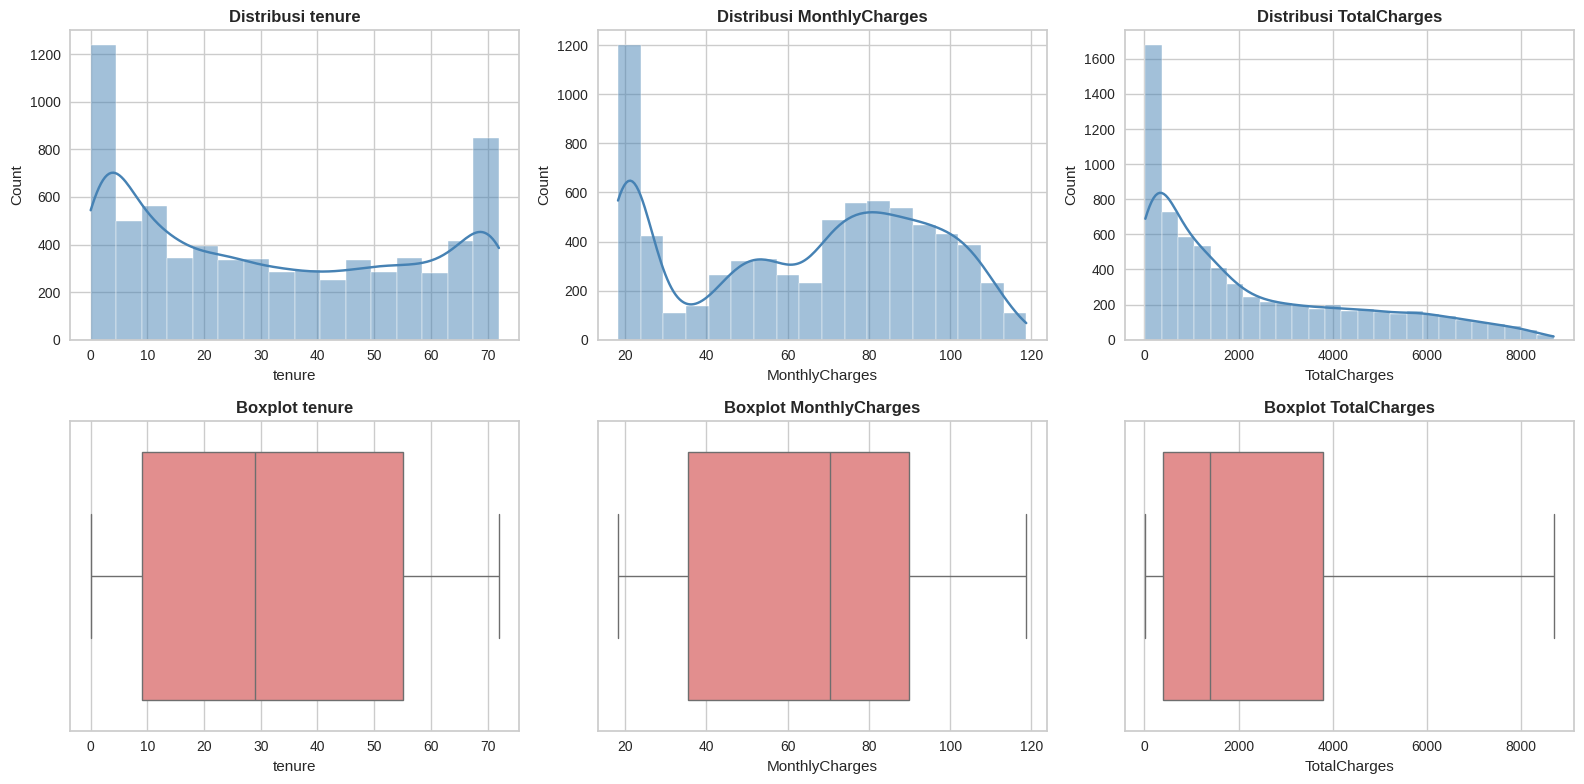

In [ ]:
num_df = df_raw[["tenure", "MonthlyCharges"]].copy()
num_df["TotalCharges"] = pd.to_numeric(df_raw["TotalCharges"], errors="coerce")

desc = num_df.describe().T
desc["skewness"] = num_df.skew()
desc["kurtosis"] = num_df.kurt()
desc["n_missing"] = num_df.isna().sum()
display(desc)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, c in enumerate(num_df.columns):
    sns.histplot(num_df[c].dropna(), kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Distribusi {c}")
    sns.boxplot(x=num_df[c].dropna(), ax=axes[1, i], color="lightcoral")
    axes[1, i].set_title(f"Boxplot {c}")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["figures"], "02_distribusi_numerik.png"), dpi=150, bbox_inches="tight")
plt.show()

### Sel 12: Deteksi outlier (aturan IQR)
Nilai di luar `Q1 - 1,5*IQR` atau `Q3 + 1,5*IQR` ditandai sebagai outlier. Ini penanda, bukan dasar penghapusan. Hasil pada data ini: 0 outlier.

In [ ]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    return pd.Series({
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "batas_bawah": lo, "batas_atas": hi,
        "n_outlier": n_out, "persen_outlier": n_out / len(s) * 100,
    })

out_tbl = num_df.apply(iqr_outliers).T
display(out_tbl)

,Q1,Q3,IQR,batas_bawah,batas_atas,n_outlier,persen_outlier
tenure,9.0000,55.0000,46.0000,-60.0000,124.0000,0.0000,0.0000
MonthlyCharges,35.5000,89.8500,54.3500,-46.0250,171.3750,0.0000,0.0000
TotalCharges,401.4500,"3,794.7375","3,393.2875","-4,688.4813","8,884.6688",0.0000,0.0000


### Sel 13: Konsistensi nilai dan logika bisnis
Aturan yang seharusnya selalu benar: pelanggan tanpa internet harus bernilai "No internet service" pada enam layanan tambahan; tanpa telepon harus "No phone service" pada MultipleLines; `TotalCharges` mendekati `tenure x MonthlyCharges`. Semua aturan terpenuhi (0 pelanggaran).

In [ ]:
d = df_raw.copy()
d["TotalCharges_num"] = pd.to_numeric(d["TotalCharges"], errors="coerce")

# Aturan 1: tanpa layanan internet -> semua layanan tambahan internet harus "No internet service"
inet_addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
               "TechSupport", "StreamingTV", "StreamingMovies"]
no_inet = d[d["InternetService"] == "No"]
print(f"Pelanggan tanpa internet: {len(no_inet):,}")
for c in inet_addons:
    n_viol = (no_inet[c] != "No internet service").sum()
    print(f"  Pelanggaran {c:<18}: {n_viol}")

# Aturan 2: tanpa telepon -> MultipleLines harus "No phone service"
no_phone = d[d["PhoneService"] == "No"]
print(f"\nPelanggan tanpa telepon: {len(no_phone):,}")
print(f"  Pelanggaran MultipleLines: {(no_phone['MultipleLines'] != 'No phone service').sum()}")

# Aturan 3: kebalikan -> ada layanan internet tetapi nilainya 'No internet service'
has_inet = d[d["InternetService"] != "No"]
viol3 = sum((has_inet[c] == "No internet service").sum() for c in inet_addons)
print(f"\nPelanggan ber-internet bernilai 'No internet service': {viol3}")

# Aturan 4: TotalCharges vs tenure x MonthlyCharges
d["expected_total"] = d["tenure"] * d["MonthlyCharges"]
d["selisih"] = d["TotalCharges_num"] - d["expected_total"]
d["selisih_pct"] = d["selisih"] / d["expected_total"].replace(0, np.nan) * 100

print("\nSelisih TotalCharges vs (tenure x MonthlyCharges):")
print(d["selisih"].describe().to_string())
print(f"\nBaris dengan |selisih| > 20% dari nilai harapan: {(d['selisih_pct'].abs() > 20).sum()}")
print(f"Korelasi TotalCharges vs tenure x MonthlyCharges: "
      f"{d[['TotalCharges_num', 'expected_total']].corr().iloc[0, 1]:.4f}")

# Aturan 5: rentang nilai wajar
print(f"\ntenure min/max          : {d['tenure'].min()} / {d['tenure'].max()}")
print(f"MonthlyCharges min/max  : {d['MonthlyCharges'].min()} / {d['MonthlyCharges'].max()}")
print(f"Nilai negatif ditemukan : {(d[['tenure','MonthlyCharges']] < 0).any().any()}")

Pelanggan tanpa internet: 1,526
  Pelanggaran OnlineSecurity    : 0
  Pelanggaran OnlineBackup      : 0
  Pelanggaran DeviceProtection  : 0
  Pelanggaran TechSupport       : 0
  Pelanggaran StreamingTV       : 0
  Pelanggaran StreamingMovies   : 0

Pelanggan tanpa telepon: 682
  Pelanggaran MultipleLines: 0

Pelanggan ber-internet bernilai 'No internet service': 0

Selisih TotalCharges vs (tenure x MonthlyCharges):
count   7,032.0000
mean        0.1532
std        67.2553
min      -370.8500
25%       -28.6500
50%         0.0000
75%        28.7000
max       373.2500

Baris dengan |selisih| > 20% dari nilai harapan: 59
Korelasi TotalCharges vs tenure x MonthlyCharges: 0.9996

tenure min/max          : 0 / 72
MonthlyCharges min/max  : 18.25 / 118.75
Nilai negatif ditemukan : False


### Sel 14: Identifier, target, dan peran variabel
Menetapkan peran tiap kolom: identifier (`customerID`), target (`Churn`), numerik, biner, atau kategorikal lebih dari 2 nilai. Juga menghitung rasio kelas target.

In [ ]:
# Target
target_col = "Churn"
print("Distribusi target (Churn):")
tc = df_raw[target_col].value_counts()
print(pd.DataFrame({"n": tc, "persen": (tc / len(df_raw) * 100).round(2)}).to_string())
print(f"\nRasio kelas (mayoritas : minoritas) = {tc.max() / tc.min():.2f} : 1")

# Identifier
print(f"\ncustomerID unik penuh? {df_raw['customerID'].is_unique}")
print(f"Contoh format ID      : {df_raw['customerID'].head(3).tolist()}")

# Peran variabel (otomatis dari data)
id_cols = ["customerID"]
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
binary_cols = [c for c in df_raw.columns
               if c not in id_cols + numeric_cols + [target_col]
               and df_raw[c].nunique() == 2]
multi_cols = [c for c in df_raw.columns
              if c not in id_cols + numeric_cols + [target_col] + binary_cols]

role_tbl = pd.DataFrame({
    "peran": (["identifier"] * len(id_cols) + ["target"] +
              ["numerik"] * len(numeric_cols) +
              ["biner"] * len(binary_cols) +
              ["kategorikal (>2 nilai)"] * len(multi_cols)),
    "kolom": id_cols + [target_col] + numeric_cols + binary_cols + multi_cols,
})
display(role_tbl.groupby("peran")["kolom"].apply(list).reset_index())

Distribusi target (Churn):
          n  persen
Churn              
No     5174 73.4600
Yes    1869 26.5400

Rasio kelas (mayoritas : minoritas) = 2.77 : 1

customerID unik penuh? True
Contoh format ID      : ['7590-VHVEG', '5575-GNVDE', '3668-QPYBK']


,peran,kolom
0,biner,"[gender, SeniorCitizen, Partner, Dependents, P..."
1,identifier,[customerID]
2,kategorikal (>2 nilai),"[MultipleLines, InternetService, OnlineSecurit..."
3,numerik,"[tenure, MonthlyCharges, TotalCharges]"
4,target,[Churn]


### Sel 15: Data dictionary
Tabel yang menjelaskan fungsi tiap variabel. Kolom `catatan_kualitas` sengaja dikosongkan dan diisi di Sel 16 setelah temuan diketahui.

In [ ]:
data_dictionary = pd.DataFrame([
    ("customerID",       "Identifier",  "ID unik pelanggan. Tidak digunakan sebagai fitur model."),
    ("gender",           "Demografi",   "Jenis kelamin pelanggan (Female/Male)."),
    ("SeniorCitizen",    "Demografi",   "Apakah pelanggan lansia (1 = ya, 0 = tidak)."),
    ("Partner",          "Demografi",   "Apakah pelanggan memiliki pasangan (Yes/No)."),
    ("Dependents",       "Demografi",   "Apakah pelanggan memiliki tanggungan (Yes/No)."),
    ("tenure",           "Akun",        "Lama berlangganan dalam bulan."),
    ("PhoneService",     "Layanan",     "Apakah pelanggan memiliki layanan telepon (Yes/No)."),
    ("MultipleLines",    "Layanan",     "Apakah memiliki beberapa jalur telepon (Yes/No/No phone service)."),
    ("InternetService",  "Layanan",     "Jenis layanan internet (DSL/Fiber optic/No)."),
    ("OnlineSecurity",   "Layanan",     "Layanan keamanan online (Yes/No/No internet service)."),
    ("OnlineBackup",     "Layanan",     "Layanan backup online (Yes/No/No internet service)."),
    ("DeviceProtection", "Layanan",     "Proteksi perangkat (Yes/No/No internet service)."),
    ("TechSupport",      "Layanan",     "Dukungan teknis (Yes/No/No internet service)."),
    ("StreamingTV",      "Layanan",     "Layanan streaming TV (Yes/No/No internet service)."),
    ("StreamingMovies",  "Layanan",     "Layanan streaming film (Yes/No/No internet service)."),
    ("Contract",         "Akun",        "Jenis kontrak (Month-to-month/One year/Two year)."),
    ("PaperlessBilling", "Akun",        "Apakah menggunakan tagihan tanpa kertas (Yes/No)."),
    ("PaymentMethod",    "Akun",        "Metode pembayaran (Electronic check/Mailed check/Bank transfer/Credit card)."),
    ("MonthlyCharges",   "Finansial",   "Tagihan bulanan saat ini."),
    ("TotalCharges",     "Finansial",   "Total tagihan selama berlangganan."),
    ("Churn",            "Target",      "Apakah pelanggan berhenti berlangganan (Yes/No)."),
], columns=["variabel", "kategori", "deskripsi"])

data_dictionary["tipe_asli"] = data_dictionary["variabel"].map(df_raw.dtypes.astype(str))
data_dictionary["n_unique"] = data_dictionary["variabel"].map(df_raw.nunique())
data_dictionary["catatan_kualitas"] = ""   # diisi di Sel 16

display(data_dictionary)

,variabel,kategori,deskripsi,tipe_asli,n_unique,catatan_kualitas
0,customerID,Identifier,ID unik pelanggan. Tidak digunakan sebagai fit...,object,7043,
1,gender,Demografi,Jenis kelamin pelanggan (Female/Male).,object,2,
2,SeniorCitizen,Demografi,"Apakah pelanggan lansia (1 = ya, 0 = tidak).",int64,2,
3,Partner,Demografi,Apakah pelanggan memiliki pasangan (Yes/No).,object,2,
4,Dependents,Demografi,Apakah pelanggan memiliki tanggungan (Yes/No).,object,2,
5,tenure,Akun,Lama berlangganan dalam bulan.,int64,73,
6,PhoneService,Layanan,Apakah pelanggan memiliki layanan telepon (Yes...,object,2,
7,MultipleLines,Layanan,Apakah memiliki beberapa jalur telepon (Yes/No...,object,3,
8,InternetService,Layanan,Jenis layanan internet (DSL/Fiber optic/No).,object,3,
9,OnlineSecurity,Layanan,Layanan keamanan online (Yes/No/No internet se...,object,3,


### Sel 16: Isi catatan kualitas dan simpan data dictionary
Catatan kualitas ditulis dari temuan Sel 6 sampai 14, lalu data dictionary disimpan ke CSV (dengan encoding `utf-8-sig` agar terbaca benar di Excel).

**Ringkasan keputusan preprocessing dari Tahap 2:**
| Masalah | Keputusan |
|---|---|
| `TotalCharges` bertipe teks | Konversi ke numerik |
| 11 nilai kosong (tenure = 0) | Isi 0, pertahankan baris |
| "No internet/phone service" redundan | Dinormalisasi menjadi "No" di Tahap 5 |
| Redundansi tenure, MonthlyCharges, TotalCharges | Dipertimbangkan saat memilih fitur clustering dan model |
| Outlier, duplikasi profil | Tidak ada tindakan |
| Distribusi tidak normal | Uji nonparametrik |
| Imbalance 2,77:1 | Class weighting, metrik PR-AUC dan recall |

In [ ]:
notes = {
    "customerID":       "Unik penuh (7.043). Hanya identitas, bukan fitur model.",
    "SeniorCitizen":    "Bertipe int tetapi bermakna biner; perlakukan sebagai kategorikal.",
    "tenure":           "11 pelanggan bernilai 0 (belum pernah ditagih). Distribusi datar, 0 outlier.",
    "MultipleLines":    "'No phone service' (682) redundan dengan PhoneService = No.",
    "OnlineSecurity":   "'No internet service' (1.526) redundan dengan InternetService = No.",
    "OnlineBackup":     "'No internet service' (1.526) redundan dengan InternetService = No.",
    "DeviceProtection": "'No internet service' (1.526) redundan dengan InternetService = No.",
    "TechSupport":      "'No internet service' (1.526) redundan dengan InternetService = No.",
    "StreamingTV":      "'No internet service' (1.526) redundan dengan InternetService = No.",
    "StreamingMovies":  "'No internet service' (1.526) redundan dengan InternetService = No.",
    "MonthlyCharges":   "Tidak ada missing/outlier. Tagihan saat ini; korelasi tinggi dengan TotalCharges.",
    "TotalCharges":     "Bertipe teks; 11 nilai ' ' (semua tenure=0, Churn=No). Miring kanan (skew 0,96). "
                        "Korelasi 0,9996 dengan tenure x MonthlyCharges.",
    "Churn":            "Target. 26,54% Yes; rasio kelas 2,77:1 (imbalance sedang).",
}
data_dictionary["catatan_kualitas"] = data_dictionary["variabel"].map(notes).fillna("Tidak ada masalah ditemukan.")

dd_path = os.path.join(PATHS["metadata"], "data_dictionary.csv")
data_dictionary.to_csv(dd_path, index=False, encoding="utf-8-sig")
print(f"Data dictionary disimpan di: {dd_path}")
display(data_dictionary[["variabel", "catatan_kualitas"]])

Data dictionary disimpan di: /content/telco_customer_intelligence/metadata/data_dictionary.csv


,variabel,catatan_kualitas
0,customerID,"Unik penuh (7.043). Hanya identitas, bukan fit..."
1,gender,Tidak ada masalah ditemukan.
2,SeniorCitizen,Bertipe int tetapi bermakna biner; perlakukan ...
3,Partner,Tidak ada masalah ditemukan.
4,Dependents,Tidak ada masalah ditemukan.
5,tenure,11 pelanggan bernilai 0 (belum pernah ditagih)...
6,PhoneService,Tidak ada masalah ditemukan.
7,MultipleLines,'No phone service' (682) redundan dengan Phone...
8,InternetService,Tidak ada masalah ditemukan.
9,OnlineSecurity,'No internet service' (1.526) redundan dengan ...


---
# TAHAP 3: Exploratory Data Analysis (EDA)

**Tujuan:** memahami profil pelanggan dan melihat di mana churn terkonsentrasi. Urutannya: demografi, tenure, layanan, finansial, kontrak dan pembayaran, lalu eksplorasi churn.

**Istilah yang dipakai:**
- **churn rate**: persentase pelanggan yang churn dalam suatu kelompok.
- **lift**: churn rate kelompok dibagi churn rate keseluruhan. Lift 1,5 berarti 1,5x lebih tinggi dari rata-rata.
- **gap_pp**: selisih churn rate kategori tertinggi dan terendah (dalam *percentage point*).

### Sel 17: Dataset kerja EDA dan fungsi bantu
`df` adalah salinan kerja dengan perbaikan minimal (TotalCharges numerik, 11 kosong diisi 0). Tiga fungsi bantu dibuat sekali dan dipakai ulang:
- `churn_table(col)`: tabel jumlah, churn rate, porsi, dan lift per kategori.
- `plot_cat(cols, fname)`: grafik proporsi dan churn rate per kategori.
- `auto_gap(cols)`: meringkas kategori dengan churn tertinggi dan terendah (hanya kategori dengan n >= 30).

In [ ]:
df = df_raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", np.nan), errors="coerce")
mask_new = df["TotalCharges"].isna() & (df["tenure"] == 0)
assert df["TotalCharges"].isna().sum() == mask_new.sum() == 11
df.loc[mask_new, "TotalCharges"] = 0.0

df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
TG_ORDER = ["0-12", "13-24", "25-48", "49-72"]
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=TG_ORDER).astype(str)
ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
OVERALL_CHURN = df["Churn_flag"].mean()
print(f"Churn rate keseluruhan: {OVERALL_CHURN*100:.2f}%  |  TotalCharges kosong tersisa: {df['TotalCharges'].isna().sum()}")

def churn_table(col):
    t = df.groupby(col, observed=True)["Churn_flag"].agg(n="count", n_churn="sum", churn_rate="mean")
    t["share"] = t["n"] / len(df)
    t["lift"] = t["churn_rate"] / OVERALL_CHURN
    return t

def plot_cat(cols, fname, orders=None):
    orders = orders or {}
    k = len(cols)
    fig, axes = plt.subplots(2, k, figsize=(4.6 * k, 8), squeeze=False)
    for i, c in enumerate(cols):
        t = churn_table(c)
        order = orders.get(c, t.sort_values("n", ascending=False).index.tolist())
        t = t.loc[order]
        axes[0, i].bar(t.index.astype(str), t["share"] * 100, color="steelblue")
        axes[0, i].set_title(f"Proporsi {c} (%)")
        axes[1, i].bar(t.index.astype(str), t["churn_rate"] * 100, color="indianred")
        axes[1, i].axhline(OVERALL_CHURN * 100, color="k", ls="--", lw=1)
        axes[1, i].set_title(f"Churn rate per {c} (%)")
        for j, (r, n) in enumerate(zip(t["churn_rate"], t["n"])):
            axes[1, i].text(j, r * 100 + 0.5, f"{r*100:.1f}%\nn={n}", ha="center", fontsize=8)
        for ax in axes[:, i]:
            ax.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.savefig(os.path.join(PATHS["figures"], fname), dpi=150, bbox_inches="tight")
    plt.show()

def auto_gap(cols, min_n=30):
    rows = []
    for c in cols:
        t = churn_table(c)
        t = t[t["n"] >= min_n]
        hi, lo = t["churn_rate"].idxmax(), t["churn_rate"].idxmin()
        rows.append({"variabel": c,
                     "kategori_churn_tertinggi": hi, "churn_tertinggi_%": t.loc[hi, "churn_rate"] * 100,
                     "kategori_churn_terendah": lo, "churn_terendah_%": t.loc[lo, "churn_rate"] * 100,
                     "gap_pp": (t.loc[hi, "churn_rate"] - t.loc[lo, "churn_rate"]) * 100})
    return pd.DataFrame(rows).sort_values("gap_pp", ascending=False).round(2)

Churn rate keseluruhan: 26.54%  |  TotalCharges kosong tersisa: 0


### Sel 18: 3A. Demografi pelanggan
Churn menurut gender, senior citizen, partner, dan dependents. Crosstab Partner x Dependents melihat apakah dua variabel ini saling berkaitan.

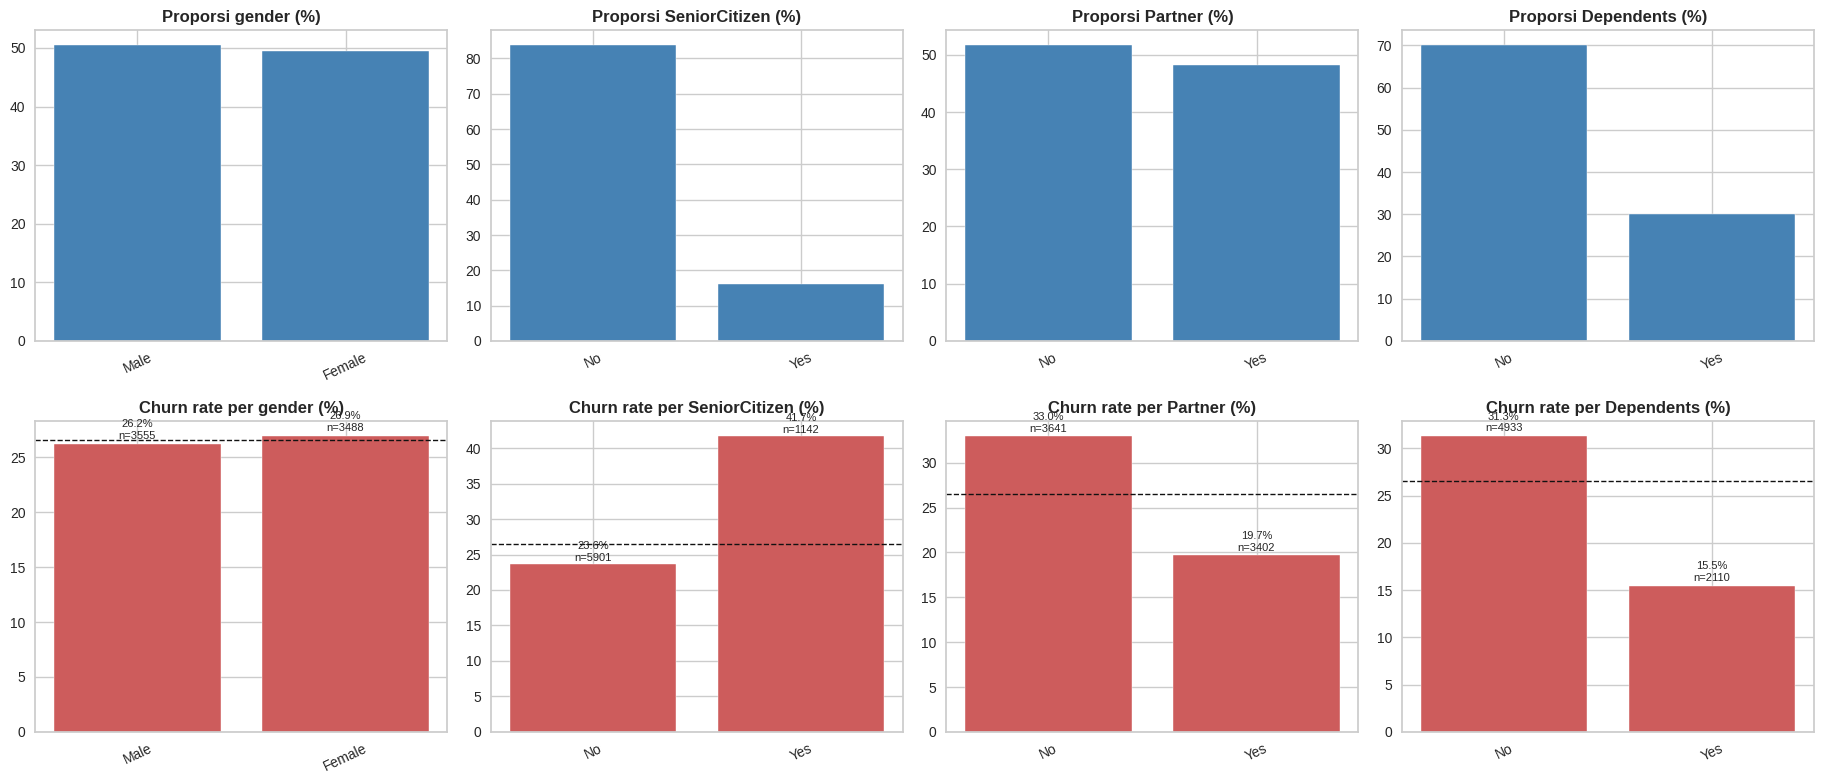

,variabel,kategori_churn_tertinggi,churn_tertinggi_%,kategori_churn_terendah,churn_terendah_%,gap_pp
1,SeniorCitizen,Yes,41.6800,No,23.6100,18.0800
3,Dependents,No,31.2800,Yes,15.4500,15.8300
2,Partner,No,32.9600,Yes,19.6600,13.2900
0,gender,Female,26.9200,Male,26.1600,0.7600



Asosiasi Partner x Dependents (proporsi baris):


Dependents,No,Yes
Partner,,
No,0.9010,0.0990
Yes,0.4860,0.5140


In [ ]:
demo_cols = ["gender", "SeniorCitizen", "Partner", "Dependents"]
plot_cat(demo_cols, "03a_demografi.png")
display(auto_gap(demo_cols))
print("\nAsosiasi Partner x Dependents (proporsi baris):")
display(pd.crosstab(df["Partner"], df["Dependents"], normalize="index").round(3))

### Sel 19: 3B. Tenure
Melihat distribusi tenure per status churn, churn rate per bulan (dihaluskan rata-rata bergerak 5 bulan), karakteristik per kelompok tenure, dan korelasi Spearman antara tenure dan MonthlyCharges.

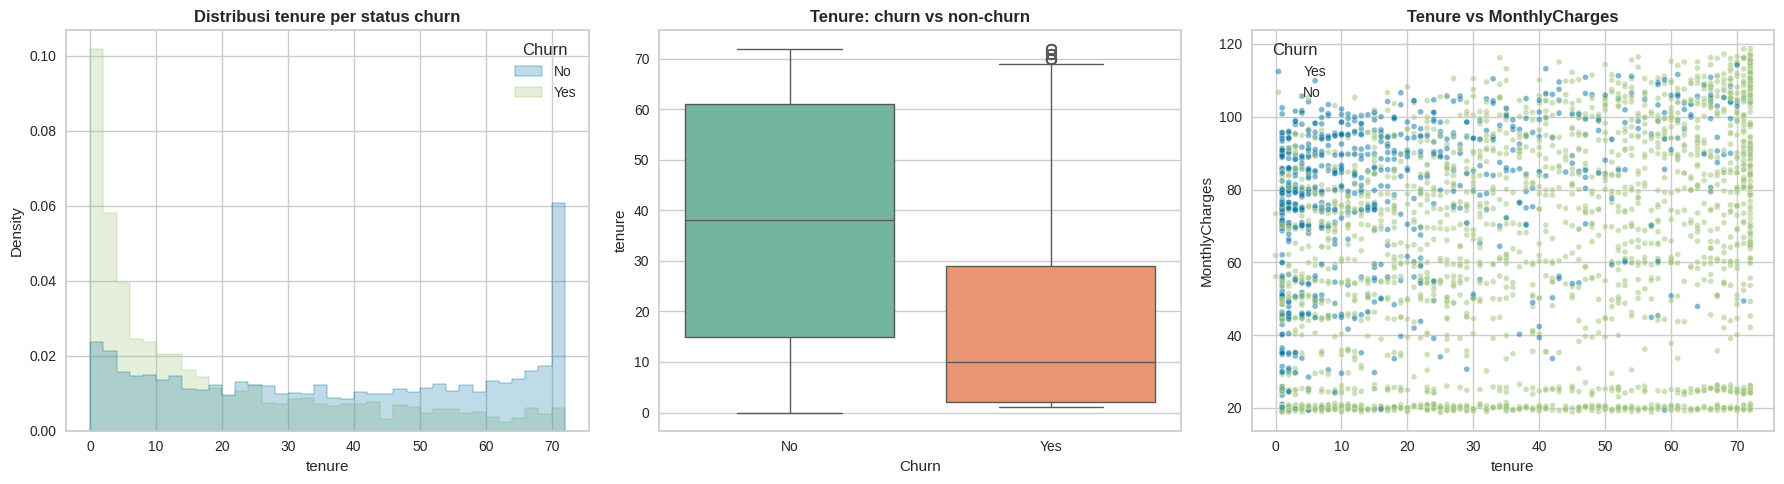

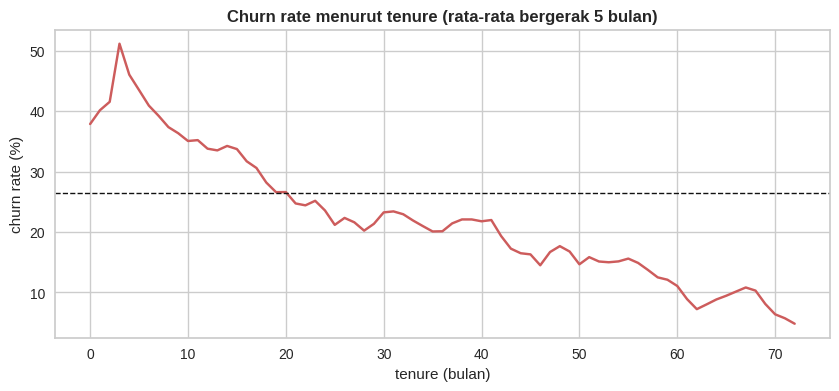

Karakteristik pelanggan baru vs lama (per kelompok tenure):


,n,churn_rate,tenure_mean,monthly_mean,m2m_share
tenure_group,,,,,
0-12,2186,47.4400,4.7300,56.1000,91.2200
13-24,1024,28.7100,18.3500,61.3600,71.9700
25-48,1594,20.3900,36.1900,65.9300,50.3100
49-72,2239,9.5100,63.0500,73.9500,15.2700



Spearman tenure vs MonthlyCharges (semua): rho = 0.276, p = 1.03e-123
  Churn = No : rho = 0.348
  Churn = Yes: rho = 0.484


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, element="step", stat="density",
             common_norm=False, ax=axes[0])
axes[0].set_title("Distribusi tenure per status churn")
sns.boxplot(data=df, x="Churn", y="tenure", hue="Churn", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Tenure: churn vs non-churn")
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x="tenure", y="MonthlyCharges",
                hue="Churn", alpha=0.5, s=18, ax=axes[2])
axes[2].set_title("Tenure vs MonthlyCharges")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["figures"], "03b_tenure.png"), dpi=150, bbox_inches="tight")
plt.show()

# Churn rate per bulan tenure (dihaluskan)
bym = df.groupby("tenure")["Churn_flag"].mean()
plt.figure(figsize=(10, 4))
plt.plot(bym.index, bym.rolling(5, center=True, min_periods=1).mean() * 100, color="indianred")
plt.axhline(OVERALL_CHURN * 100, color="k", ls="--", lw=1)
plt.title("Churn rate menurut tenure (rata-rata bergerak 5 bulan)")
plt.xlabel("tenure (bulan)"); plt.ylabel("churn rate (%)")
plt.savefig(os.path.join(PATHS["figures"], "03b_churn_by_tenure.png"), dpi=150, bbox_inches="tight")
plt.show()

tg = df.groupby("tenure_group").agg(
    n=("customerID", "count"), churn_rate=("Churn_flag", "mean"),
    tenure_mean=("tenure", "mean"), monthly_mean=("MonthlyCharges", "mean"),
    m2m_share=("Contract", lambda s: (s == "Month-to-month").mean())).reindex(TG_ORDER)
tg["churn_rate"] *= 100; tg["m2m_share"] *= 100
print("Karakteristik pelanggan baru vs lama (per kelompok tenure):")
display(tg.round(2))

rho_all = stats.spearmanr(df["tenure"], df["MonthlyCharges"])
print(f"\nSpearman tenure vs MonthlyCharges (semua): rho = {rho_all[0]:.3f}, p = {rho_all[1]:.2e}")
for lab, g in df.groupby("Churn"):
    r = stats.spearmanr(g["tenure"], g["MonthlyCharges"])
    print(f"  Churn = {lab:<3}: rho = {r[0]:.3f}")

### Sel 20: 3C. Penggunaan layanan
Adopsi layanan tambahan di antara pelanggan internet, kombinasi telepon x internet, churn per layanan, churn menurut **jumlah** add-on, dan 10 kombinasi add-on terbanyak.

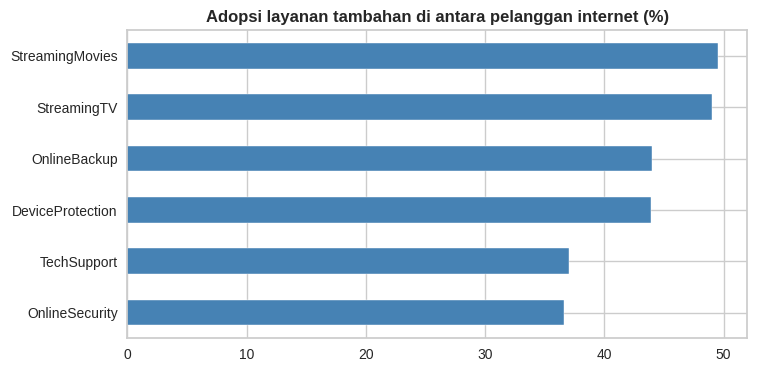

Kombinasi layanan telepon x internet (jumlah pelanggan):


InternetService,DSL,Fiber optic,No,All
PhoneService,,,,
No,682,0,0,682
Yes,1739,3096,1526,6361
All,2421,3096,1526,7043


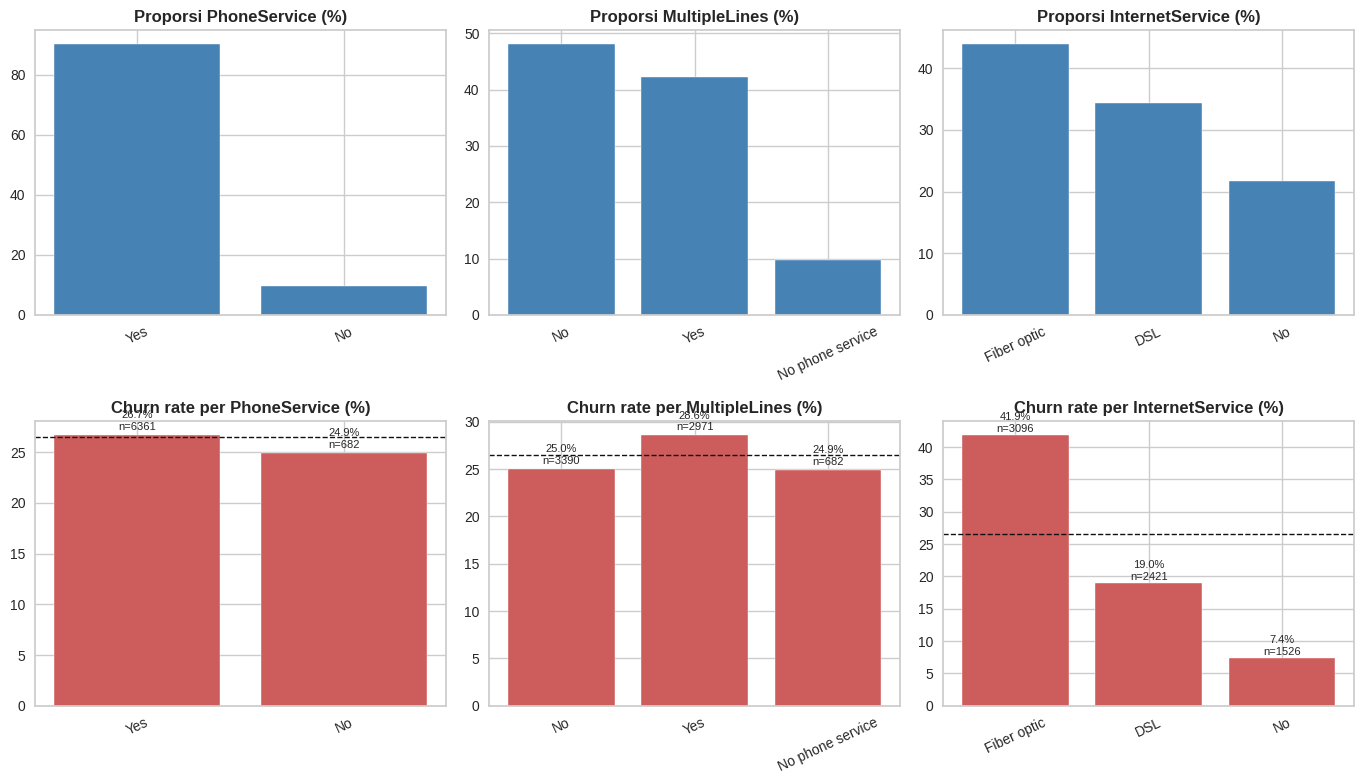

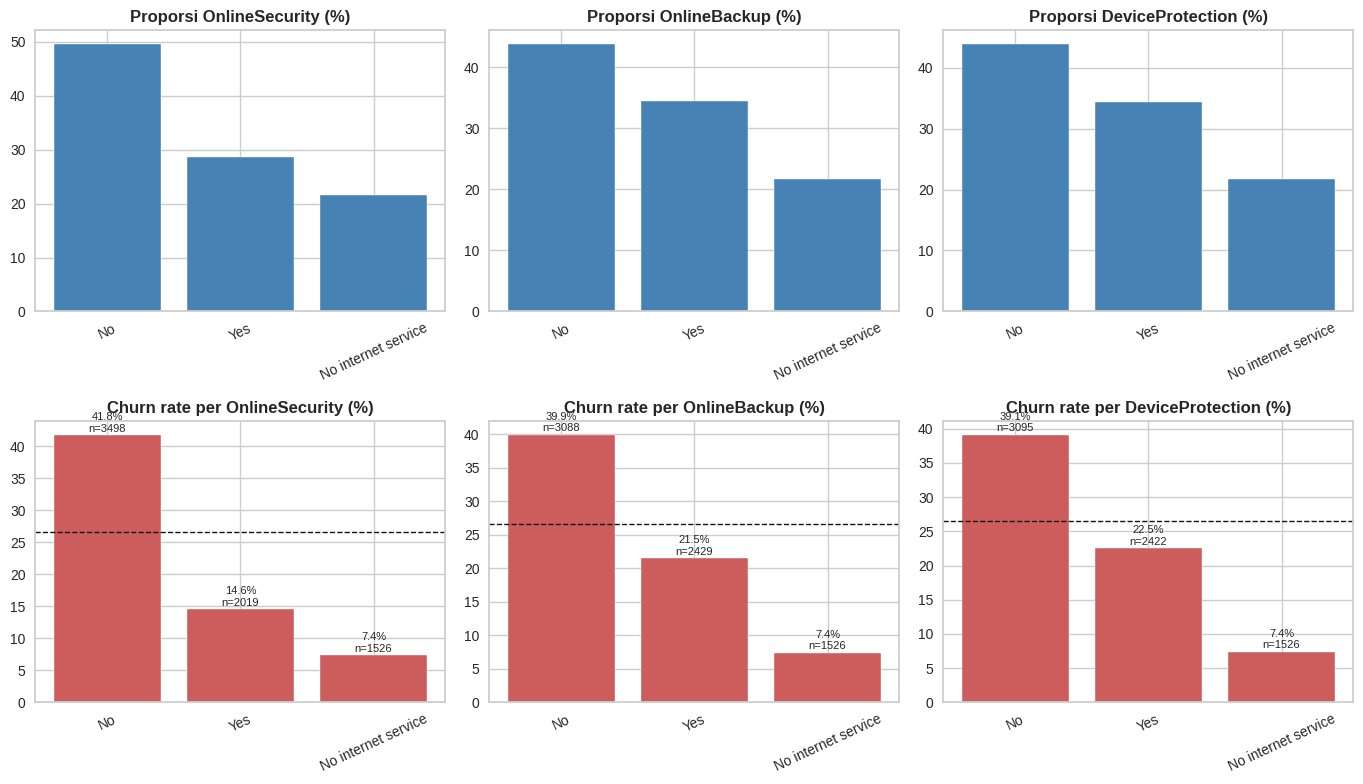

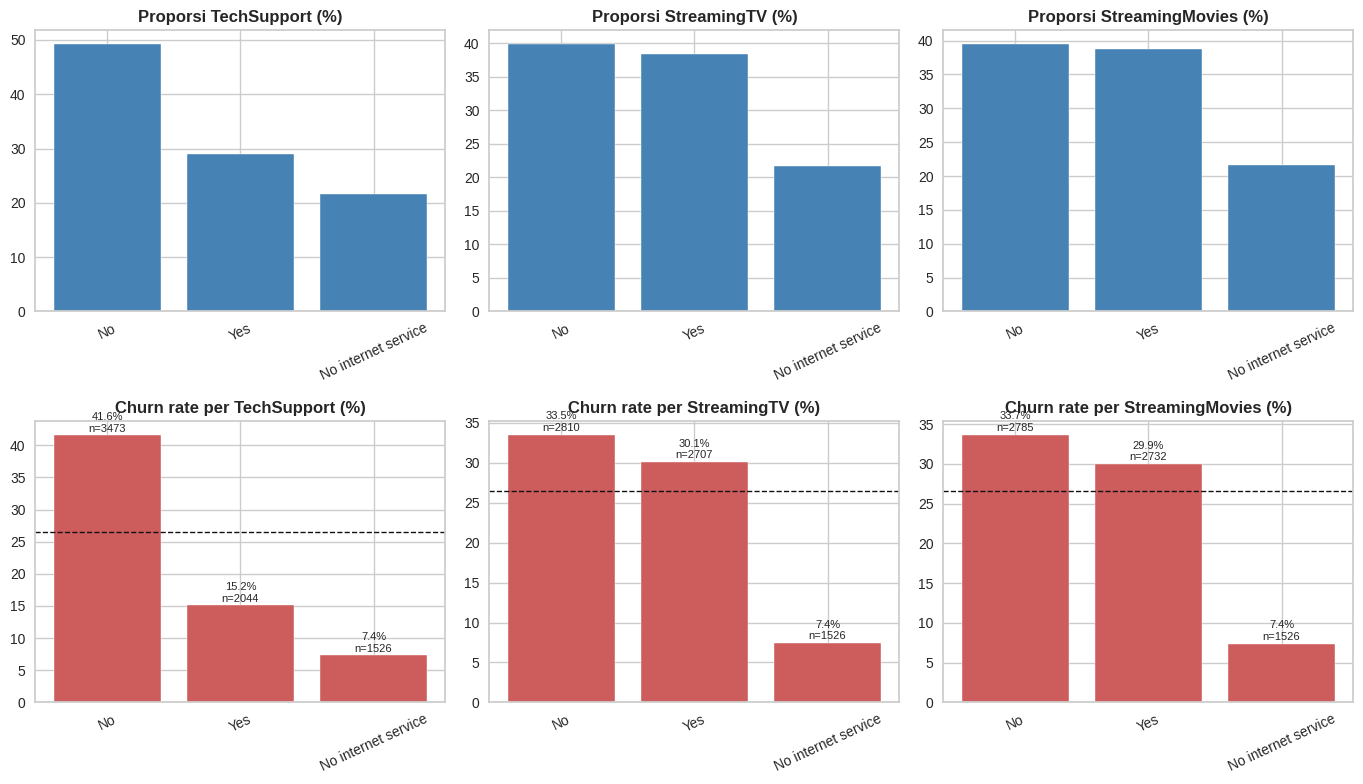

,variabel,kategori_churn_tertinggi,churn_tertinggi_%,kategori_churn_terendah,churn_terendah_%,gap_pp
2,InternetService,Fiber optic,41.8900,No,7.4000,34.4900
3,OnlineSecurity,No,41.7700,No internet service,7.4000,34.3600
6,TechSupport,No,41.6400,No internet service,7.4000,34.2300
4,OnlineBackup,No,39.9300,No internet service,7.4000,32.5200
5,DeviceProtection,No,39.1300,No internet service,7.4000,31.7200
8,StreamingMovies,No,33.6800,No internet service,7.4000,26.2800
7,StreamingTV,No,33.5200,No internet service,7.4000,26.1200
1,MultipleLines,Yes,28.6100,No phone service,24.9300,3.6800
0,PhoneService,Yes,26.7100,No,24.9300,1.7800



Churn rate menurut jumlah add-on (hanya pelanggan internet):


,n,churn_rate
n_addons,,
0,693,52.2400
1,966,45.7600
2,1033,35.8200
3,1118,27.3700
4,852,22.3000
5,571,12.4300
6,284,5.2800



10 kombinasi add-on terbanyak:


,n,churn_rate
combo,,
Tanpa add-on,693,52.2400
OnlineSecurity + OnlineBackup + DeviceProtection + TechSupport + StreamingTV + StreamingMovies,284,5.2800
StreamingTV + StreamingMovies,218,60.0900
OnlineBackup,209,39.2300
OnlineBackup + DeviceProtection + StreamingTV + StreamingMovies,196,39.2900
DeviceProtection + StreamingTV + StreamingMovies,189,50.7900
StreamingMovies,185,64.8600
OnlineSecurity,175,29.7100
StreamingTV,171,61.4000


In [ ]:
inet = df[df["InternetService"] != "No"].copy()
addon_yes = ((inet[ADDONS] == "Yes").mean() * 100).sort_values()
plt.figure(figsize=(8, 4))
addon_yes.plot.barh(color="steelblue")
plt.title("Adopsi layanan tambahan di antara pelanggan internet (%)")
plt.savefig(os.path.join(PATHS["figures"], "03c_adopsi_addon.png"), dpi=150, bbox_inches="tight")
plt.show()

print("Kombinasi layanan telepon x internet (jumlah pelanggan):")
display(pd.crosstab(df["PhoneService"], df["InternetService"], margins=True))

plot_cat(["PhoneService", "MultipleLines", "InternetService"], "03c_churn_layanan_dasar.png")
plot_cat(ADDONS[:3], "03c_churn_addon_1.png")
plot_cat(ADDONS[3:], "03c_churn_addon_2.png")
display(auto_gap(["PhoneService", "MultipleLines", "InternetService"] + ADDONS))

# Jumlah add-on (pelanggan internet) dan churn
inet["n_addons"] = (inet[ADDONS] == "Yes").sum(axis=1)
na = inet.groupby("n_addons")["Churn_flag"].agg(n="count", churn_rate="mean")
na["churn_rate"] *= 100
print("\nChurn rate menurut jumlah add-on (hanya pelanggan internet):")
display(na.round(2))

# Kombinasi add-on terpopuler
inet["combo"] = inet[ADDONS].apply(lambda r: " + ".join([c for c in ADDONS if r[c] == "Yes"]) or "Tanpa add-on", axis=1)
combo = inet.groupby("combo")["Churn_flag"].agg(n="count", churn_rate="mean").sort_values("n", ascending=False).head(10)
combo["churn_rate"] *= 100
print("\n10 kombinasi add-on terbanyak:")
display(combo.round(2))

### Sel 21: 3D. Analisis finansial
Distribusi tagihan, hubungan tenure-TotalCharges, churn per desil tagihan, dan **kurva Pareto** (seberapa besar kontribusi pelanggan bertagihan terbesar terhadap total tagihan). Juga membandingkan profil 20% pelanggan dengan tagihan tertinggi dengan sisanya.

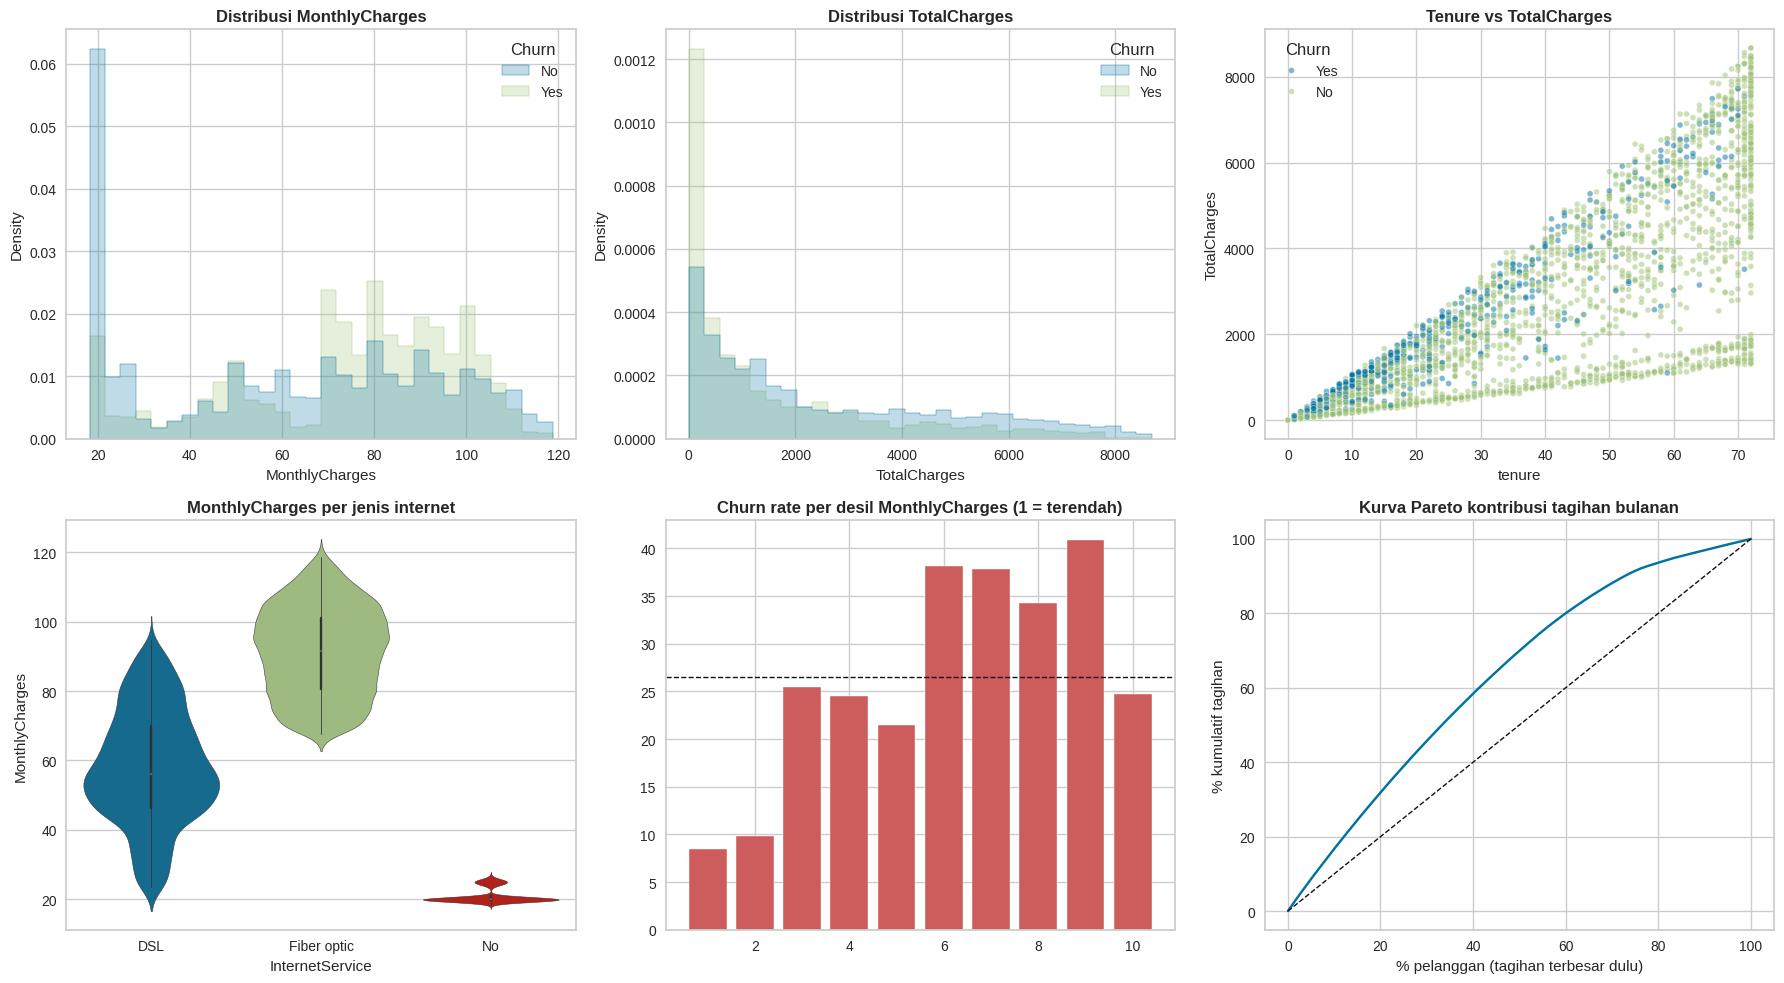

Kontribusi tagihan bulanan: 10% teratas = 16.7%, 20% teratas = 31.8%


,pelanggan_tagihan_top20%,pelanggan_lainnya
n,"1,415.0000","5,628.0000"
churn_rate_%,33.0000,24.9100
pct_fiber_optic,99.9300,29.8900
pct_month_to_month,46.1500,57.2500
tenure_median,52.0000,23.0000



Spearman tenure vs TotalCharges: rho = 0.890


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.histplot(df, x="MonthlyCharges", hue="Churn", bins=30, element="step", stat="density", common_norm=False, ax=axes[0, 0])
axes[0, 0].set_title("Distribusi MonthlyCharges")
sns.histplot(df, x="TotalCharges", hue="Churn", bins=30, element="step", stat="density", common_norm=False, ax=axes[0, 1])
axes[0, 1].set_title("Distribusi TotalCharges")
sns.scatterplot(data=df.sample(3000, random_state=RANDOM_STATE), x="tenure", y="TotalCharges",
                hue="Churn", alpha=0.5, s=18, ax=axes[0, 2])
axes[0, 2].set_title("Tenure vs TotalCharges")
sns.violinplot(data=df, x="InternetService", y="MonthlyCharges", hue="InternetService", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("MonthlyCharges per jenis internet")
df["bill_decile"] = pd.qcut(df["MonthlyCharges"], 10, labels=False, duplicates="drop") + 1
dec = df.groupby("bill_decile")["Churn_flag"].mean() * 100
axes[1, 1].bar(dec.index, dec.values, color="indianred")
axes[1, 1].axhline(OVERALL_CHURN * 100, color="k", ls="--", lw=1)
axes[1, 1].set_title("Churn rate per desil MonthlyCharges (1 = terendah)")
srt = np.sort(df["MonthlyCharges"].values)[::-1]
cum = np.cumsum(srt) / srt.sum()
axes[1, 2].plot(np.arange(1, len(srt) + 1) / len(srt) * 100, cum * 100)
axes[1, 2].plot([0, 100], [0, 100], "k--", lw=1)
axes[1, 2].set_title("Kurva Pareto kontribusi tagihan bulanan")
axes[1, 2].set_xlabel("% pelanggan (tagihan terbesar dulu)"); axes[1, 2].set_ylabel("% kumulatif tagihan")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["figures"], "03d_finansial.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Kontribusi tagihan bulanan: 10% teratas = {cum[int(.1*len(srt))-1]*100:.1f}%, 20% teratas = {cum[int(.2*len(srt))-1]*100:.1f}%")
top20 = df["MonthlyCharges"] >= df["MonthlyCharges"].quantile(0.80)
prof_top = pd.DataFrame({
    "pelanggan_tagihan_top20%": [top20.sum(), df.loc[top20, "Churn_flag"].mean() * 100,
                                 (df.loc[top20, "InternetService"] == "Fiber optic").mean() * 100,
                                 (df.loc[top20, "Contract"] == "Month-to-month").mean() * 100,
                                 df.loc[top20, "tenure"].median()],
    "pelanggan_lainnya": [(~top20).sum(), df.loc[~top20, "Churn_flag"].mean() * 100,
                          (df.loc[~top20, "InternetService"] == "Fiber optic").mean() * 100,
                          (df.loc[~top20, "Contract"] == "Month-to-month").mean() * 100,
                          df.loc[~top20, "tenure"].median()]},
    index=["n", "churn_rate_%", "pct_fiber_optic", "pct_month_to_month", "tenure_median"])
display(prof_top.round(2))
rho = stats.spearmanr(df["tenure"], df["TotalCharges"])
print(f"\nSpearman tenure vs TotalCharges: rho = {rho[0]:.3f}")

### Sel 22: 3E. Kontrak dan pembayaran
Churn per jenis kontrak, metode pembayaran, dan paperless billing, plus heatmap interaksi Contract x PaymentMethod.

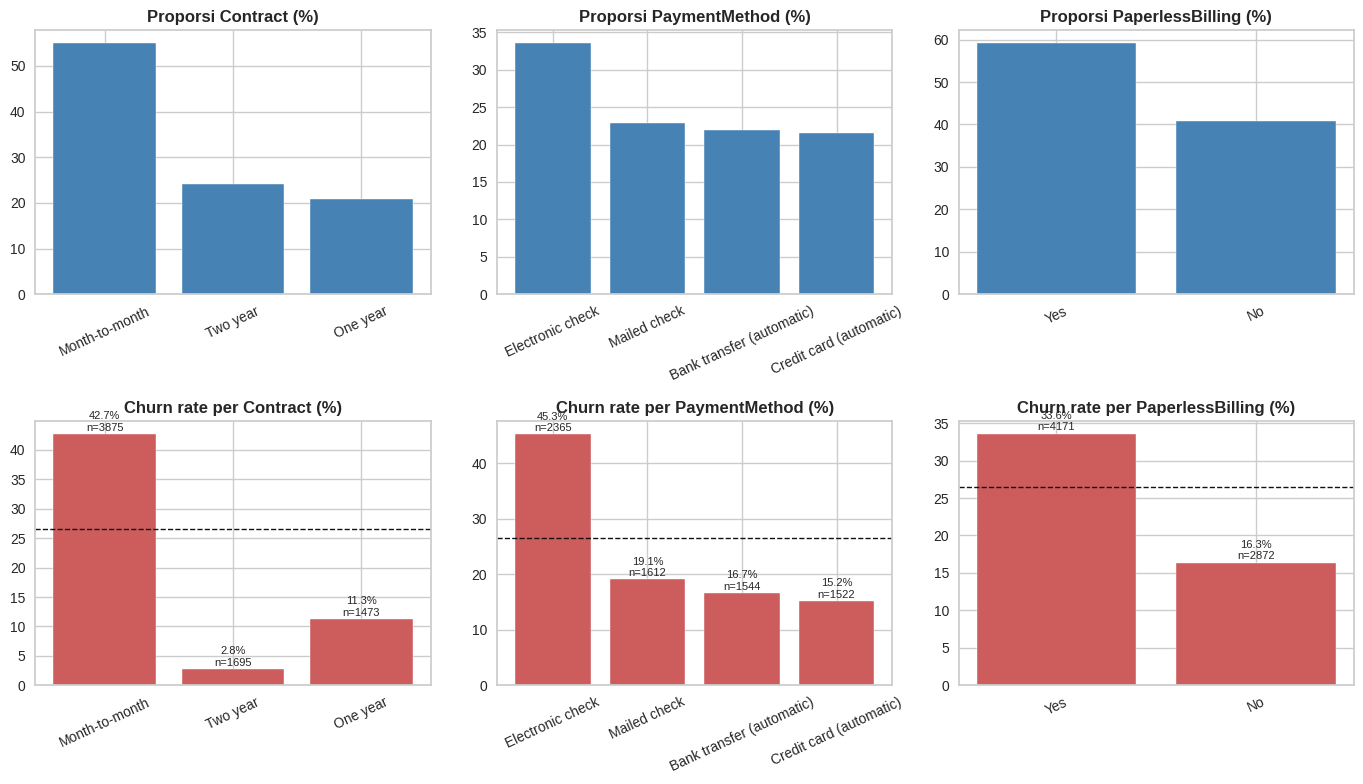

,variabel,kategori_churn_tertinggi,churn_tertinggi_%,kategori_churn_terendah,churn_terendah_%,gap_pp
0,Contract,Month-to-month,42.7100,Two year,2.8300,39.8800
1,PaymentMethod,Electronic check,45.2900,Credit card (automatic),15.2400,30.0400
2,PaperlessBilling,Yes,33.5700,No,16.3300,17.2400


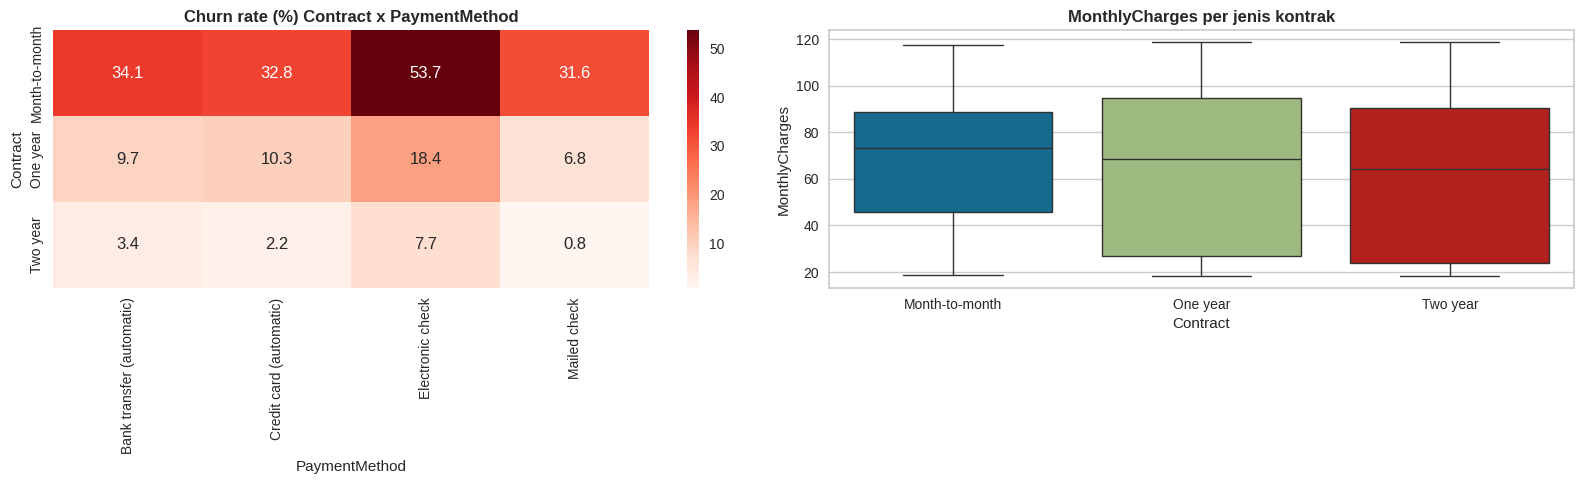

Jumlah pelanggan per kombinasi Contract x PaymentMethod:


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Contract,,,,
Month-to-month,589,543,1850,893
One year,391,398,347,337
Two year,564,581,168,382


In [ ]:
plot_cat(["Contract", "PaymentMethod", "PaperlessBilling"], "03e_kontrak_pembayaran.png")
display(auto_gap(["Contract", "PaymentMethod", "PaperlessBilling"]))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
pv = df.pivot_table(index="Contract", columns="PaymentMethod", values="Churn_flag", aggfunc="mean") * 100
sns.heatmap(pv, annot=True, fmt=".1f", cmap="Reds", ax=axes[0])
axes[0].set_title("Churn rate (%) Contract x PaymentMethod")
sns.boxplot(data=df, x="Contract", y="MonthlyCharges", hue="Contract", legend=False, ax=axes[1])
axes[1].set_title("MonthlyCharges per jenis kontrak")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["figures"], "03e_heatmap_kontrak_bayar.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Jumlah pelanggan per kombinasi Contract x PaymentMethod:")
display(pd.crosstab(df["Contract"], df["PaymentMethod"]))

### Sel 23: 3F. Eksplorasi churn
Ringkasan visual churn: distribusi target, perbandingan numerik churn vs non-churn, dan heatmap interaksi. Tabel akhir meranking **semua** variabel kategorikal berdasarkan gap churn rate, sebagai gambaran awal sebelum uji statistik formal.

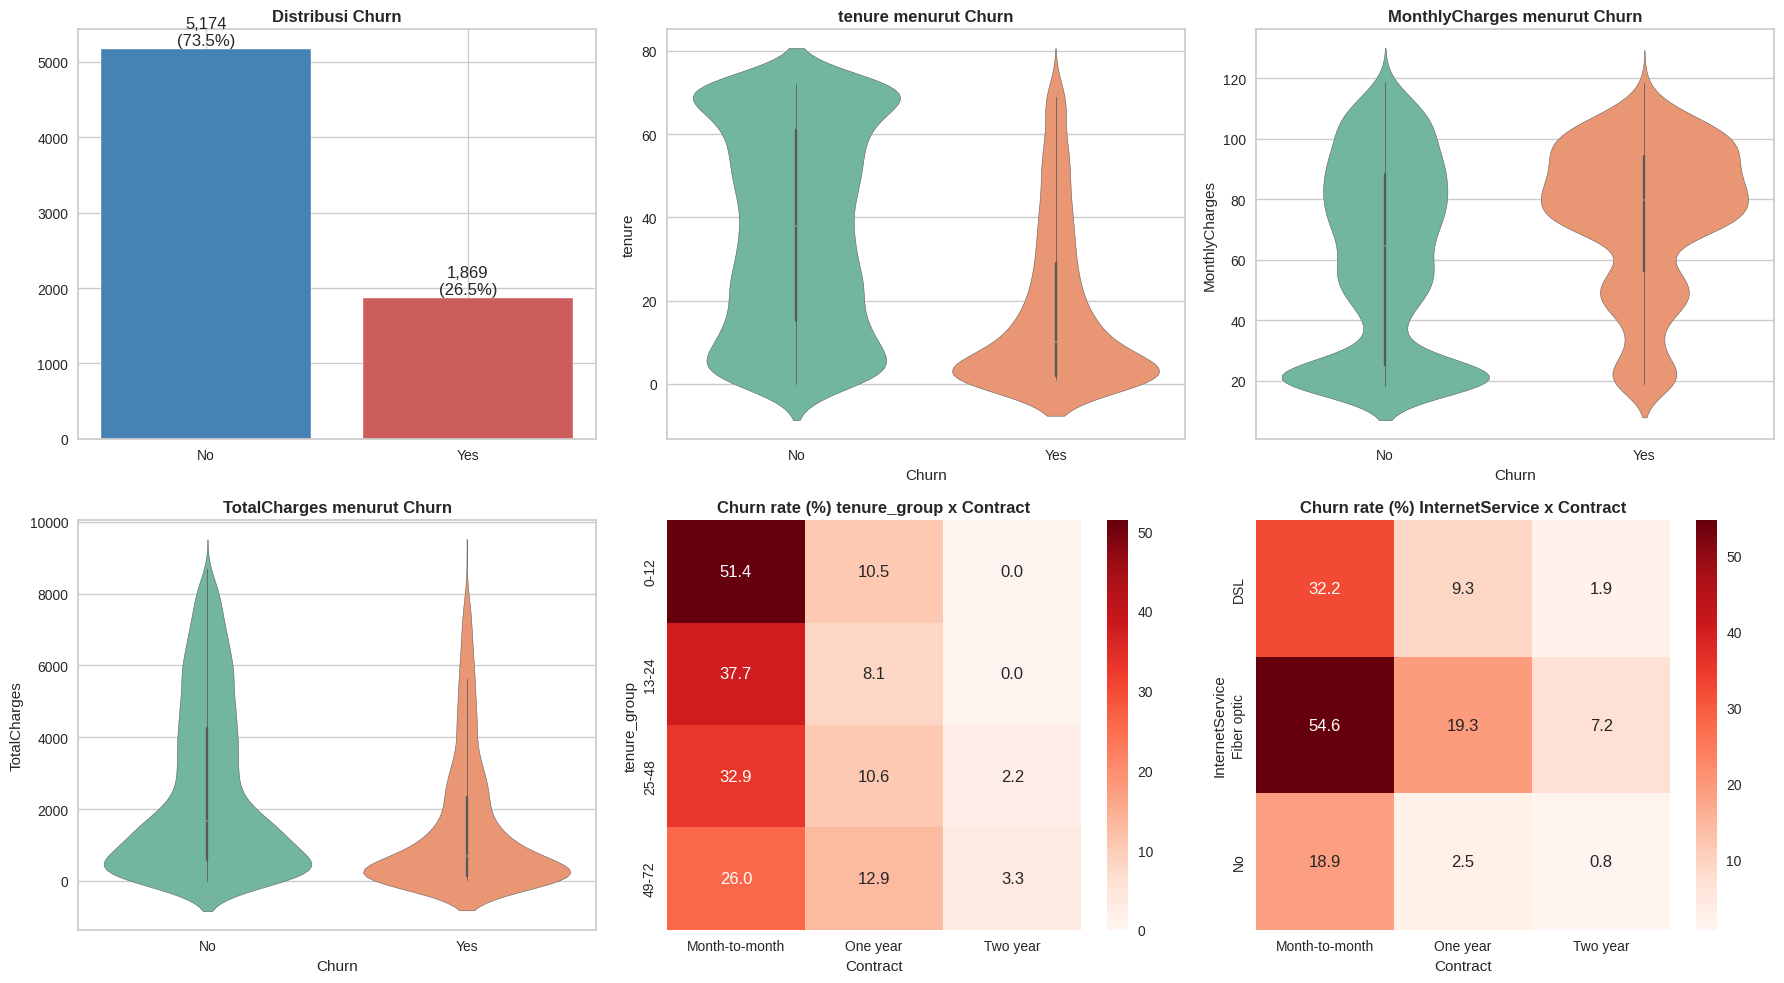

Peringkat variabel kategorikal menurut gap churn rate (kategori tertinggi vs terendah):


,variabel,kategori_churn_tertinggi,churn_tertinggi_%,kategori_churn_terendah,churn_terendah_%,gap_pp
13,Contract,Month-to-month,42.7100,Two year,2.8300,39.8800
16,tenure_group,0-12,47.4400,49-72,9.5100,37.9300
6,InternetService,Fiber optic,41.8900,No,7.4000,34.4900
7,OnlineSecurity,No,41.7700,No internet service,7.4000,34.3600
10,TechSupport,No,41.6400,No internet service,7.4000,34.2300
8,OnlineBackup,No,39.9300,No internet service,7.4000,32.5200
9,DeviceProtection,No,39.1300,No internet service,7.4000,31.7200
15,PaymentMethod,Electronic check,45.2900,Credit card (automatic),15.2400,30.0400
12,StreamingMovies,No,33.6800,No internet service,7.4000,26.2800
11,StreamingTV,No,33.5200,No internet service,7.4000,26.1200



Korelasi Spearman antara fitur numerik dan Churn (0/1):


,Churn_flag
tenure,-0.3670
MonthlyCharges,0.1850
TotalCharges,-0.2300
Churn_flag,1.0000


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
cc = df["Churn"].value_counts()
axes[0, 0].bar(cc.index, cc.values, color=["steelblue", "indianred"])
for i, v in enumerate(cc.values):
    axes[0, 0].text(i, v + 50, f"{v:,}\n({v/len(df)*100:.1f}%)", ha="center")
axes[0, 0].set_title("Distribusi Churn")
for ax, c in zip([axes[0, 1], axes[0, 2], axes[1, 0]], ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.violinplot(data=df, x="Churn", y=c, hue="Churn", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{c} menurut Churn")
pv1 = df.pivot_table(index="tenure_group", columns="Contract", values="Churn_flag", aggfunc="mean").reindex(TG_ORDER) * 100
sns.heatmap(pv1, annot=True, fmt=".1f", cmap="Reds", ax=axes[1, 1])
axes[1, 1].set_title("Churn rate (%) tenure_group x Contract")
pv2 = df.pivot_table(index="InternetService", columns="Contract", values="Churn_flag", aggfunc="mean") * 100
sns.heatmap(pv2, annot=True, fmt=".1f", cmap="Reds", ax=axes[1, 2])
axes[1, 2].set_title("Churn rate (%) InternetService x Contract")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["figures"], "03f_churn_eksplorasi.png"), dpi=150, bbox_inches="tight")
plt.show()

all_cat = [c for c in df.columns if c not in ["customerID", "Churn", "Churn_flag", "tenure", "MonthlyCharges",
                                               "TotalCharges", "bill_decile"]]
print("Peringkat variabel kategorikal menurut gap churn rate (kategori tertinggi vs terendah):")
display(auto_gap(all_cat))

print("\nKorelasi Spearman antara fitur numerik dan Churn (0/1):")
display(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn_flag"]].corr(method="spearman")["Churn_flag"].round(3))

---
# TAHAP 4: Statistical Analysis dan Hypothesis Testing

**Tujuan:** menguji secara formal apakah hubungan yang terlihat di EDA signifikan, dan **seberapa besar** efeknya.

**Logika pemilihan uji:**
| Situasi | Uji | Effect size |
|---|---|---|
| Kategorikal vs Churn | Chi-square | Cramér's V |
| Numerik vs Churn (2 kelompok) | Mann-Whitney U (utama), Welch t-test (sensitivitas) | rank-biserial r, Cohen's d |
| Numerik vs beberapa kelompok | Kruskal-Wallis + post-hoc Mann-Whitney | epsilon kuadrat |

Uji nonparametrik dipilih karena variabel numerik tidak normal (Tahap 2).

**Mengapa effect size penting:** dengan 7.043 sampel, hampir semua hubungan akan "signifikan". Effect size menunjukkan apakah hubungannya cukup besar untuk bermakna secara praktis.

**Koreksi pengujian berganda (Holm dan FDR):** menguji banyak hipotesis sekaligus meningkatkan peluang false positive. Koreksi menyesuaikan p-value agar tetap terkendali. Level signifikansi alpha = 0,05.

### Sel 24: Chi-square + Cramér's V
H0: variabel X independen terhadap Churn. H1: ada asosiasi. Cramér's V memakai koreksi bias Bergsma. Kolom `min_expected_count` memeriksa asumsi chi-square (frekuensi harapan minimal 5).

In [ ]:
from statsmodels.stats.multitest import multipletests
ALPHA = 0.05

def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    phi2c = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / min(kc - 1, rc - 1)))

cat_vars = [c for c in df.columns if c not in ["customerID", "Churn", "Churn_flag", "tenure",
                                                "MonthlyCharges", "TotalCharges", "bill_decile"]]
rows = []
for c in cat_vars:
    ct = pd.crosstab(df[c], df["Churn"])
    chi2, p, dof, exp = stats.chi2_contingency(ct)
    rows.append({"variabel": c, "chi2": chi2, "dof": dof, "p_value": p,
                 "cramers_v": cramers_v(ct), "min_expected_count": exp.min()})
chi_df = pd.DataFrame(rows)
chi_df["p_holm"] = multipletests(chi_df["p_value"], method="holm")[1]
chi_df["p_fdr_bh"] = multipletests(chi_df["p_value"], method="fdr_bh")[1]
chi_df["signifikan_holm"] = chi_df["p_holm"] < ALPHA
chi_df["kekuatan_asosiasi"] = pd.cut(chi_df["cramers_v"], [-0.01, 0.1, 0.2, 0.3, 1.0],
                                     labels=["sangat lemah", "lemah", "sedang", "kuat"])
chi_df = chi_df.sort_values("cramers_v", ascending=False).reset_index(drop=True)
display(chi_df.style.format({"chi2": "{:.1f}", "p_value": "{:.2e}", "p_holm": "{:.2e}",
                             "p_fdr_bh": "{:.2e}", "cramers_v": "{:.3f}", "min_expected_count": "{:.1f}"}))
print(f"\nJumlah hipotesis diuji: {len(chi_df)} | signifikan setelah Holm: {chi_df['signifikan_holm'].sum()}")
print(f"Uji dengan expected count < 5 (asumsi chi-square kurang terpenuhi): {(chi_df['min_expected_count'] < 5).sum()}")
print("Tidak signifikan setelah koreksi:", chi_df.loc[~chi_df["signifikan_holm"], "variabel"].tolist())

,variabel,chi2,dof,p_value,cramers_v,min_expected_count,p_holm,p_fdr_bh,signifikan_holm,kekuatan_asosiasi
0,Contract,1184.6,2,5.86e-258,0.410,390.9,9.97e-257,9.97e-257,True,kuat
1,tenure_group,856.1,3,2.94e-185,0.348,271.7,4.42e-184,1.67e-184,True,kuat
2,OnlineSecurity,850.0,2,2.66e-185,0.347,405.0,4.26e-184,1.67e-184,True,kuat
3,TechSupport,828.2,2,1.44e-180,0.343,405.0,2.02e-179,6.13e-180,True,kuat
4,InternetService,732.3,2,9.57e-160,0.322,405.0,1.24e-158,3.25e-159,True,kuat
5,PaymentMethod,648.1,3,3.68e-140,0.303,403.9,4.42e-139,1.04e-139,True,kuat
6,OnlineBackup,601.8,2,2.08e-131,0.292,405.0,2.29e-130,5.05e-131,True,sedang
7,DeviceProtection,558.4,2,5.51e-122,0.281,405.0,5.51e-121,1.17e-121,True,sedang
8,StreamingMovies,375.7,2,2.67e-82,0.230,405.0,2.40e-81,5.04e-82,True,sedang
9,StreamingTV,374.2,2,5.53e-82,0.230,405.0,4.42e-81,9.40e-82,True,sedang



Jumlah hipotesis diuji: 17 | signifikan setelah Holm: 15
Uji dengan expected count < 5 (asumsi chi-square kurang terpenuhi): 0
Tidak signifikan setelah koreksi: ['PhoneService', 'gender']


### Sel 25: Mann-Whitney U dan Welch t-test
H0: distribusi variabel sama antara churn dan non-churn. Rank-biserial r bernilai negatif jika kelompok churn cenderung lebih rendah. Welch t-test hanya sebagai pembanding (uji sensitivitas).

In [ ]:
rows = []
for c in ["tenure", "MonthlyCharges", "TotalCharges"]:
    a = df.loc[df["Churn"] == "Yes", c]; b = df.loc[df["Churn"] == "No", c]
    U, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rbc = 2 * U / (len(a) * len(b)) - 1
    tt = stats.ttest_ind(a, b, equal_var=False)
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    rows.append({"variabel": c, "median_churn": a.median(), "median_non_churn": b.median(),
                 "mean_churn": a.mean(), "mean_non_churn": b.mean(),
                 "U": U, "p_mannwhitney": p, "rank_biserial_r": rbc,
                 "p_welch": tt.pvalue, "cohens_d": (a.mean() - b.mean()) / sp})
mw_df = pd.DataFrame(rows)
mw_df["p_holm"] = multipletests(mw_df["p_mannwhitney"], method="holm")[1]
mw_df["besar_efek"] = pd.cut(mw_df["rank_biserial_r"].abs(), [-0.01, 0.1, 0.3, 0.5, 1.0],
                             labels=["diabaikan", "kecil", "sedang", "besar"])
display(mw_df.style.format({c: "{:.3f}" for c in ["median_churn", "median_non_churn", "mean_churn", "mean_non_churn",
                                                  "rank_biserial_r", "cohens_d"]} |
                           {"U": "{:,.0f}", "p_mannwhitney": "{:.2e}", "p_welch": "{:.2e}", "p_holm": "{:.2e}"}))
print("Catatan: r < 0 berarti kelompok churn cenderung bernilai lebih rendah daripada non-churn.")

,variabel,median_churn,median_non_churn,mean_churn,mean_non_churn,U,p_mannwhitney,rank_biserial_r,p_welch,cohens_d,p_holm,besar_efek
0,tenure,10.000,38.000,17.979,37.570,"2,515,538",2.42e-208,-0.480,1.20e-232,-0.852,7.26e-208,sedang
1,MonthlyCharges,79.650,64.425,74.441,61.265,"6,003,126",3.31e-54,0.242,8.59e-73,0.446,3.31e-54,kecil
2,TotalCharges,703.550,1679.525,1531.796,2549.911,"3,381,224",5.69e-83,-0.301,5.90e-75,-0.458,1.14e-82,sedang


Catatan: r < 0 berarti kelompok churn cenderung bernilai lebih rendah daripada non-churn.


### Sel 26: Kruskal-Wallis dan post-hoc
Pengganti ANOVA untuk data non-normal. Jika Kruskal-Wallis signifikan, post-hoc Mann-Whitney berpasangan (dengan koreksi Holm) menunjukkan pasangan kontrak mana yang berbeda.

In [ ]:
def kruskal_eps(col, grp):
    groups = [g[col].values for _, g in df.groupby(grp)]
    H, p = stats.kruskal(*groups)
    n = len(df)
    return H, p, H * (n + 1) / (n ** 2 - 1)

rows = []
for grp in ["Contract", "InternetService", "PaymentMethod", "tenure_group"]:
    for col in ["MonthlyCharges", "tenure"]:
        if grp == "tenure_group" and col == "tenure":
            continue
        H, p, eps = kruskal_eps(col, grp)
        rows.append({"variabel": col, "kelompok": grp, "H": H, "p_value": p, "epsilon_sq": eps})
kw_df = pd.DataFrame(rows)
kw_df["p_holm"] = multipletests(kw_df["p_value"], method="holm")[1]
display(kw_df.style.format({"H": "{:.1f}", "p_value": "{:.2e}", "p_holm": "{:.2e}", "epsilon_sq": "{:.3f}"}))

from itertools import combinations
for col in ["tenure", "MonthlyCharges"]:
    pairs, ps = [], []
    for a, b in combinations(df["Contract"].unique(), 2):
        x, y = df.loc[df["Contract"] == a, col], df.loc[df["Contract"] == b, col]
        pairs.append(f"{a} vs {b}")
        ps.append(stats.mannwhitneyu(x, y).pvalue)
    adj = multipletests(ps, method="holm")[1]
    print(f"\nPost-hoc {col} antar Contract (Holm):")
    display(pd.DataFrame({"pasangan": pairs, "p_mw": ps, "p_holm": adj}).style.format({"p_mw": "{:.2e}", "p_holm": "{:.2e}"}))

print(f"\nTotal hipotesis uji pada Tahap 4 (tanpa post-hoc): {len(chi_df) + len(mw_df) + len(kw_df)}")

,variabel,kelompok,H,p_value,epsilon_sq,p_holm
0,MonthlyCharges,Contract,21.2,2.46e-05,0.003,4.92e-05
1,tenure,Contract,3139.2,0.00e+00,0.446,0.00e+00
2,MonthlyCharges,InternetService,5529.7,0.00e+00,0.785,0.00e+00
3,tenure,InternetService,11.7,2.84e-03,0.002,2.84e-03
4,MonthlyCharges,PaymentMethod,1103.3,7.01e-239,0.157,2.80e-238
5,tenure,PaymentMethod,1158.5,7.22e-251,0.165,3.61e-250
6,MonthlyCharges,tenure_group,485.9,5.33e-105,0.069,1.60e-104



Post-hoc tenure antar Contract (Holm):


,pasangan,p_mw,p_holm
0,Month-to-month vs One year,6.42e-290,1.28e-289
1,Month-to-month vs Two year,0.00e+00,0.00e+00
2,One year vs Two year,2.50e-120,2.50e-120



Post-hoc MonthlyCharges antar Contract (Holm):


,pasangan,p_mw,p_holm
0,Month-to-month vs One year,7.65e-01,7.65e-01
1,Month-to-month vs Two year,1.44e-06,4.33e-06
2,One year vs Two year,8.94e-03,1.79e-02



Total hipotesis uji pada Tahap 4 (tanpa post-hoc): 27


---
# TAHAP 5: Feature Engineering dan Preprocessing

**Tujuan:** membuat fitur turunan dan menyiapkan data untuk clustering dan model.

**Ide kunci:** fungsi pembuat fitur ditulis ke **modul Python terpisah** (`customer_features.py`). Logika yang sama lalu dipakai di notebook, di model tersimpan, dan di aplikasi Streamlit tanpa menyalin kode. Ini mencegah perbedaan perlakuan data saat training dan saat produksi.

**Fitur turunan:**
| Fitur | Definisi |
|---|---|
| `tenure_group` | 0-12, 13-24, 25-48, 49-72 bulan |
| `n_addon_services` | jumlah dari 6 layanan tambahan yang berstatus Yes |
| `total_service_count` | telepon + internet + add-on + multiple lines |
| `avg_monthly_revenue` | TotalCharges / tenure (jika tenure 0 pakai MonthlyCharges) |
| `annual_value_proxy` | MonthlyCharges x 12 (proksi nilai, **bukan CLV sebenarnya**) |
| `contract_risk` | 1 jika kontrak bulanan |
| `contract_ord` | 0/1/2 untuk Month-to-month/One year/Two year |

Kategori redundan "No internet service" dan "No phone service" diubah menjadi "No", karena informasinya sudah ada di `InternetService` dan `PhoneService`. Tidak ada fitur yang memakai `Churn`.

### Sel 27: Tulis modul fitur
String `FEATURE_MODULE` berisi kode modul. Isinya ditulis ke file, lalu di-import sebagai `cf`. Fungsi utama:
- `build_features(raw)`: data mentah menjadi tabel fitur.
- `assign_risk_tier`, `assign_value_tier`, `assign_priority`: logika tier dan prioritas bisnis.
- `score_customers(raw, bundle)`: menskor pelanggan baru (segmen, probabilitas churn, tier, prioritas) tanpa training ulang.

In [ ]:
FEATURE_MODULE = '''"""Utilitas fitur dan skoring Telco Customer Intelligence (dibuat otomatis oleh notebook)."""
import numpy as np
import pandas as pd

ADDON_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
TENURE_BINS = [-1, 12, 24, 48, np.inf]
TENURE_LABELS = ["0-12", "13-24", "25-48", "49-72"]
CONTRACT_ORD = {"Month-to-month": 0, "One year": 1, "Two year": 2}

NUM_FEATS = ["tenure", "MonthlyCharges", "TotalCharges", "n_addon_services", "total_service_count"]
CAT_FEATS = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines",
             "InternetService"] + ADDON_COLS + ["Contract", "PaperlessBilling", "PaymentMethod"]
MODEL_FEATS = NUM_FEATS + CAT_FEATS
CLUSTER_FEATS = ["tenure", "MonthlyCharges", "n_addon_services", "contract_ord"]


def build_features(raw):
    """Ubah data mentah (format CSV Telco) menjadi tabel fitur siap model. Tidak memakai kolom Churn."""
    d = raw.copy()
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"].replace(" ", np.nan), errors="coerce")
    d.loc[d["TotalCharges"].isna() & (d["tenure"] == 0), "TotalCharges"] = 0.0
    d["SeniorCitizen"] = d["SeniorCitizen"].replace({0: "No", 1: "Yes"})
    d["MultipleLines"] = d["MultipleLines"].replace({"No phone service": "No"})
    for c in ADDON_COLS:
        d[c] = d[c].replace({"No internet service": "No"})
    d["tenure_group"] = pd.cut(d["tenure"], bins=TENURE_BINS, labels=TENURE_LABELS).astype(str)
    d["n_addon_services"] = (d[ADDON_COLS] == "Yes").sum(axis=1)
    d["total_service_count"] = ((d["PhoneService"] == "Yes").astype(int)
                                + (d["InternetService"] != "No").astype(int)
                                + d["n_addon_services"]
                                + (d["MultipleLines"] == "Yes").astype(int))
    d["avg_monthly_revenue"] = np.where(d["tenure"] > 0,
                                        d["TotalCharges"] / d["tenure"].replace(0, np.nan),
                                        d["MonthlyCharges"])
    d["annual_value_proxy"] = d["MonthlyCharges"] * 12
    d["contract_risk"] = (d["Contract"] == "Month-to-month").astype(int)
    d["contract_ord"] = d["Contract"].map(CONTRACT_ORD)
    return d


def assign_risk_tier(p, cut_med, cut_high):
    p = np.asarray(p)
    return np.where(p >= cut_high, "High", np.where(p >= cut_med, "Medium", "Low"))


def assign_value_tier(v, cut):
    return np.where(np.asarray(v) >= cut, "High", "Standard")


def assign_priority(risk, value):
    risk = np.asarray(risk); value = np.asarray(value)
    out = np.full(risk.shape, "P4 - Pertahankan", dtype=object)
    out[(risk == "Medium") & (value == "Standard")] = "P3 - Pantau"
    out[((risk == "High") & (value == "Standard")) | ((risk == "Medium") & (value == "High"))] = "P2 - Retensi terstruktur"
    out[(risk == "High") & (value == "High")] = "P1 - Selamatkan segera"
    return out


def score_customers(raw, bundle):
    """Skor pelanggan baru: segmen, probabilitas churn, tier risiko/nilai, prioritas. Tanpa training ulang."""
    f = build_features(raw)
    out = pd.DataFrame(index=f.index)
    if "customerID" in f.columns:
        out["customerID"] = f["customerID"]
    seg_raw = bundle["segment_pipe"].predict(f[CLUSTER_FEATS].astype(float))
    out["segment_id"] = pd.Series(seg_raw, index=f.index).map(bundle["segment_label_map"]).astype(int)
    out["segment_name"] = out["segment_id"].map(bundle["segment_names"])
    p_raw = bundle["churn_pipe"].predict_proba(f[MODEL_FEATS])[:, 1]
    out["churn_prob_raw"] = p_raw
    out["churn_prob_calibrated"] = bundle["calibrator"].predict(p_raw)
    out["risk_tier"] = assign_risk_tier(p_raw, bundle["risk_cut_med"], bundle["risk_cut_high"])
    out["value_tier"] = assign_value_tier(f["annual_value_proxy"], bundle["value_cut"])
    out["priority"] = assign_priority(out["risk_tier"], out["value_tier"])
    out["flag_churn_threshold"] = (p_raw >= bundle["threshold"]).astype(int)
    out["annual_value_proxy"] = f["annual_value_proxy"]
    out["revenue_at_risk"] = out["churn_prob_calibrated"] * f["annual_value_proxy"]
    return out
'''
module_path = os.path.join(PATHS["models"], "customer_features.py")
with open(module_path, "w", encoding="utf-8") as fh:
    fh.write(FEATURE_MODULE)

import importlib
if PATHS["models"] not in sys.path:
    sys.path.insert(0, PATHS["models"])
import customer_features as cf
importlib.reload(cf)
print("Modul tersimpan:", module_path)

Modul tersimpan: /content/telco_customer_intelligence/models/customer_features.py


### Sel 28: Terapkan fitur dan validasi
`build_features` dijalankan pada data mentah. Kode memastikan hasilnya konsisten dengan dataset EDA, tidak ada missing pada fitur model, lalu menampilkan churn rate per fitur turunan.

In [ ]:
df_feat = cf.build_features(df_raw)
df_feat["Churn_flag"] = (df_feat["Churn"] == "Yes").astype(int)

# Validasi: konsisten dengan dataset kerja EDA & tidak ada missing pada fitur model
assert np.allclose(df_feat["TotalCharges"], df["TotalCharges"])
print("Missing pada fitur model :", int(df_feat[cf.MODEL_FEATS].isna().sum().sum()))
print("Missing pada fitur cluster:", int(df_feat[cf.CLUSTER_FEATS].isna().sum().sum()))
print("Bentuk df_feat           :", df_feat.shape)

eng_cols = ["n_addon_services", "total_service_count", "avg_monthly_revenue", "annual_value_proxy", "contract_risk", "contract_ord"]
display(df_feat[eng_cols].describe().T.round(3))

for c in ["tenure_group", "n_addon_services", "total_service_count", "contract_risk"]:
    t = df_feat.groupby(c)["Churn_flag"].agg(n="count", churn_rate="mean")
    t["churn_rate"] = (t["churn_rate"] * 100).round(2)
    print(f"\nChurn rate menurut {c}:")
    display(t)

Missing pada fitur model : 0
Missing pada fitur cluster: 0
Bentuk df_feat           : (7043, 29)


,count,mean,std,min,25%,50%,75%,max
n_addon_services,"7,043.0000",2.0380,1.8480,0.0000,0.0000,2.0000,3.0000,6.0000
total_service_count,"7,043.0000",4.1460,2.3130,1.0000,2.0000,4.0000,6.0000,9.0000
avg_monthly_revenue,"7,043.0000",64.7630,30.1900,13.7750,35.9350,70.3380,90.1740,121.4000
annual_value_proxy,"7,043.0000",777.1400,361.0810,219.0000,426.0000,844.2000,"1,078.2000","1,425.0000"
contract_risk,"7,043.0000",0.5500,0.4980,0.0000,0.0000,1.0000,1.0000,1.0000
contract_ord,"7,043.0000",0.6900,0.8340,0.0000,0.0000,0.0000,1.0000,2.0000



Churn rate menurut tenure_group:


,n,churn_rate
tenure_group,,
0-12,2186,47.4400
13-24,1024,28.7100
25-48,1594,20.3900
49-72,2239,9.5100



Churn rate menurut n_addon_services:


,n,churn_rate
n_addon_services,,
0,2219,21.4100
1,966,45.7600
2,1033,35.8200
3,1118,27.3700
4,852,22.3000
5,571,12.4300
6,284,5.2800



Churn rate menurut total_service_count:


,n,churn_rate
total_service_count,,
1,1264,10.9200
2,859,30.9700
3,846,44.9200
4,965,36.4800
5,922,31.3400
6,908,25.5500
7,676,22.4900
8,395,12.4100
9,208,5.2900



Churn rate menurut contract_risk:


,n,churn_rate
contract_risk,,
0,3168,6.7600
1,3875,42.7100


### Sel 29: Multikolinearitas
**Multikolinearitas** terjadi saat fitur saling berkorelasi sangat tinggi. **VIF** (Variance Inflation Factor) mengukurnya: VIF > 10 dianggap tinggi. Ini mengganggu Logistic Regression (koefisien tidak stabil), tetapi tidak model berbasis pohon. Regularisasi L2 pada Logistic Regression membantu meredamnya.

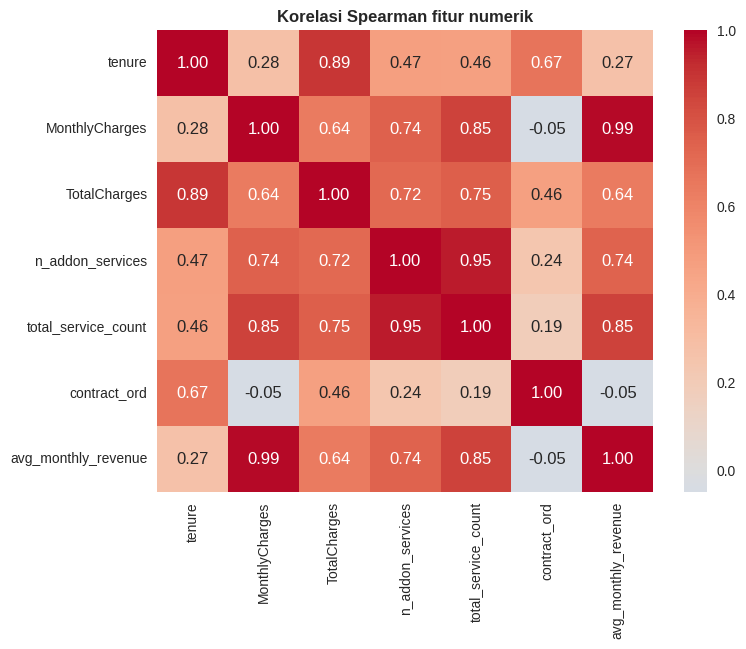

,fitur,VIF
0,tenure,5.8800
1,MonthlyCharges,6.9500
2,TotalCharges,10.1800
3,n_addon_services,15.0300
4,total_service_count,27.4200


VIF > 10 menandakan multikolinearitas tinggi: pengaruhnya pada Logistic Regression (koefisien tidak stabil), tidak pada model berbasis pohon. Regularisasi L2 dipakai untuk meredamnya.


In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

chk = cf.NUM_FEATS + ["contract_ord", "avg_monthly_revenue"]
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df_feat[chk].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Korelasi Spearman fitur numerik")
plt.savefig(os.path.join(PATHS["figures"], "05_korelasi_numerik.png"), dpi=150, bbox_inches="tight")
plt.show()

Xv = sm.add_constant(df_feat[cf.NUM_FEATS].astype(float))
vif = pd.DataFrame({"fitur": cf.NUM_FEATS,
                    "VIF": [variance_inflation_factor(Xv.values, i + 1) for i in range(len(cf.NUM_FEATS))]})
display(vif.round(2))
print("VIF > 10 menandakan multikolinearitas tinggi: pengaruhnya pada Logistic Regression (koefisien tidak stabil), "
      "tidak pada model berbasis pohon. Regularisasi L2 dipakai untuk meredamnya.")

### Sel 30: Skema fitur dan keputusan preprocessing
Mencetak fitur yang dipakai model, fitur clustering, dan fitur yang sengaja tidak dipakai. Preprocessing model (imputer, scaler, one-hot) **tidak** dilakukan di sini, melainkan di dalam `Pipeline` pada Tahap 8 agar hanya dipelajari dari data training (mencegah leakage).

In [ ]:
print("Fitur numerik model  :", cf.NUM_FEATS)
print("Fitur kategorikal    :", cf.CAT_FEATS)
print("Fitur clustering     :", cf.CLUSTER_FEATS, "(TotalCharges dan total_service_count tidak dipakai: redundan dengan tenure x MonthlyCharges dan n_addon)")
print("Tidak dipakai sbg fitur: customerID (identitas), Churn (target), tenure_group/contract_risk/avg_monthly_revenue/annual_value_proxy (turunan dari fitur yang sudah ada, dipakai untuk analisis dan bisnis)")

df_feat.drop(columns=["Churn_flag"]).to_csv(os.path.join(PATHS["data_clean"], "telco_clean_features.csv"), index=False)
print("\nPreprocessing klasifikasi (imputer median + StandardScaler + OneHotEncoder) dibuat sebagai Pipeline di Tahap 8,")
print("sehingga hanya dipelajari dari data training. Preprocessing clustering (StandardScaler) dibuat di Tahap 6.")

Fitur numerik model  : ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_addon_services', 'total_service_count']
Fitur kategorikal    : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Fitur clustering     : ['tenure', 'MonthlyCharges', 'n_addon_services', 'contract_ord'] (TotalCharges dan total_service_count tidak dipakai: redundan dengan tenure x MonthlyCharges dan n_addon)
Tidak dipakai sbg fitur: customerID (identitas), Churn (target), tenure_group/contract_risk/avg_monthly_revenue/annual_value_proxy (turunan dari fitur yang sudah ada, dipakai untuk analisis dan bisnis)

Preprocessing klasifikasi (imputer median + StandardScaler + OneHotEncoder) dibuat sebagai Pipeline di Tahap 8,
sehingga hanya dipelajari dari data training. Preprocessing clustering (StandardScaler) dibuat di Ta

---
# TAHAP 6: Customer Segmentation

**Tujuan:** mengelompokkan pelanggan yang mirip agar strategi bisnis bisa dibedakan per kelompok.

**Pendekatan yang dibandingkan:**
| Metode | Ruang fitur | Catatan |
|---|---|---|
| K-Means, Hierarchical (Ward), GMM | tenure, MonthlyCharges, n_addon_services, contract_ord (distandardisasi) | Ruang yang sama, metrik bisa dibandingkan |
| K-Prototypes | 3 numerik + 7 kategorikal | Data campuran |
| Gower + K-Medoids | Sama seperti K-Prototypes | Dihitung pada sampel 3.000 karena matriks penuh 7.043 x 7.043 terlalu berat |

**Metrik evaluasi cluster:**
- **Silhouette** (lebih tinggi lebih baik): seberapa terpisah cluster.
- **Davies-Bouldin** (lebih rendah lebih baik) dan **Calinski-Harabasz** (lebih tinggi lebih baik).
- **Stabilitas ARI**: apakah cluster konsisten pada subsampel berbeda.

**Aturan memilih K:** k antara 3 dan 6, cluster terkecil minimal 5%, lalu Silhouette tertinggi. Batas k >= 3 dipasang karena k = 2 jarang berguna untuk bisnis. Anda dapat menimpa `K_FINAL` secara manual.

**Penting:** Churn tidak dipakai membentuk cluster. Churn hanya dipakai setelahnya untuk menilai kegunaan bisnis.

### Sel 31: Siapkan fitur clustering
Fitur clustering distandardisasi (`StandardScaler`) agar skala tiap fitur setara, karena K-Means berbasis jarak.

In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)

RS = RANDOM_STATE
rng = np.random.RandomState(RS)
X_cl_raw = df_feat[cf.CLUSTER_FEATS].astype(float)
X_cl = StandardScaler().fit_transform(X_cl_raw)
y_all = df_feat["Churn_flag"].values
print("Korelasi Spearman antar fitur clustering:")
display(X_cl_raw.corr(method="spearman").round(3))

Korelasi Spearman antar fitur clustering:


,tenure,MonthlyCharges,n_addon_services,contract_ord
tenure,1.0000,0.2760,0.4710,0.6680
MonthlyCharges,0.2760,1.0000,0.7440,-0.0490
n_addon_services,0.4710,0.7440,1.0000,0.2380
contract_ord,0.6680,-0.0490,0.2380,1.0000


### Sel 32: K-Means dan penentuan jumlah cluster
K-Means dijalankan untuk k = 2 sampai 8. Empat grafik (elbow, silhouette, Davies-Bouldin, Calinski-Harabasz) membantu memilih k. `K_FINAL` ditentukan otomatis dengan aturan di atas.

> **Anda bisa menimpa:** tambahkan baris `K_FINAL = 4` (misalnya) di sel ini setelah melihat grafik, sebelum menjalankan sel berikutnya.

,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
k,,,,,
2,"17,081.2346",0.3649,1.1164,"4,571.6927",0.3623
3,"11,380.2368",0.4029,0.8765,"5,193.8292",0.1654
4,"8,469.7782",0.3617,0.9663,"5,457.9927",0.1522
5,"7,090.9743",0.3441,1.0182,"5,230.9256",0.1346
6,"6,301.4506",0.3403,1.1074,"4,884.6943",0.1200
7,"5,663.5938",0.3346,1.1230,"4,660.4758",0.1008
8,"5,117.5555",0.3398,1.0787,"4,527.5164",0.0751


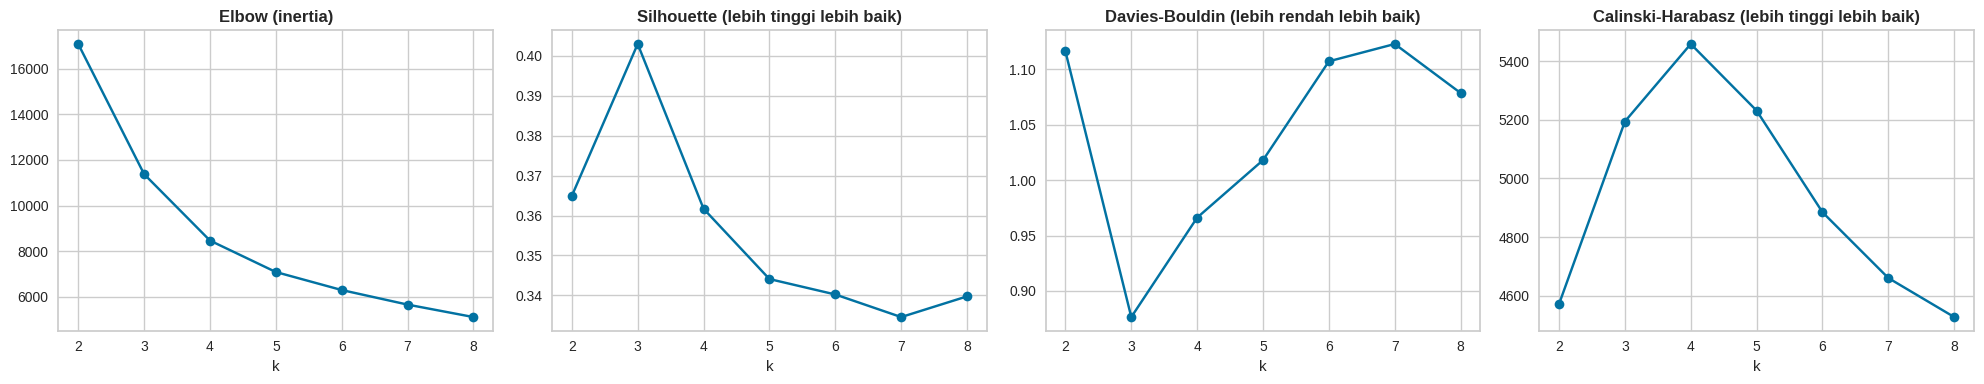


K_FINAL (aturan: k 3-6, cluster terkecil >= 5%, silhouette tertinggi) = 3
Anda dapat menimpa nilai ini (K_FINAL = ...) sebelum menjalankan sel berikutnya jika setelah melihat grafik ada alasan kuat.


In [ ]:
K_RANGE = range(2, 9)
rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=RS).fit(X_cl)
    lab = km.labels_
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_cl, lab),
                 "davies_bouldin": davies_bouldin_score(X_cl, lab),
                 "calinski_harabasz": calinski_harabasz_score(X_cl, lab),
                 "min_cluster_share": np.bincount(lab).min() / len(lab)})
km_df = pd.DataFrame(rows).set_index("k")
display(km_df.round(4))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (col, ttl) in zip(axes, [("inertia", "Elbow (inertia)"), ("silhouette", "Silhouette (lebih tinggi lebih baik)"),
                                 ("davies_bouldin", "Davies-Bouldin (lebih rendah lebih baik)"),
                                 ("calinski_harabasz", "Calinski-Harabasz (lebih tinggi lebih baik)")]):
    ax.plot(km_df.index, km_df[col], marker="o"); ax.set_title(ttl); ax.set_xlabel("k")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["segmentation"], "06_kmeans_k_selection.png"), dpi=150, bbox_inches="tight")
plt.show()

cand = km_df[(km_df.index >= 3) & (km_df.index <= 6) & (km_df["min_cluster_share"] >= 0.05)]
K_FINAL = int(cand["silhouette"].idxmax()) if len(cand) else int(km_df.loc[3:6, "silhouette"].idxmax())
print(f"\nK_FINAL (aturan: k 3-6, cluster terkecil >= 5%, silhouette tertinggi) = {K_FINAL}")
print("Anda dapat menimpa nilai ini (K_FINAL = ...) sebelum menjalankan sel berikutnya jika setelah melihat grafik ada alasan kuat.")

### Sel 33: Hierarchical Clustering
Membandingkan tiga linkage (Ward, average, complete) lewat **cophenetic correlation** (seberapa setia dendrogram pada jarak asli), lalu menggambar dendrogram Ward. Pada sampel 2.500 untuk efisiensi, dan seluruh data untuk dendrogram final.

Perbandingan linkage (sampel 2.500):


,linkage,cophenetic_corr,silhouette@K_FINAL,min_cluster_share
0,ward,0.6467,0.3728,0.1384
1,average,0.7340,0.3349,0.1412
2,complete,0.6238,0.2547,0.1420


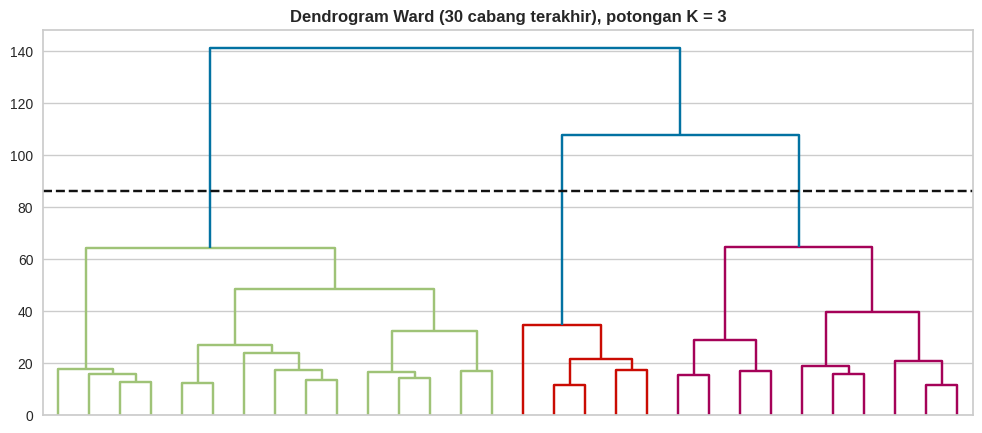

,silhouette,davies_bouldin,calinski_harabasz,min_cluster_share
k,,,,
2,0.3248,1.2370,"3,846.7727",0.3994
3,0.3702,0.9403,"4,453.7298",0.1430
4,0.3095,0.9718,"4,030.8983",0.1430
5,0.2948,1.0785,"4,211.0775",0.1149
6,0.3098,1.1889,"4,142.3065",0.1149
7,0.3023,1.1653,"4,015.0872",0.1149
8,0.3018,1.0972,"3,895.3221",0.0523


In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist

samp_h = rng.choice(len(X_cl), 2500, replace=False)
d_h = pdist(X_cl[samp_h])
rows = []
for m in ["ward", "average", "complete"]:
    Zs = linkage(X_cl[samp_h], method=m)
    lab = fcluster(Zs, K_FINAL, "maxclust") - 1
    rows.append({"linkage": m, "cophenetic_corr": cophenet(Zs, d_h)[0],
                 "silhouette@K_FINAL": silhouette_score(X_cl[samp_h], lab),
                 "min_cluster_share": np.bincount(lab).min() / len(lab)})
link_df = pd.DataFrame(rows)
print("Perbandingan linkage (sampel 2.500):")
display(link_df.round(4))

Zfull = linkage(X_cl, method="ward")
cut = (Zfull[-(K_FINAL - 1), 2] + Zfull[-K_FINAL, 2]) / 2
plt.figure(figsize=(12, 5))
dendrogram(Zfull, truncate_mode="lastp", p=30, no_labels=True, color_threshold=cut)
plt.axhline(cut, color="k", ls="--"); plt.title(f"Dendrogram Ward (30 cabang terakhir), potongan K = {K_FINAL}")
plt.savefig(os.path.join(PATHS["segmentation"], "06_dendrogram.png"), dpi=150, bbox_inches="tight")
plt.show()

rows = []
for k in K_RANGE:
    lab = fcluster(Zfull, k, "maxclust") - 1
    rows.append({"k": k, "silhouette": silhouette_score(X_cl, lab), "davies_bouldin": davies_bouldin_score(X_cl, lab),
                 "calinski_harabasz": calinski_harabasz_score(X_cl, lab), "min_cluster_share": np.bincount(lab).min() / len(lab)})
hc_df = pd.DataFrame(rows).set_index("k")
display(hc_df.round(4))
hc_lab = fcluster(Zfull, K_FINAL, "maxclust") - 1

### Sel 34: Gaussian Mixture Model (GMM)
GMM memberi **probabilitas keanggotaan** (soft clustering), bukan keanggotaan keras. Dipilih lewat **AIC/BIC** (lebih rendah lebih baik; BIC menghukum kompleksitas lebih kuat). Dua tipe kovarians diuji (`full` dan `diag`). Catatan: `contract_ord` dan `n_addon_services` bersifat diskret, sehingga asumsi Gaussian hanya pendekatan.

,cov,k,AIC,BIC,silhouette,mean_max_posterior,min_cluster_share
0,full,2,"14,969.7580","15,168.6920",0.3360,1.0000,0.4500
1,full,3,"-3,417.6940","-3,115.8630",0.3540,0.9930,0.2270
2,full,4,"-30,239.2800","-29,834.5520",0.2850,0.9920,0.1500
3,full,5,"-37,531.7740","-37,024.1490",0.2290,0.9990,0.0680
4,full,6,"-42,002.7840","-41,392.2630",0.2480,0.9980,0.0850
5,full,7,"-42,882.9030","-42,169.4850",0.2340,0.9950,0.0750
6,full,8,"-45,803.3550","-44,987.0400",0.1940,0.9710,0.0750
7,diag,2,"23,749.9420","23,866.5590",0.3360,1.0000,0.4500
8,diag,3,"1,436.4680","1,614.8230",0.3550,0.9980,0.2280
9,diag,4,"-26,210.1580","-25,970.0650",0.2860,0.9980,0.1500


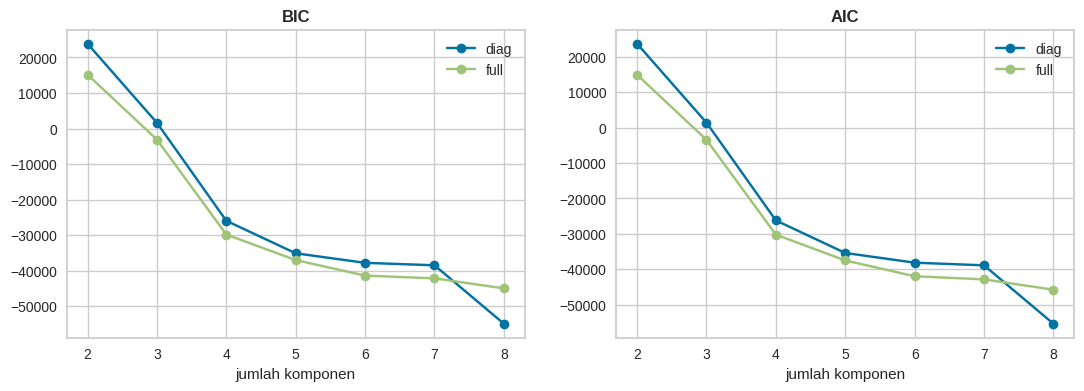

BIC terendah: cov=diag, k=8
Tipe kovarians GMM untuk K_FINAL=3 (BIC terendah): full
Catatan: contract_ord dan n_addon_services bersifat diskret, sehingga asumsi Gaussian GMM hanya pendekatan.


In [ ]:
rows = []
for cov in ["full", "diag"]:
    for k in K_RANGE:
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=RS).fit(X_cl)
        lab = g.predict(X_cl)
        rows.append({"cov": cov, "k": k, "AIC": g.aic(X_cl), "BIC": g.bic(X_cl),
                     "silhouette": silhouette_score(X_cl, lab),
                     "mean_max_posterior": g.predict_proba(X_cl).max(1).mean(),
                     "min_cluster_share": np.bincount(lab, minlength=k).min() / len(lab)})
gmm_df = pd.DataFrame(rows)
display(gmm_df.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for cov, g_ in gmm_df.groupby("cov"):
    axes[0].plot(g_["k"], g_["BIC"], marker="o", label=cov)
    axes[1].plot(g_["k"], g_["AIC"], marker="o", label=cov)
axes[0].set_title("BIC"); axes[1].set_title("AIC")
for ax in axes: ax.legend(); ax.set_xlabel("jumlah komponen")
plt.savefig(os.path.join(PATHS["segmentation"], "06_gmm_aic_bic.png"), dpi=150, bbox_inches="tight")
plt.show()

best_bic = gmm_df.loc[gmm_df["BIC"].idxmin()]
print(f"BIC terendah: cov={best_bic['cov']}, k={int(best_bic['k'])}")
gmm_cov_final = gmm_df[gmm_df["k"] == K_FINAL].sort_values("BIC").iloc[0]["cov"]
print(f"Tipe kovarians GMM untuk K_FINAL={K_FINAL} (BIC terendah): {gmm_cov_final}")
print("Catatan: contract_ord dan n_addon_services bersifat diskret, sehingga asumsi Gaussian GMM hanya pendekatan.")
gmm_final = GaussianMixture(K_FINAL, covariance_type=gmm_cov_final, n_init=10, random_state=RS).fit(X_cl)
gmm_lab = gmm_final.predict(X_cl)

### Sel 35: Mixed-data (K-Prototypes dan Gower + K-Medoids)
Dua metode yang menangani numerik dan kategorikal sekaligus:
- **K-Prototypes**: gabungan K-Means (numerik) dan K-Modes (kategorikal).
- **Gower + K-Medoids**: jarak Gower bekerja untuk tipe campuran; K-Medoids memakai data nyata sebagai pusat cluster.

Sel ini paling lama (sekitar 5 sampai 10 menit). Jika error, bagian ini dilewati dan analisis tetap berlanjut. Atur `RUN_MIXED = False` untuk melewatinya sengaja.

In [ ]:
RUN_MIXED = True
MIX_NUM = ["tenure", "MonthlyCharges", "n_addon_services"]
MIX_CAT = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "SeniorCitizen", "Partner", "Dependents"]
X_mix = df_feat[MIX_NUM + MIX_CAT].copy()
samp_g = rng.choice(len(X_mix), 3000, replace=False)
kp_lab, kmed_lab_s, G, mixed_df = None, None, None, None

if RUN_MIXED:
    try:
        import gower
        from kmodes.kprototypes import KPrototypes
        from sklearn_extra.cluster import KMedoids

        X_kp = X_mix.copy()
        X_kp[MIX_NUM] = StandardScaler().fit_transform(X_mix[MIX_NUM])
        cat_idx = list(range(len(MIX_NUM), len(MIX_NUM) + len(MIX_CAT)))
        G = gower.gower_matrix(X_mix.iloc[samp_g].reset_index(drop=True))

        rows, kp_labels = [], {}
        for k in range(2, 7):
            kp = KPrototypes(n_clusters=k, init="Cao", n_init=2, random_state=RS, n_jobs=-1)
            lab = kp.fit_predict(X_kp.values, categorical=cat_idx)
            kp_labels[k] = lab
            kmd = KMedoids(n_clusters=k, metric="precomputed", method="pam", init="k-medoids++", random_state=RS).fit(G)
            rows.append({"k": k, "kproto_cost": kp.cost_,
                         "kproto_silhouette_gower": silhouette_score(G, lab[samp_g], metric="precomputed"),
                         "kmedoids_silhouette_gower": silhouette_score(G, kmd.labels_, metric="precomputed"),
                         "kproto_min_share": np.bincount(lab).min() / len(lab),
                         "kmedoids_min_share": np.bincount(kmd.labels_).min() / len(samp_g)})
            if k == K_FINAL:
                kmed_lab_s = kmd.labels_
        mixed_df = pd.DataFrame(rows).set_index("k")
        display(mixed_df.round(4))
        kp_lab = kp_labels.get(K_FINAL)
    except Exception as e:
        print(f"Pendekatan mixed-data dilewati karena error: {type(e).__name__}: {e}")
        print("Analisis tetap berlanjut dengan K-Means, Hierarchical, dan GMM.")

Pendekatan mixed-data dilewati karena error: ModuleNotFoundError: No module named 'gower'
Analisis tetap berlanjut dengan K-Means, Hierarchical, dan GMM.


### Sel 36: Perbandingan metode pada K_FINAL
Indikator: silhouette di ruang Gower (bisa dibandingkan lintas metode), **stabilitas ARI** (dua subsampel 70% di-fit terpisah lalu dibandingkan), ukuran cluster terkecil, dan spread churn pasca-hoc (hanya gambaran, tidak dipakai memilih metode).

**Aturan metode final:** GMM dipilih hanya jika silhouette **dan** stabilitasnya lebih tinggi dari K-Means; selain itu K-Means (lebih sederhana). Hanya K-Means dan GMM yang dapat memprediksi pelanggan baru, sehingga hanya keduanya yang bisa dideploy ke Streamlit.

In [ ]:
def stability_ari(make_model, X, n_rep=20, frac=0.7):
    r = np.random.RandomState(RS); sc = []
    for _ in range(n_rep):
        a = r.choice(len(X), int(frac * len(X)), replace=False)
        b = r.choice(len(X), int(frac * len(X)), replace=False)
        sc.append(adjusted_rand_score(make_model().fit(X[a]).predict(X), make_model().fit(X[b]).predict(X)))
    return float(np.mean(sc)), float(np.std(sc))

km_final = KMeans(K_FINAL, n_init=50, random_state=RS).fit(X_cl)
km_lab = km_final.labels_
stab_km = stability_ari(lambda: KMeans(K_FINAL, n_init=10, random_state=RS), X_cl)
stab_gmm = stability_ari(lambda: GaussianMixture(K_FINAL, covariance_type=gmm_cov_final, n_init=3, random_state=RS), X_cl)

def churn_spread(lab, y):
    rate = pd.Series(y).groupby(lab).mean()
    ct = pd.crosstab(lab, y)
    return (rate.max() - rate.min()) * 100, stats.chi2_contingency(ct)[1]

comp_rows = []
def add_row(name, lab_full, lab_samp, own_sil, stab):
    sp, pv = churn_spread(lab_full, y_all) if lab_full is not None else churn_spread(lab_samp, y_all[samp_g])
    comp_rows.append({
        "metode": name, "k": len(np.unique(lab_samp)),
        "silhouette_ruang_sendiri": own_sil,
        "silhouette_gower_sampel": silhouette_score(G, lab_samp, metric="precomputed") if G is not None else np.nan,
        "stabilitas_ARI_mean": stab[0] if stab else np.nan, "stabilitas_ARI_sd": stab[1] if stab else np.nan,
        "cluster_terkecil_%": np.bincount(lab_samp).min() / len(lab_samp) * 100,
        "spread_churn_pp(pasca-hoc)": sp, "p_chi2_churn(pasca-hoc)": pv})

add_row("K-Means", km_lab, km_lab[samp_g], silhouette_score(X_cl, km_lab), stab_km)
add_row("Hierarchical (Ward)", hc_lab, hc_lab[samp_g], silhouette_score(X_cl, hc_lab), None)
add_row("GMM", gmm_lab, gmm_lab[samp_g], silhouette_score(X_cl, gmm_lab), stab_gmm)
if kp_lab is not None:
    add_row("K-Prototypes", kp_lab, kp_lab[samp_g], np.nan, None)
    add_row("Gower + K-Medoids (sampel)", None, kmed_lab_s, np.nan, None)
method_cmp = pd.DataFrame(comp_rows)
display(method_cmp.style.format({c: "{:.3f}" for c in method_cmp.columns if c not in ["metode", "k", "p_chi2_churn(pasca-hoc)"]} |
                                {"p_chi2_churn(pasca-hoc)": "{:.2e}"}))

lab_dict = {"K-Means": km_lab, "Hierarchical": hc_lab, "GMM": gmm_lab}
if kp_lab is not None: lab_dict["K-Prototypes"] = kp_lab
names_ = list(lab_dict)
agree = pd.DataFrame([[adjusted_rand_score(lab_dict[a], lab_dict[b]) for b in names_] for a in names_], index=names_, columns=names_)
print("\nKesepakatan antar-metode (Adjusted Rand Index; 1 = identik):")
display(agree.round(3))

# Aturan pemilihan metode final (hanya K-Means/GMM karena keduanya dapat memprediksi pelanggan baru)
sil_km, sil_gmm = silhouette_score(X_cl, km_lab), silhouette_score(X_cl, gmm_lab)
FINAL_METHOD = "gmm" if (sil_gmm > sil_km and stab_gmm[0] > stab_km[0]) else "kmeans"
print(f"\nFINAL_METHOD = {FINAL_METHOD}  (GMM dipilih hanya jika silhouette DAN stabilitasnya lebih tinggi daripada K-Means; "
      f"selain itu K-Means dipakai karena lebih sederhana dan mudah diinterpretasi).")
print("Hierarchical, K-Prototypes, dan K-Medoids dipakai sebagai pembanding robustness; tidak dideploy karena tidak praktis untuk "
      "memprediksi pelanggan baru dalam aplikasi.")

,metode,k,silhouette_ruang_sendiri,silhouette_gower_sampel,stabilitas_ARI_mean,stabilitas_ARI_sd,cluster_terkecil_%,spread_churn_pp(pasca-hoc),p_chi2_churn(pasca-hoc)
0,K-Means,3,0.403,nan,0.987,0.011,16.233,40.398,1.25e-223
1,Hierarchical (Ward),3,0.370,nan,nan,nan,14.033,43.469,4.29e-239
2,GMM,3,0.354,nan,0.998,0.003,21.433,37.363,3.79e-272



Kesepakatan antar-metode (Adjusted Rand Index; 1 = identik):


,K-Means,Hierarchical,GMM
K-Means,1.0000,0.7020,0.5290
Hierarchical,0.7020,1.0000,0.5470
GMM,0.5290,0.5470,1.0000



FINAL_METHOD = kmeans  (GMM dipilih hanya jika silhouette DAN stabilitasnya lebih tinggi daripada K-Means; selain itu K-Means dipakai karena lebih sederhana dan mudah diinterpretasi).
Hierarchical, K-Prototypes, dan K-Medoids dipakai sebagai pembanding robustness; tidak dideploy karena tidak praktis untuk memprediksi pelanggan baru dalam aplikasi.


### Sel 37: Model segmentasi final, profil, dan penamaan
1. Membangun `segment_pipe` (scaler + model) pada data penuh.
2. **Relabel** cluster agar ID segmen berurut dari tenure rata-rata terendah ke tertinggi (ID stabil dan mudah dibaca).
3. Membuat tabel profil per segmen (tenure, tagihan, kontrak, internet, pembayaran, demografi, churn).
4. Menghitung churn per segmen dengan **interval kepercayaan Wilson 95%** dan uji chi-square (pasca-hoc).
5. Memberi nama otomatis dari karakteristik aktual (tercile). Timpa lewat `SEGMENT_NAME_OVERRIDE`, misalnya `{0: "New & Vulnerable Customers"}`.

In [ ]:
model = (KMeans(K_FINAL, n_init=50, random_state=RS) if FINAL_METHOD == "kmeans"
         else GaussianMixture(K_FINAL, covariance_type=gmm_cov_final, n_init=10, random_state=RS))
segment_pipe = Pipeline([("scaler", StandardScaler()), ("model", model)]).fit(X_cl_raw)
raw_lab = segment_pipe.predict(X_cl_raw)

# Relabel: urut dari rata-rata tenure terendah ke tertinggi (agar ID segmen stabil dan mudah dibaca)
order = pd.Series(df_feat["tenure"].values).groupby(raw_lab).mean().sort_values().index
segment_label_map = {int(old): int(new) for new, old in enumerate(order)}
df_feat["segment_id"] = pd.Series(raw_lab).map(segment_label_map).values

sid = df_feat["segment_id"]
share = lambda cond: cond.groupby(sid).mean() * 100
g = df_feat.groupby("segment_id")
prof = pd.DataFrame({
    "n": g.size(), "share_%": g.size() / len(df_feat) * 100,
    "tenure_mean": g["tenure"].mean(), "tenure_median": g["tenure"].median(),
    "monthly_mean": g["MonthlyCharges"].mean(), "total_mean": g["TotalCharges"].mean(),
    "n_addon_mean": g["n_addon_services"].mean(), "service_count_mean": g["total_service_count"].mean(),
    "annual_value_mean": g["annual_value_proxy"].mean(),
    "pct_month_to_month": share(df_feat["Contract"] == "Month-to-month"),
    "pct_one_year": share(df_feat["Contract"] == "One year"),
    "pct_two_year": share(df_feat["Contract"] == "Two year"),
    "pct_fiber": share(df_feat["InternetService"] == "Fiber optic"),
    "pct_dsl": share(df_feat["InternetService"] == "DSL"),
    "pct_no_internet": share(df_feat["InternetService"] == "No"),
    "pct_echeck": share(df_feat["PaymentMethod"] == "Electronic check"),
    "pct_paperless": share(df_feat["PaperlessBilling"] == "Yes"),
    "pct_senior": share(df_feat["SeniorCitizen"] == "Yes"),
    "pct_partner": share(df_feat["Partner"] == "Yes"),
    "pct_dependents": share(df_feat["Dependents"] == "Yes"),
    "churn_rate_%": g["Churn_flag"].mean() * 100})

# Churn per segmen dengan CI 95% Wilson + uji chi-square (pasca-hoc, bukan dasar pembentukan cluster)
from statsmodels.stats.proportion import proportion_confint
nch = g["Churn_flag"].sum()
ci = [proportion_confint(nch[i], prof.loc[i, "n"], method="wilson") for i in prof.index]
prof["churn_ci_low_%"] = [c[0] * 100 for c in ci]; prof["churn_ci_high_%"] = [c[1] * 100 for c in ci]
ct_seg = pd.crosstab(df_feat["segment_id"], df_feat["Churn"])
chi2_s, p_s, _, _ = stats.chi2_contingency(ct_seg)
v_s = cramers_v(ct_seg)

display(prof.T.round(2))
print(f"\nChurn vs segmen: chi2 = {chi2_s:.1f}, p = {p_s:.2e}, Cramér's V = {v_s:.3f}")

# Penamaan otomatis dari karakteristik aktual (tercile global); timpa lewat SEGMENT_NAME_OVERRIDE setelah ditinjau
t33, t67 = df_feat["tenure"].quantile([1 / 3, 2 / 3]); m33, m67 = df_feat["MonthlyCharges"].quantile([1 / 3, 2 / 3])
dom_map = {"pct_month_to_month": "Kontrak bulanan", "pct_one_year": "Kontrak 1 thn", "pct_two_year": "Kontrak 2 thn"}
SEGMENT_NAME_OVERRIDE = {}   # contoh: {0: "New & Vulnerable Customers"}
seg_names = {}
for i, r in prof.iterrows():
    ten = "Baru" if r["tenure_mean"] < t33 else ("Loyal" if r["tenure_mean"] > t67 else "Menengah")
    bil = "tagihan rendah" if r["monthly_mean"] < m33 else ("tagihan tinggi" if r["monthly_mean"] > m67 else "tagihan sedang")
    dom = dom_map[r[list(dom_map)].astype(float).idxmax()]
    seg_names[int(i)] = SEGMENT_NAME_OVERRIDE.get(int(i), f"S{i}: {ten} | {bil} | {dom}")
df_feat["segment_name"] = df_feat["segment_id"].map(seg_names)
prof["segment_name"] = pd.Series(seg_names)
print("\nNama segmen (provisional, berdasar karakteristik aktual):")
for k_, v_ in seg_names.items(): print(f"  {v_}")

segment_id,0,1,2
n,"3,651.0000","1,165.0000","2,227.0000"
share_%,51.8400,16.5400,31.6200
tenure_mean,14.6500,42.0300,56.3600
tenure_median,10.0000,44.0000,60.0000
monthly_mean,63.0300,24.5000,88.6600
total_mean,996.9100,"1,054.0500","5,024.0100"
n_addon_mean,1.3400,0.2300,4.1200
service_count_mean,3.4300,1.5600,6.6700
annual_value_mean,756.4000,294.0200,"1,063.8700"
pct_month_to_month,95.2600,0.6000,17.5100



Churn vs segmen: chi2 = 1026.5, p = 1.25e-223, Cramér's V = 0.381

Nama segmen (provisional, berdasar karakteristik aktual):
  S0: Menengah | tagihan sedang | Kontrak bulanan
  S1: Menengah | tagihan rendah | Kontrak 2 thn
  S2: Loyal | tagihan tinggi | Kontrak 2 thn


### Sel 38: Visualisasi segmen
Empat panel: heatmap profil (warna = z-score antar segmen, angka = nilai asli), proyeksi **PCA** 2 dimensi, scatter tenure vs tagihan per segmen, dan churn rate per segmen dengan CI 95%. Hasil profil disimpan ke CSV.

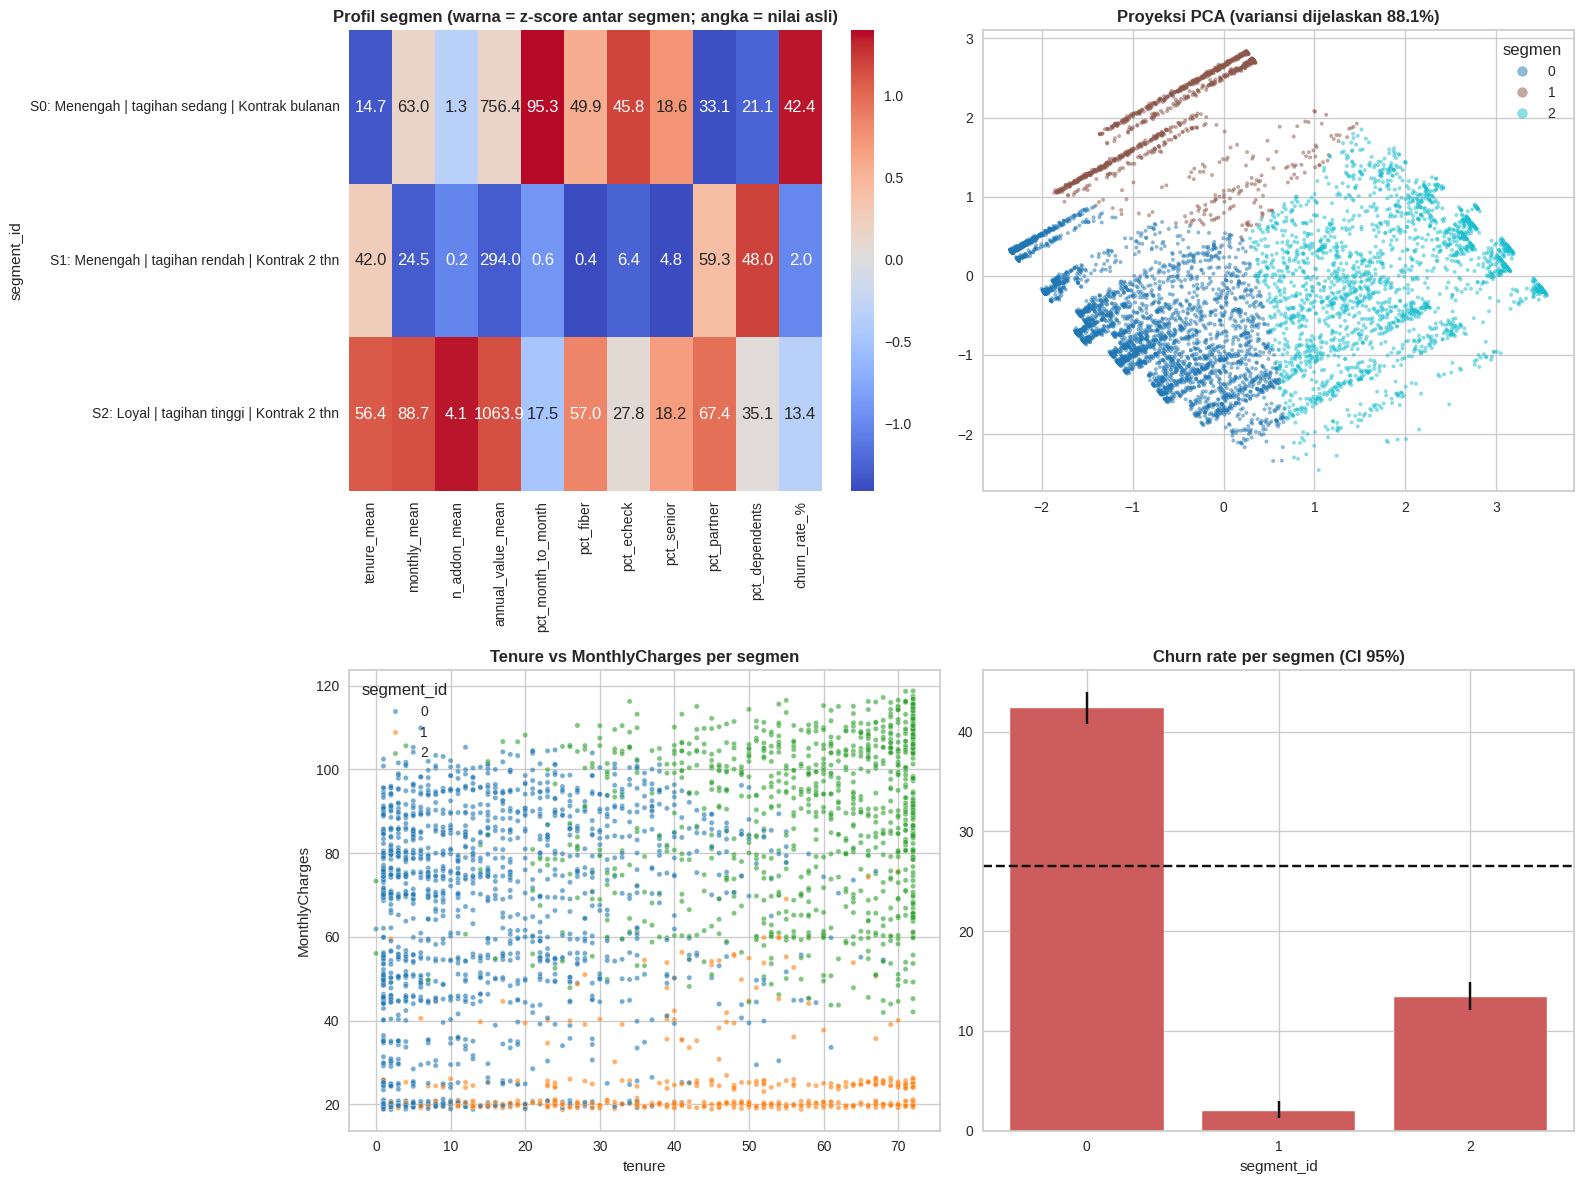

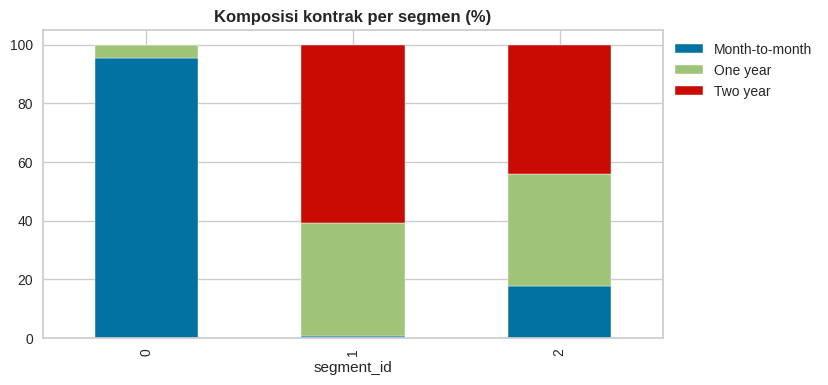

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
zcols = ["tenure_mean", "monthly_mean", "n_addon_mean", "annual_value_mean", "pct_month_to_month", "pct_fiber",
         "pct_echeck", "pct_senior", "pct_partner", "pct_dependents", "churn_rate_%"]
z = (prof[zcols] - prof[zcols].mean()) / prof[zcols].std(ddof=0)
sns.heatmap(z.rename(index=seg_names), annot=prof[zcols].round(1).rename(index=seg_names), fmt="", cmap="coolwarm", center=0, ax=axes[0, 0])
axes[0, 0].set_title("Profil segmen (warna = z-score antar segmen; angka = nilai asli)")

pca = PCA(2, random_state=RS).fit(X_cl)
pc = pca.transform(X_cl)
sc = axes[0, 1].scatter(pc[:, 0], pc[:, 1], c=df_feat["segment_id"], cmap="tab10", s=6, alpha=0.5)
axes[0, 1].set_title(f"Proyeksi PCA (variansi dijelaskan {pca.explained_variance_ratio_.sum()*100:.1f}%)")
axes[0, 1].legend(*sc.legend_elements(), title="segmen")

sns.scatterplot(data=df_feat.sample(3000, random_state=RS), x="tenure", y="MonthlyCharges", hue="segment_id",
                palette="tab10", s=14, alpha=0.6, ax=axes[1, 0])
axes[1, 0].set_title("Tenure vs MonthlyCharges per segmen")

cr = prof[["churn_rate_%", "churn_ci_low_%", "churn_ci_high_%"]]
axes[1, 1].bar(cr.index.astype(str), cr["churn_rate_%"], yerr=[cr["churn_rate_%"] - cr["churn_ci_low_%"], cr["churn_ci_high_%"] - cr["churn_rate_%"]],
               color="indianred", capsize=4)
axes[1, 1].axhline(OVERALL_CHURN * 100, color="k", ls="--"); axes[1, 1].set_title("Churn rate per segmen (CI 95%)")
axes[1, 1].set_xlabel("segment_id")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["segmentation"], "06_profil_segmen.png"), dpi=150, bbox_inches="tight")
plt.show()

mix = pd.crosstab(df_feat["segment_id"], df_feat["Contract"], normalize="index") * 100
mix.plot(kind="bar", stacked=True, figsize=(8, 4)); plt.title("Komposisi kontrak per segmen (%)"); plt.legend(bbox_to_anchor=(1, 1))
plt.savefig(os.path.join(PATHS["segmentation"], "06_kontrak_per_segmen.png"), dpi=150, bbox_inches="tight")
plt.show()

prof.to_csv(os.path.join(PATHS["segmentation"], "segment_profiles.csv"))
km_df.to_csv(os.path.join(PATHS["segmentation"], "kmeans_k_selection.csv"))
method_cmp.to_csv(os.path.join(PATHS["segmentation"], "method_comparison.csv"), index=False)

---
# TAHAP 7: Customer Churn Analysis (terpisah dari clustering)

**Tujuan:** memahami siapa yang churn, kapan, dan faktor apa yang tetap berasosiasi setelah faktor lain dikontrol.

**Empat pendekatan:**
1. **Risiko relatif**: berapa kali lebih sering churn pada kelompok dengan karakteristik tertentu.
2. **Kaplan-Meier (survival)**: probabilitas pelanggan bertahan menurut waktu. Tenure dipakai sebagai waktu dan Churn sebagai kejadian. Pelanggan non-churn diperlakukan sebagai **tersensor** pada tenure saat ini (ini asumsi, karena data hanya satu snapshot).
3. **Regresi logistik terkontrol**: odds ratio tiap faktor dengan faktor lain dikontrol.
4. **Kombinasi churn tinggi**: kombinasi kontrak, internet, pembayaran, dan kelompok tenure dengan churn terbesar.

### Sel 39: Profil churner dan risiko relatif
**Risiko relatif (RR)** = churn rate kelompok "ya" / churn rate kelompok "tidak". RR 2 berarti dua kali lebih sering churn. P-value dikoreksi Holm.

In [ ]:
flags = {
    "Kontrak bulanan": df_feat["Contract"] == "Month-to-month",
    "Internet fiber optic": df_feat["InternetService"] == "Fiber optic",
    "Bayar electronic check": df_feat["PaymentMethod"] == "Electronic check",
    "Paperless billing": df_feat["PaperlessBilling"] == "Yes",
    "Senior citizen": df_feat["SeniorCitizen"] == "Yes",
    "Tanpa partner": df_feat["Partner"] == "No",
    "Tanpa tanggungan": df_feat["Dependents"] == "No",
    "Tenure <= 12 bulan": df_feat["tenure"] <= 12,
    "Tanpa TechSupport (pelanggan internet)": (df_feat["InternetService"] != "No") & (df_feat["TechSupport"] == "No"),
    "Tanpa OnlineSecurity (pelanggan internet)": (df_feat["InternetService"] != "No") & (df_feat["OnlineSecurity"] == "No"),
    "Tanpa add-on sama sekali (pelanggan internet)": (df_feat["InternetService"] != "No") & (df_feat["n_addon_services"] == 0),
    "Tagihan bulanan di atas Q3": df_feat["MonthlyCharges"] >= df_feat["MonthlyCharges"].quantile(0.75),
}
y = df_feat["Churn_flag"]
rows = []
for name, f in flags.items():
    a, b = y[f].mean(), y[~f].mean()
    ct = pd.crosstab(f, y)
    rows.append({"karakteristik": name, "n_ya": int(f.sum()), "%_di_churner": f[y == 1].mean() * 100,
                 "%_di_non_churner": f[y == 0].mean() * 100, "churn_rate_ya_%": a * 100,
                 "churn_rate_tidak_%": b * 100, "risiko_relatif": a / b, "p_chi2": stats.chi2_contingency(ct)[1]})
risk_df = pd.DataFrame(rows).sort_values("risiko_relatif", ascending=False)
risk_df["p_holm"] = multipletests(risk_df["p_chi2"], method="holm")[1]
display(risk_df.style.format({c: "{:.2f}" for c in risk_df.columns if c not in ["karakteristik", "n_ya", "p_chi2", "p_holm"]} |
                             {"p_chi2": "{:.2e}", "p_holm": "{:.2e}"}))

num_prof = df_feat.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges", "n_addon_services", "total_service_count"]].agg(["mean", "median"]).round(2)
display(num_prof)

,karakteristik,n_ya,%_di_churner,%_di_non_churner,churn_rate_ya_%,churn_rate_tidak_%,risiko_relatif,p_chi2,p_holm
0,Kontrak bulanan,3875,88.55,42.91,42.71,6.76,6.32,6.15e-253,7.38e-252
9,Tanpa OnlineSecurity (pelanggan internet),3498,78.17,39.37,41.77,11.51,3.63,1.71e-181,1.88e-180
8,Tanpa TechSupport (pelanggan internet),3473,77.37,39.18,41.64,11.85,3.51,6.36e-176,6.36e-175
1,Internet fiber optic,3096,69.40,34.77,41.89,14.49,2.89,4.94e-147,3.95e-146
7,Tenure <= 12 bulan,2186,55.48,22.21,47.44,17.13,2.77,3.68e-156,3.31e-155
2,Bayar electronic check,2365,57.30,25.01,45.29,17.06,2.65,2.53e-141,1.77e-140
10,Tanpa add-on sama sekali (pelanggan internet),693,19.37,6.40,52.24,23.73,2.20,2.91e-58,1.75e-57
3,Paperless billing,4171,74.91,53.56,33.57,16.33,2.06,4.07e-58,2.04e-57
6,Tanpa tanggungan,4933,82.56,65.52,31.28,15.45,2.02,4.92e-43,1.97e-42
4,Senior citizen,1142,25.47,12.87,41.68,23.61,1.77,1.51e-36,4.53e-36


tenure         MonthlyCharges         TotalCharges             \
         mean  median           mean  median         mean     median   
Churn                                                                  
No    37.5700 38.0000        61.2700 64.4300   2,549.9100 1,679.5200   
Yes   17.9800 10.0000        74.4400 79.6500   1,531.8000   703.5500   

      n_addon_services        total_service_count         
                  mean median                mean median  
Churn                                                     
No              2.1400 2.0000              4.1700 4.0000  
Yes             1.7700 2.0000              4.0700 4.0000

### Sel 40: Survival Kaplan-Meier
Kurva menunjukkan P(masih berlangganan) pada tiap bulan, per kontrak, jenis internet, dan segmen. **Uji log-rank** menguji apakah kurva antar kelompok berbeda. Tabel akhir memberi probabilitas bertahan pada bulan ke-12, 24, dan 48 per kontrak.

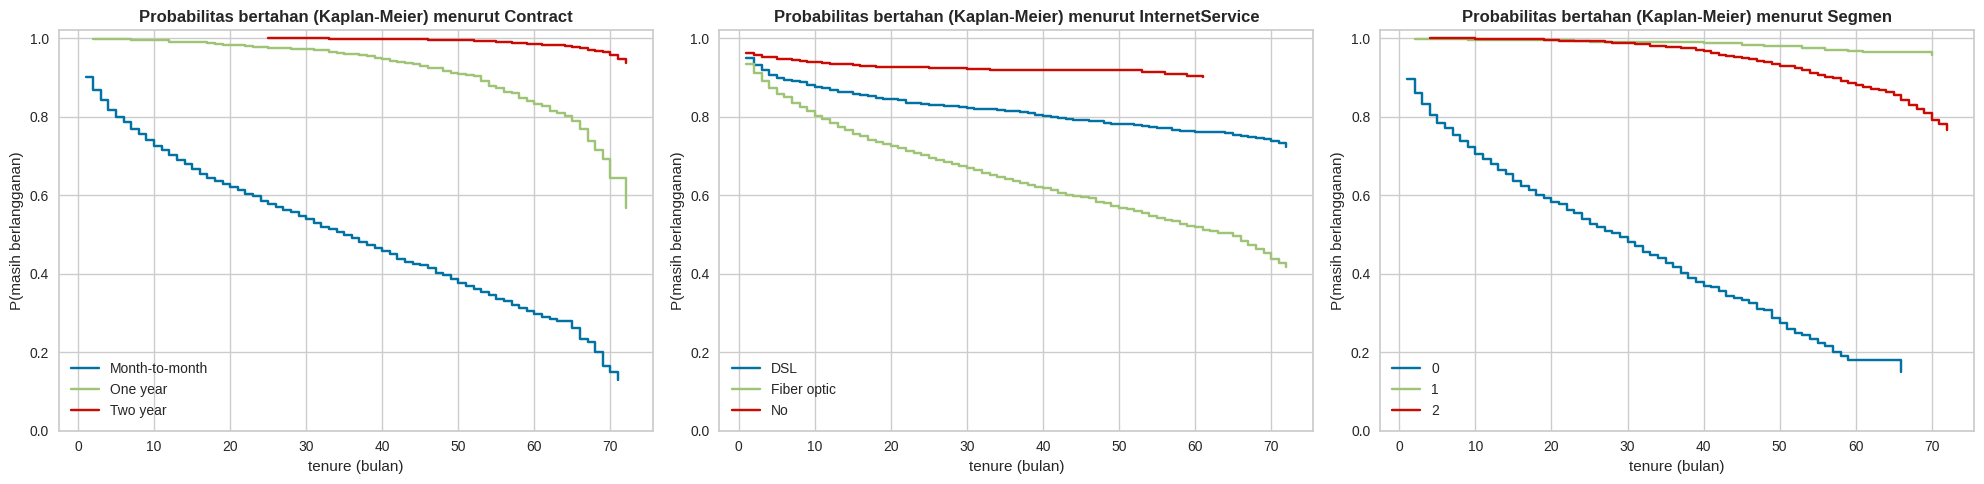

Log-rank Contract        : chi2 = 2,352.9, p = 0.00e+00
Log-rank InternetService : chi2 = 520.1, p = 0.00e+00
Log-rank segment_id      : chi2 = 2,593.3, p = 0.00e+00

Probabilitas bertahan pada bulan ke-12, 24, 48 per Contract:


,S(12),S(24),S(48)
Month-to-month,0.7030,0.5860,0.3970
One year,0.9910,0.9770,0.9170
Two year,0.9990,0.9990,0.9960


In [ ]:
from statsmodels.duration.survfunc import SurvfuncRight, survdiff

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (grp, ttl) in zip(axes, [("Contract", "Contract"), ("InternetService", "InternetService"), ("segment_id", "Segmen")]):
    for lab, gdf in df_feat.groupby(grp):
        sf = SurvfuncRight(gdf["tenure"], gdf["Churn_flag"])
        ax.step(sf.surv_times, sf.surv_prob, where="post", label=str(lab))
    ax.set_title(f"Probabilitas bertahan (Kaplan-Meier) menurut {ttl}")
    ax.set_xlabel("tenure (bulan)"); ax.set_ylabel("P(masih berlangganan)"); ax.legend(); ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig(os.path.join(PATHS["figures"], "07_kaplan_meier.png"), dpi=150, bbox_inches="tight")
plt.show()

for grp in ["Contract", "InternetService", "segment_id"]:
    chi, p = survdiff(df_feat["tenure"], df_feat["Churn_flag"], df_feat[grp])
    print(f"Log-rank {grp:<16}: chi2 = {chi:,.1f}, p = {p:.2e}")

print("\nProbabilitas bertahan pada bulan ke-12, 24, 48 per Contract:")
rows = {}
for lab, gdf in df_feat.groupby("Contract"):
    sf = SurvfuncRight(gdf["tenure"], gdf["Churn_flag"])
    rows[lab] = {f"S({t})": float(np.interp(t, sf.surv_times, sf.surv_prob)) for t in [12, 24, 48]}
display(pd.DataFrame(rows).T.round(3))

### Sel 41: Regresi logistik terkontrol (odds ratio)
**Odds ratio (OR)**: OR > 1 berarti faktor meningkatkan odds churn, OR < 1 menurunkannya, dengan faktor lain dikontrol. Level acuan mengikuti urutan alfabet (misalnya Contract = Month-to-month, InternetService = DSL). Ini asosiasi terkontrol, **bukan efek kausal**.

In [ ]:
import statsmodels.formula.api as smf
formula = ("Churn_flag ~ tenure + MonthlyCharges + C(Contract) + C(InternetService) + C(PaymentMethod) + C(PaperlessBilling)"
           " + C(SeniorCitizen) + C(Partner) + C(Dependents) + C(MultipleLines) + C(OnlineSecurity) + C(OnlineBackup)"
           " + C(DeviceProtection) + C(TechSupport) + C(StreamingTV) + C(StreamingMovies)")
logit = smf.logit(formula, data=df_feat).fit(disp=0, maxiter=200)
ci_ = logit.conf_int()
or_df = pd.DataFrame({"odds_ratio": np.exp(logit.params), "ci_low": np.exp(ci_[0]), "ci_high": np.exp(ci_[1]), "p_value": logit.pvalues})
or_df = or_df.drop(index="Intercept")
or_df["p_holm"] = multipletests(or_df["p_value"], method="holm")[1]
or_df = or_df.sort_values("odds_ratio", ascending=False)
display(or_df.style.format({"odds_ratio": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "p_value": "{:.2e}", "p_holm": "{:.2e}"}))
print(f"Pseudo R² (McFadden) = {logit.prsquared:.3f} | Level acuan: Contract=Month-to-month, InternetService=DSL, dst (urut alfabet).")
print("Catatan: add-on bernilai 'No' juga mencakup pelanggan tanpa internet; interpretasikan bersama InternetService.")

,odds_ratio,ci_low,ci_high,p_value,p_holm
C(InternetService)[T.Fiber optic],4.593,3.033,6.953,5.88e-13,9.99e-12
C(StreamingMovies)[T.Yes],1.698,1.399,2.060,8.24e-08,1.24e-06
C(StreamingTV)[T.Yes],1.673,1.376,2.034,2.36e-07,3.31e-06
C(MultipleLines)[T.Yes],1.528,1.280,1.824,2.62e-06,3.41e-05
C(PaperlessBilling)[T.Yes],1.400,1.210,1.619,5.88e-06,7.06e-05
C(PaymentMethod)[T.Electronic check],1.369,1.137,1.647,9.06e-04,9.06e-03
C(SeniorCitizen)[T.Yes],1.242,1.051,1.467,1.07e-02,8.59e-02
C(DeviceProtection)[T.Yes],1.131,0.959,1.333,1.43e-01,7.15e-01
C(OnlineBackup)[T.Yes],1.011,0.861,1.187,8.93e-01,1.00e+00
C(Partner)[T.Yes],0.998,0.857,1.162,9.75e-01,1.00e+00


Pseudo R² (McFadden) = 0.282 | Level acuan: Contract=Month-to-month, InternetService=DSL, dst (urut alfabet).
Catatan: add-on bernilai 'No' juga mencakup pelanggan tanpa internet; interpretasikan bersama InternetService.


### Sel 42: Kombinasi pelanggan dengan churn tinggi
Dua sudut pandang: kombinasi dengan **churn rate** tertinggi, dan kombinasi dengan **jumlah churner berlebih** terbesar (churner aktual dikurangi yang diharapkan pada churn rate rata-rata). Yang kedua lebih relevan untuk prioritas karena memperhitungkan volume. Hanya kombinasi dengan n >= 50.

In [ ]:
combo_cols = ["Contract", "InternetService", "PaymentMethod", "tenure_group"]
cb = df_feat.groupby(combo_cols).agg(n=("Churn_flag", "size"), n_churn=("Churn_flag", "sum"), churn_rate=("Churn_flag", "mean"),
                                     monthly_mean=("MonthlyCharges", "mean")).reset_index()
cb["churn_rate_%"] = cb["churn_rate"] * 100
cb["lift"] = cb["churn_rate"] / OVERALL_CHURN
cb["churner_berlebih"] = cb["n_churn"] - cb["n"] * OVERALL_CHURN
cb = cb[cb["n"] >= 50]
print("10 kombinasi dengan churn rate tertinggi (n >= 50):")
display(cb.sort_values("churn_rate", ascending=False).head(10).drop(columns="churn_rate").round(2))
print("\n10 kombinasi dengan jumlah churner berlebih terbesar (volume kehilangan terbesar):")
display(cb.sort_values("churner_berlebih", ascending=False).head(10).drop(columns="churn_rate").round(2))
print("\nChurn per segmen (dari Tahap 6):")
display(prof[["segment_name", "n", "tenure_mean", "monthly_mean", "pct_month_to_month", "churn_rate_%"]].sort_values("churn_rate_%", ascending=False).round(2))

10 kombinasi dengan churn rate tertinggi (n >= 50):


,Contract,InternetService,PaymentMethod,tenure_group,n,n_churn,monthly_mean,churn_rate_%,lift,churner_berlebih
16,Month-to-month,Fiber optic,Bank transfer (automatic),0-12,87,71,83.0700,81.6100,3.0800,47.9100
24,Month-to-month,Fiber optic,Electronic check,0-12,631,449,82.3100,71.1600,2.6800,281.5500
28,Month-to-month,Fiber optic,Mailed check,0-12,123,77,79.6500,62.6000,2.3600,44.3600
20,Month-to-month,Fiber optic,Credit card (automatic),0-12,75,46,82.9900,61.3300,2.3100,26.1000
25,Month-to-month,Fiber optic,Electronic check,13-24,255,150,88.4500,58.8200,2.2200,82.3300
8,Month-to-month,DSL,Electronic check,0-12,282,142,47.1800,50.3500,1.9000,67.1700
26,Month-to-month,Fiber optic,Electronic check,25-48,286,140,92.5400,48.9500,1.8400,64.1000
21,Month-to-month,Fiber optic,Credit card (automatic),13-24,62,28,86.6000,45.1600,1.7000,11.5500
18,Month-to-month,Fiber optic,Bank transfer (automatic),25-48,102,42,91.6200,41.1800,1.5500,14.9300
12,Month-to-month,DSL,Mailed check,0-12,255,102,46.7600,40.0000,1.5100,34.3300



10 kombinasi dengan jumlah churner berlebih terbesar (volume kehilangan terbesar):


,Contract,InternetService,PaymentMethod,tenure_group,n,n_churn,monthly_mean,churn_rate_%,lift,churner_berlebih
24,Month-to-month,Fiber optic,Electronic check,0-12,631,449,82.3100,71.1600,2.6800,281.5500
25,Month-to-month,Fiber optic,Electronic check,13-24,255,150,88.4500,58.8200,2.2200,82.3300
8,Month-to-month,DSL,Electronic check,0-12,282,142,47.1800,50.3500,1.9000,67.1700
26,Month-to-month,Fiber optic,Electronic check,25-48,286,140,92.5400,48.9500,1.8400,64.1000
16,Month-to-month,Fiber optic,Bank transfer (automatic),0-12,87,71,83.0700,81.6100,3.0800,47.9100
28,Month-to-month,Fiber optic,Mailed check,0-12,123,77,79.6500,62.6000,2.3600,44.3600
12,Month-to-month,DSL,Mailed check,0-12,255,102,46.7600,40.0000,1.5100,34.3300
20,Month-to-month,Fiber optic,Credit card (automatic),0-12,75,46,82.9900,61.3300,2.3100,26.1000
18,Month-to-month,Fiber optic,Bank transfer (automatic),25-48,102,42,91.6200,41.1800,1.5500,14.9300
27,Month-to-month,Fiber optic,Electronic check,49-72,135,50,96.2400,37.0400,1.4000,14.1800



Churn per segmen (dari Tahap 6):


,segment_name,n,tenure_mean,monthly_mean,pct_month_to_month,churn_rate_%
segment_id,,,,,,
0,S0: Menengah | tagihan sedang | Kontrak bulanan,3651,14.6500,63.0300,95.2600,42.3700
2,S2: Loyal | tagihan tinggi | Kontrak 2 thn,2227,56.3600,88.6600,17.5100,13.4300
1,S1: Menengah | tagihan rendah | Kontrak 2 thn,1165,42.0300,24.5000,0.6000,1.9700


---
# TAHAP 8: Churn Prediction (Supervised Learning)

**Tujuan:** membangun model yang memprediksi probabilitas churn tiap pelanggan.

**Rancangan eksperimen:**
- **Split** stratified 80/20 (`random_state=42`). Test set tidak dipakai memilih model.
- **Preprocessing di dalam `Pipeline`** (imputer median + StandardScaler untuk numerik, OneHotEncoder untuk kategorikal), sehingga hanya dipelajari dari training fold. Ini mencegah **data leakage**.
- **Model:** Logistic Regression (3 varian: tanpa bobot, `class_weight=balanced`, SMOTE di dalam fold), Decision Tree, Random Forest, Gradient Boosting, XGBoost (`scale_pos_weight`).
- **Tuning:** `RandomizedSearchCV` 5-fold stratified, mengoptimalkan **PR-AUC**, metrik yang lebih sensitif terhadap imbalance daripada accuracy.
- **Pemilihan model:** rata-rata PR-AUC cross-validation, bukan test set.
- **Threshold:** dipilih dari prediksi out-of-fold training memakai **F2** (recall dibobot 2x precision), mencerminkan asumsi bahwa kehilangan pelanggan lebih mahal daripada penawaran retensi yang tidak perlu. Ubah lewat `BETA`.

**Penjelasan metrik:**
- **Precision**: dari yang diprediksi churn, berapa yang benar churn.
- **Recall**: dari semua churner, berapa yang tertangkap.
- **PR-AUC**: ringkasan trade-off precision-recall. Baseline-nya sama dengan prevalensi churn.
- **ROC-AUC**: kemampuan model membedakan churn dan non-churn.

### Sel 43: Split dan preprocessor
`make_preprocessor()` membuat `ColumnTransformer` baru setiap dipanggil. `stratify=y` menjaga proporsi churn sama di train dan test. `pos_w` adalah rasio non-churn terhadap churn, dipakai XGBoost untuk menyeimbangkan kelas.

In [ ]:
import time
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from scipy.stats import loguniform, randint, uniform
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, classification_report)
from sklearn.calibration import CalibrationDisplay

X = df_feat[cf.MODEL_FEATS]; y = df_feat["Churn_flag"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print(f"Train: {X_train.shape} (churn {y_train.mean()*100:.2f}%) | Test: {X_test.shape} (churn {y_test.mean()*100:.2f}%)")

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), cf.NUM_FEATS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cf.CAT_FEATS)])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
pos_w = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {pos_w:.3f}")

Train: (5634, 21) (churn 26.54%) | Test: (1409, 21) (churn 26.54%)
scale_pos_weight = 2.769


### Sel 44: Tuning dan cross-validation
Tiap model dicari hiperparameter terbaiknya dengan `RandomizedSearchCV` (`N_ITER = 12` kombinasi acak). Hasil CV (PR-AUC, ROC-AUC, F1, dst) dibandingkan, dan model dengan **CV PR-AUC tertinggi** menjadi `best_name`. Kode juga mencetak model yang selisihnya masih dalam 1 standar deviasi (secara statistik sulit dibedakan). Sel ini sekitar 10 sampai 20 menit. Turunkan `N_ITER` untuk mempercepat.

In [ ]:
N_ITER = 12
mk = lambda clf: Pipeline([("pre", make_preprocessor()), ("clf", clf)])
C_DIST = {"clf__C": loguniform(1e-3, 1e2)}
specs = {
    "LogReg (tanpa bobot)": (mk(LogisticRegression(max_iter=3000, random_state=RS)), C_DIST),
    "LogReg (balanced)": (mk(LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RS)), C_DIST),
    "LogReg + SMOTE": (ImbPipeline([("pre", make_preprocessor()), ("smote", SMOTE(random_state=RS)),
                                    ("clf", LogisticRegression(max_iter=3000, random_state=RS))]), C_DIST),
    "Decision Tree": (mk(DecisionTreeClassifier(class_weight="balanced", random_state=RS)),
                      {"clf__max_depth": randint(3, 10), "clf__min_samples_leaf": randint(10, 80)}),
    "Random Forest": (mk(RandomForestClassifier(class_weight="balanced_subsample", n_jobs=1, random_state=RS)),
                      {"clf__n_estimators": randint(200, 500), "clf__max_depth": randint(4, 14),
                       "clf__min_samples_leaf": randint(5, 40), "clf__max_features": ["sqrt", 0.3]}),
    "Gradient Boosting": (mk(GradientBoostingClassifier(random_state=RS)),
                          {"clf__n_estimators": randint(100, 400), "clf__learning_rate": loguniform(0.01, 0.2),
                           "clf__max_depth": randint(2, 5), "clf__subsample": uniform(0.6, 0.4)}),
    "XGBoost": (mk(XGBClassifier(scale_pos_weight=pos_w, eval_metric="logloss", tree_method="hist", n_jobs=1, random_state=RS)),
                {"clf__n_estimators": randint(200, 500), "clf__learning_rate": loguniform(0.01, 0.2),
                 "clf__max_depth": randint(2, 6), "clf__subsample": uniform(0.6, 0.4),
                 "clf__colsample_bytree": uniform(0.5, 0.5), "clf__min_child_weight": randint(1, 10),
                 "clf__reg_lambda": loguniform(0.1, 10)}),
}
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "f1": "f1", "precision": "precision",
           "recall": "recall", "accuracy": "accuracy"}

searches, cv_rows = {}, []
for name, (est, dist) in specs.items():
    t0 = time.time()
    s = RandomizedSearchCV(est, dist, n_iter=N_ITER, scoring=scoring, refit="pr_auc", cv=cv5,
                           n_jobs=-1, random_state=RS).fit(X_train, y_train)
    i = s.best_index_
    row = {"model": name, "waktu_detik": round(time.time() - t0, 1)}
    for m in scoring:
        row[f"cv_{m}"] = s.cv_results_[f"mean_test_{m}"][i]
        row[f"cv_{m}_sd"] = s.cv_results_[f"std_test_{m}"][i]
    row["best_params"] = str(s.best_params_)
    cv_rows.append(row); searches[name] = s
    print(f"selesai: {name:<22} CV PR-AUC = {row['cv_pr_auc']:.4f} ({row['waktu_detik']} dtk)")

cv_df = pd.DataFrame(cv_rows).set_index("model").sort_values("cv_pr_auc", ascending=False)
display(cv_df[[c for c in cv_df.columns if c != "best_params"]].round(4))

best_name = cv_df["cv_pr_auc"].idxmax()
best_est = searches[best_name].best_estimator_
sd_best = cv_df.loc[best_name, "cv_pr_auc_sd"]
near = cv_df[cv_df["cv_pr_auc"] >= cv_df.loc[best_name, "cv_pr_auc"] - sd_best].index.tolist()
print(f"\nModel terbaik menurut CV PR-AUC: {best_name}")
print(f"Model yang selisihnya masih dalam 1 SD dari terbaik (secara statistik sulit dibedakan): {near}")
print("Catatan: skor CV dari pencarian hiperparameter sedikit optimistis (tuning dan evaluasi memakai fold yang sama).")

selesai: LogReg (tanpa bobot)   CV PR-AUC = 0.6615 (6.1 dtk)
selesai: LogReg (balanced)      CV PR-AUC = 0.6601 (3.6 dtk)
selesai: LogReg + SMOTE         CV PR-AUC = 0.6570 (5.7 dtk)
selesai: Decision Tree          CV PR-AUC = 0.6271 (3.5 dtk)
selesai: Random Forest          CV PR-AUC = 0.6651 (90.0 dtk)
selesai: Gradient Boosting      CV PR-AUC = 0.6681 (91.7 dtk)
selesai: XGBoost                CV PR-AUC = 0.6683 (13.5 dtk)


,waktu_detik,cv_roc_auc,cv_roc_auc_sd,cv_pr_auc,cv_pr_auc_sd,cv_f1,cv_f1_sd,cv_precision,cv_precision_sd,cv_recall,cv_recall_sd,cv_accuracy,cv_accuracy_sd
model,,,,,,,,,,,,,
XGBoost,13.5000,0.8493,0.0112,0.6683,0.0192,0.6326,0.0185,0.5180,0.0157,0.8127,0.0266,0.7496,0.0129
Gradient Boosting,91.7000,0.8492,0.0116,0.6681,0.0203,0.5753,0.0153,0.6803,0.0329,0.4990,0.0131,0.8044,0.0096
Random Forest,90.0000,0.8482,0.0111,0.6651,0.0178,0.6347,0.0141,0.5309,0.0154,0.7893,0.0158,0.7588,0.0114
LogReg (tanpa bobot),6.1000,0.8463,0.0127,0.6615,0.0191,0.5938,0.0306,0.6537,0.0267,0.5452,0.0419,0.8026,0.0122
LogReg (balanced),3.6000,0.8459,0.0124,0.6601,0.0197,0.6291,0.0215,0.5175,0.0171,0.8027,0.0369,0.7490,0.0138
LogReg + SMOTE,5.7000,0.8447,0.0133,0.6570,0.0220,0.6326,0.0221,0.5278,0.0182,0.7900,0.0370,0.7567,0.0139
Decision Tree,3.5000,0.8290,0.0119,0.6271,0.0241,0.6169,0.0168,0.5074,0.0186,0.7873,0.0205,0.7403,0.0145



Model terbaik menurut CV PR-AUC: XGBoost
Model yang selisihnya masih dalam 1 SD dari terbaik (secara statistik sulit dibedakan): ['XGBoost', 'Gradient Boosting', 'Random Forest', 'LogReg (tanpa bobot)', 'LogReg (balanced)', 'LogReg + SMOTE']
Catatan: skor CV dari pencarian hiperparameter sedikit optimistis (tuning dan evaluasi memakai fold yang sama).


### Sel 45: Threshold dari prediksi out-of-fold (training saja)
Model memberi probabilitas; **threshold** mengubahnya menjadi keputusan "churn" atau "bukan". Threshold 0,5 bukan pilihan terbaik untuk data imbalance. Di sini threshold dipilih yang memaksimalkan **F-beta** (BETA = 2, recall dua kali lebih penting) pada prediksi out-of-fold training, sehingga test set tetap murni untuk pelaporan.

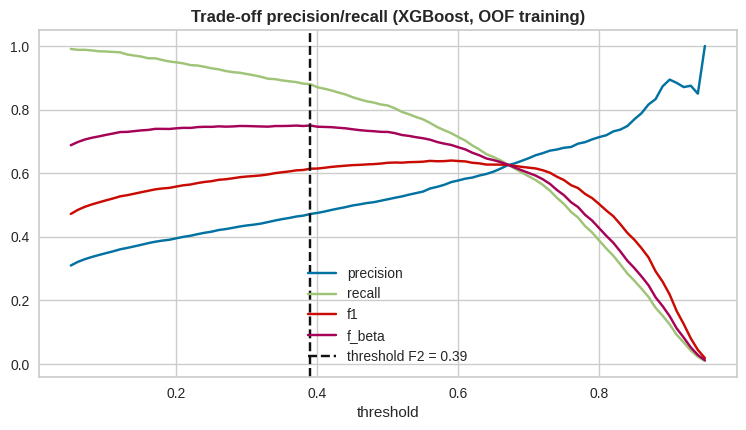

THRESHOLD (F2-optimal) = 0.39 -> OOF precision 0.472, recall 0.880 | threshold F1-optimal = 0.59


In [ ]:
BETA = 2.0
oof_tr = cross_val_predict(best_est, X_train, y_train, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
grid = np.arange(0.05, 0.96, 0.01)
res = pd.DataFrame({
    "threshold": grid,
    "precision": [precision_score(y_train, oof_tr >= t, zero_division=0) for t in grid],
    "recall": [recall_score(y_train, oof_tr >= t) for t in grid],
    "f1": [f1_score(y_train, oof_tr >= t) for t in grid],
    "f_beta": [fbeta_score(y_train, oof_tr >= t, beta=BETA) for t in grid]})
THRESHOLD = float(res.loc[res["f_beta"].idxmax(), "threshold"])
thr_f1 = float(res.loc[res["f1"].idxmax(), "threshold"])

plt.figure(figsize=(9, 4.5))
for c in ["precision", "recall", "f1", "f_beta"]:
    plt.plot(res["threshold"], res[c], label=c)
plt.axvline(THRESHOLD, color="k", ls="--", label=f"threshold F{BETA:.0f} = {THRESHOLD:.2f}")
plt.legend(); plt.title(f"Trade-off precision/recall ({best_name}, OOF training)"); plt.xlabel("threshold")
plt.savefig(os.path.join(PATHS["figures"], "08_threshold.png"), dpi=150, bbox_inches="tight")
plt.show()
r_ = res.loc[res["threshold"].round(2) == round(THRESHOLD, 2)].iloc[0]
print(f"THRESHOLD (F{BETA:.0f}-optimal) = {THRESHOLD:.2f} -> OOF precision {r_['precision']:.3f}, recall {r_['recall']:.3f} | threshold F1-optimal = {thr_f1:.2f}")

### Sel 46: Evaluasi pada test set (dipakai sekali untuk pelaporan)
Test set dipakai **sekali** untuk melaporkan performa. Isinya: metrik semua model pada threshold 0,5, model final pada dua threshold, kurva ROC dan Precision-Recall, confusion matrix, laporan klasifikasi, **bootstrap CI 95%** untuk ROC-AUC dan PR-AUC, dan kurva kalibrasi.

**Cara membaca confusion matrix:** TP = churner tertangkap, FN = churner terlewat, FP = non-churner yang ikut ditawari retensi, TN = non-churner yang benar.

Metrik test set pada threshold 0,5 (hanya pelaporan; pemilihan model berdasarkan CV):


,accuracy,precision,recall,f1,roc_auc,pr_auc
XGBoost,0.7438,0.5110,0.8075,0.6259,0.8475,0.6666
Gradient Boosting,0.8020,0.6678,0.5053,0.5753,0.8464,0.6600
Random Forest,0.7601,0.5323,0.7941,0.6373,0.8468,0.6539
LogReg (balanced),0.7388,0.5052,0.7834,0.6143,0.8417,0.6336
Decision Tree,0.7544,0.5253,0.7781,0.6272,0.8363,0.6329
LogReg (tanpa bobot),0.8070,0.6594,0.5642,0.6081,0.8419,0.6304
LogReg + SMOTE,0.7388,0.5051,0.7968,0.6183,0.8401,0.6280


Baseline PR-AUC (prevalensi churn di test) = 0.265

Model final (XGBoost) pada dua threshold:


,accuracy,precision,recall,f1,roc_auc,pr_auc
@0.5,0.7438,0.5110,0.8075,0.6259,0.8475,0.6666
@0.39 (F2),0.7055,0.4702,0.8663,0.6096,0.8475,0.6666


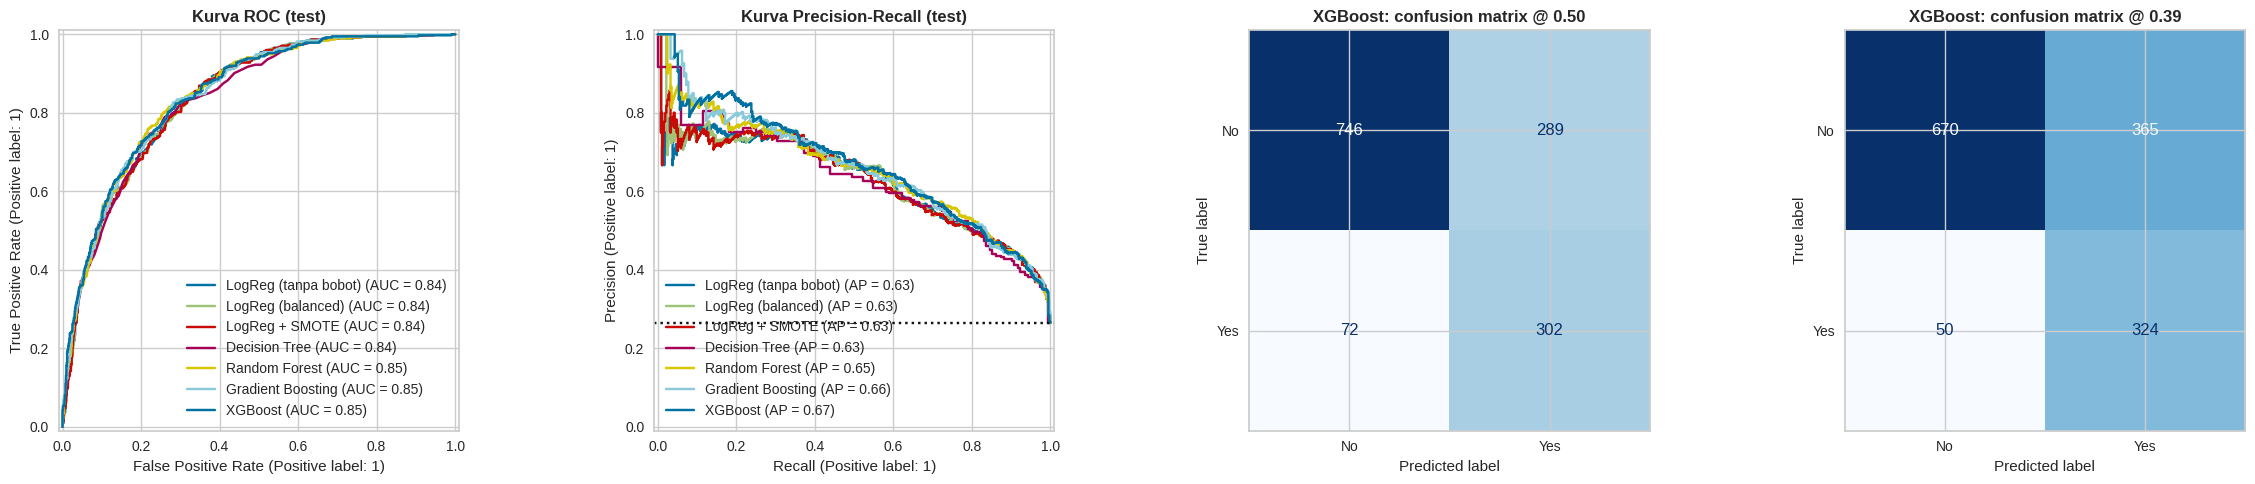


Laporan klasifikasi @ 0.39:
              precision    recall  f1-score   support

   Non-churn      0.931     0.647     0.764      1035
       Churn      0.470     0.866     0.610       374

    accuracy                          0.705      1409
   macro avg      0.700     0.757     0.687      1409
weighted avg      0.808     0.705     0.723      1409

TP=324 (churner tertangkap), FN=50 (churner terlewat), FP=365 (non-churner yang ikut ditawari retensi), TN=670
Trade-off: menangkap 86.6% churner, dengan 365 pelanggan non-churn menerima penawaran yang sebenarnya tidak perlu.

Bootstrap CI 95%: ROC-AUC 0.828-0.870 | PR-AUC 0.624-0.718


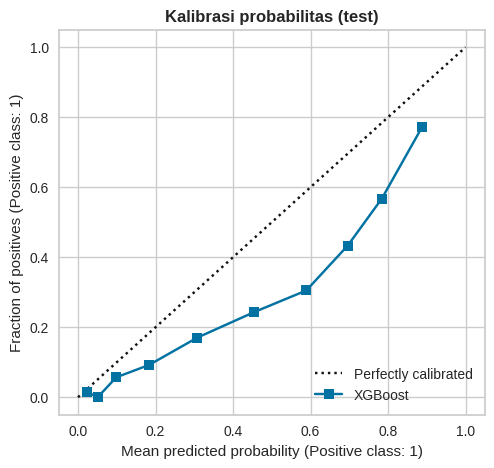

In [ ]:
def metrics_at(y_true, p, thr):
    yh = (p >= thr).astype(int)
    return {"accuracy": accuracy_score(y_true, yh), "precision": precision_score(y_true, yh, zero_division=0),
            "recall": recall_score(y_true, yh), "f1": f1_score(y_true, yh),
            "roc_auc": roc_auc_score(y_true, p), "pr_auc": average_precision_score(y_true, p)}

p_test = {n: s.best_estimator_.predict_proba(X_test)[:, 1] for n, s in searches.items()}
test_df = pd.DataFrame({n: metrics_at(y_test, p, 0.5) for n, p in p_test.items()}).T
print("Metrik test set pada threshold 0,5 (hanya pelaporan; pemilihan model berdasarkan CV):")
display(test_df.sort_values("pr_auc", ascending=False).round(4))
print(f"Baseline PR-AUC (prevalensi churn di test) = {y_test.mean():.3f}")

pb = p_test[best_name]
final_test = {"@0.5": metrics_at(y_test, pb, 0.5), f"@{THRESHOLD:.2f} (F{BETA:.0f})": metrics_at(y_test, pb, THRESHOLD)}
print(f"\nModel final ({best_name}) pada dua threshold:")
display(pd.DataFrame(final_test).T.round(4))

fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for n, p in p_test.items():
    RocCurveDisplay.from_predictions(y_test, p, name=n, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, p, name=n, ax=axes[1])
axes[0].set_title("Kurva ROC (test)"); axes[1].set_title("Kurva Precision-Recall (test)")
axes[1].axhline(y_test.mean(), color="k", ls=":")
for ax, thr in zip(axes[2:], [0.5, THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(y_test, (pb >= thr).astype(int), display_labels=["No", "Yes"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{best_name}: confusion matrix @ {thr:.2f}")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["figures"], "08_evaluasi_test.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"\nLaporan klasifikasi @ {THRESHOLD:.2f}:")
print(classification_report(y_test, (pb >= THRESHOLD).astype(int), target_names=["Non-churn", "Churn"], digits=3))
tn, fp, fn, tp = confusion_matrix(y_test, (pb >= THRESHOLD).astype(int)).ravel()
print(f"TP={tp} (churner tertangkap), FN={fn} (churner terlewat), FP={fp} (non-churner yang ikut ditawari retensi), TN={tn}")
print(f"Trade-off: menangkap {tp/(tp+fn)*100:.1f}% churner, dengan {fp} pelanggan non-churn menerima penawaran yang sebenarnya tidak perlu.")

# Bootstrap CI 95% untuk model final
bs = np.random.RandomState(RS); aucs, aps = [], []
yt = y_test.values
for _ in range(500):
    idx = bs.choice(len(yt), len(yt), replace=True)
    if yt[idx].min() == yt[idx].max(): continue
    aucs.append(roc_auc_score(yt[idx], pb[idx])); aps.append(average_precision_score(yt[idx], pb[idx]))
boot_ci = {"roc_auc": np.percentile(aucs, [2.5, 97.5]).tolist(), "pr_auc": np.percentile(aps, [2.5, 97.5]).tolist()}
print(f"\nBootstrap CI 95%: ROC-AUC {boot_ci['roc_auc'][0]:.3f}-{boot_ci['roc_auc'][1]:.3f} | PR-AUC {boot_ci['pr_auc'][0]:.3f}-{boot_ci['pr_auc'][1]:.3f}")

plt.figure(figsize=(5.5, 5))
CalibrationDisplay.from_predictions(y_test, pb, n_bins=10, strategy="quantile", name=best_name, ax=plt.gca())
plt.title("Kalibrasi probabilitas (test)")
plt.savefig(os.path.join(PATHS["figures"], "08_kalibrasi.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# =====================================================================================================
# SEL TAMBAHAN COLAB: ekspor prediksi test set untuk halaman Methodology (grafik ROC/PR interaktif)
# Jalankan SETELAH Sel 46 (evaluasi test set) pada sesi Colab yang sama. Tidak melatih ulang apa pun.
# Hasil: test_predictions.csv dan test_predictions_meta.json (keduanya terunduh otomatis).
# =====================================================================================================
import json
import os

import numpy as np
import pandas as pd
from google.colab import files
from sklearn.metrics import average_precision_score, roc_auc_score

needed = ["p_test", "y_test", "X_test", "df_feat", "best_name", "THRESHOLD", "BETA", "test_df", "PATHS", "RS"]
missing = [n for n in needed if n not in globals()]
if missing:
    raise NameError(f"Variabel belum ada: {missing}. Jalankan ulang notebook dari Sel 2 sampai Sel 46 (sesi mungkin telah di-reset).")

# Satu baris per pelanggan di test set; satu kolom probabilitas per model (dari p_test pada Sel 46)
out = pd.DataFrame({"customerID": df_feat.loc[X_test.index, "customerID"].values,
                    "y_true": y_test.values.astype(int)})
for name, p in p_test.items():
    out[name] = np.asarray(p, dtype=float)

# Verifikasi: AUC dari file harus sama dengan hasil Sel 46
for name in p_test:
    auc = roc_auc_score(out["y_true"], out[name])
    ap = average_precision_score(out["y_true"], out[name])
    assert abs(auc - test_df.loc[name, "roc_auc"]) < 1e-4, f"ROC-AUC {name} tidak cocok"
    assert abs(ap - test_df.loc[name, "pr_auc"]) < 1e-4, f"PR-AUC {name} tidak cocok"
print(f"Verifikasi lulus untuk {len(p_test)} model. Baris: {len(out)}, churn: {int(out['y_true'].sum())}")

csv_path = os.path.join(PATHS["metrics"], "test_predictions.csv")
meta_path = os.path.join(PATHS["metrics"], "test_predictions_meta.json")
out.to_csv(csv_path, index=False, float_format="%.10g")
meta = {"best_model": best_name, "threshold": float(THRESHOLD), "beta": float(BETA), "n_test": int(len(out)),
        "n_test_churn": int(out["y_true"].sum()), "test_size": 0.2, "random_state": int(RS), "models": list(p_test.keys())}
with open(meta_path, "w") as fh:
    json.dump(meta, fh, indent=2)

files.download(csv_path)
files.download(meta_path)
print("Selesai. Letakkan kedua file di folder reports/metrics/ pada proyek Streamlit.")

Verifikasi lulus untuk 7 model. Baris: 1409, churn: 374


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Selesai. Letakkan kedua file di folder reports/metrics/ pada proyek Streamlit.


---
# TAHAP 9: Model Interpretability

**Tujuan:** memahami fitur apa yang paling memengaruhi prediksi model.

**Tiga sudut pandang** dipakai agar kesimpulan tidak bergantung pada satu metode:
| Metode | Cara kerja |
|---|---|
| Native importance | Bawaan model (gain/impurity pada pohon, |koefisien| pada regresi) |
| Permutation importance | Seberapa turun PR-AUC test jika satu fitur diacak |
| SHAP | Kontribusi tiap fitur pada tiap prediksi (berbasis teori permainan) |

Fitur one-hot digabung kembali ke fitur asal agar mudah dibaca. Semua ukuran ini menggambarkan kontribusi pada **prediksi**, bukan sebab-akibat.

### Sel 47: Native dan permutation importance
`group_name` memetakan nama kolom hasil one-hot (misal `cat__Contract_Two year`) kembali ke fitur asal (`Contract`), lalu importance dijumlahkan per grup.

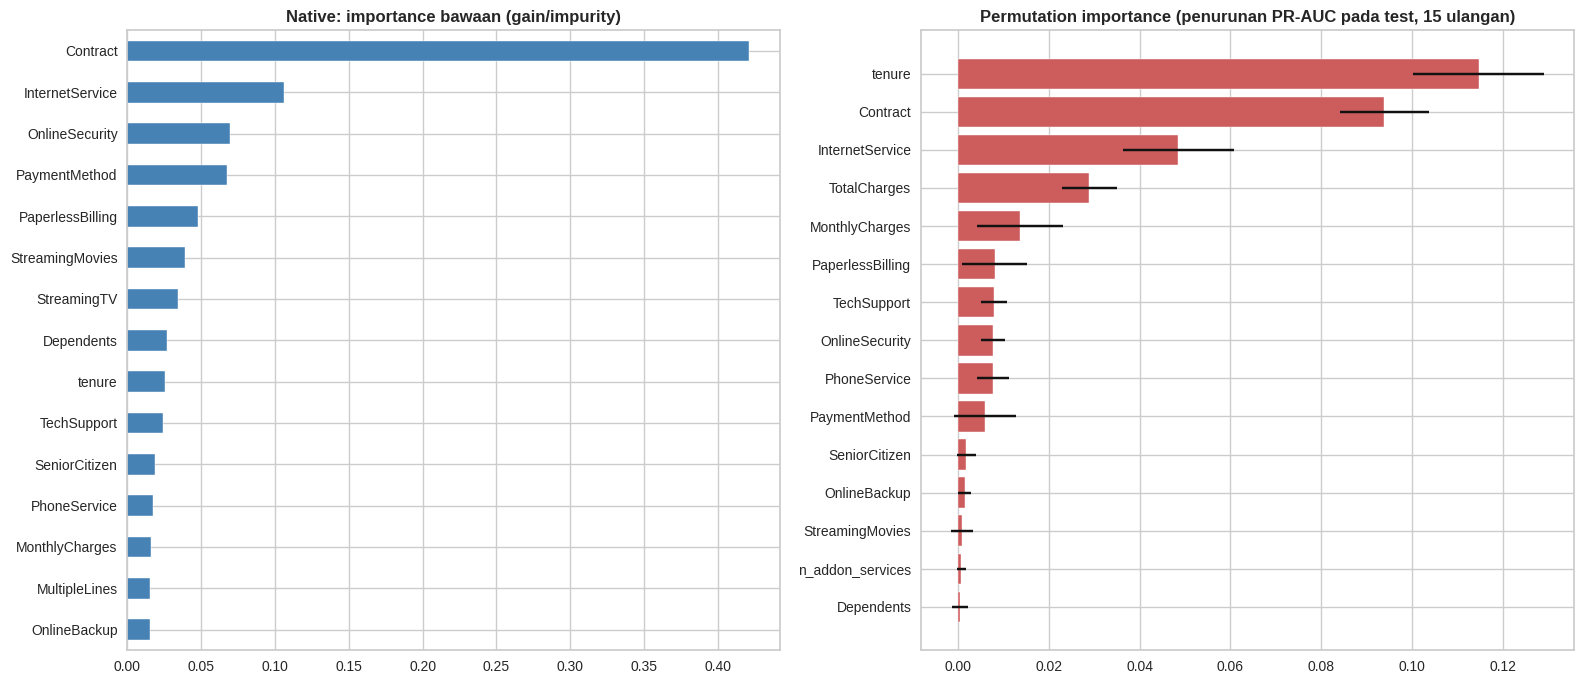

,fitur,perm_mean,perm_sd
0,tenure,0.1147,0.0144
18,Contract,0.0939,0.0098
11,InternetService,0.0485,0.0122
2,TotalCharges,0.0290,0.0061
1,MonthlyCharges,0.0137,0.0095
19,PaperlessBilling,0.0081,0.0071
15,TechSupport,0.0080,0.0029
12,OnlineSecurity,0.0078,0.0027
9,PhoneService,0.0077,0.0035
20,PaymentMethod,0.0060,0.0069


In [ ]:
from sklearn.inspection import permutation_importance

pre_fit = best_est.named_steps["pre"]
feat_names = pre_fit.get_feature_names_out()
def group_name(f):
    s = f.split("__", 1)[1]
    return max([c for c in cf.MODEL_FEATS if s == c or s.startswith(c + "_")], key=len)
groups = pd.Series([group_name(f) for f in feat_names], index=feat_names)

clf = best_est.named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    raw_imp, imp_label = clf.feature_importances_, "importance bawaan (gain/impurity)"
elif hasattr(clf, "coef_"):
    raw_imp, imp_label = np.abs(clf.coef_.ravel()), "|koefisien| (fitur terstandardisasi)"
else:
    raw_imp, imp_label = np.zeros(len(feat_names)), "tidak tersedia"
native_imp = pd.Series(raw_imp, index=feat_names).groupby(groups).sum().sort_values(ascending=False)

perm = permutation_importance(best_est, X_test, y_test, scoring="average_precision", n_repeats=15, random_state=RS, n_jobs=-1)
perm_df = pd.DataFrame({"fitur": X_test.columns, "perm_mean": perm.importances_mean, "perm_sd": perm.importances_std}).sort_values("perm_mean", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
native_imp.head(15)[::-1].plot.barh(ax=axes[0], color="steelblue"); axes[0].set_title(f"Native: {imp_label}")
top = perm_df.head(15)[::-1]
axes[1].barh(top["fitur"], top["perm_mean"], xerr=top["perm_sd"], color="indianred")
axes[1].set_title("Permutation importance (penurunan PR-AUC pada test, 15 ulangan)")
plt.tight_layout()
plt.savefig(os.path.join(PATHS["interpret"], "09_importance.png"), dpi=150, bbox_inches="tight")
plt.show()
display(perm_df.head(15).round(4))

if hasattr(clf, "coef_"):
    coef = pd.Series(clf.coef_.ravel(), index=feat_names).sort_values()
    print("\nKoefisien Logistic Regression (terstandardisasi/one-hot): 10 terendah dan 10 tertinggi")
    display(pd.concat([coef.head(10), coef.tail(10)]).round(3).to_frame("koefisien"))

native_imp.rename("native_importance").to_csv(os.path.join(PATHS["interpret"], "native_importance.csv"))
perm_df.to_csv(os.path.join(PATHS["interpret"], "permutation_importance.csv"), index=False)

### Sel 48: SHAP
SHAP memakai `TreeExplainer` untuk model pohon dan `LinearExplainer` untuk regresi logistik, pada 800 sampel test. **Beeswarm plot** menunjukkan arah pengaruh: titik merah (nilai fitur tinggi) di kanan berarti menaikkan risiko churn. Nilai SHAP dummy dijumlahkan ke fitur asal. Jika SHAP error, sel ini dilewati dan Sel 47 tetap cukup.

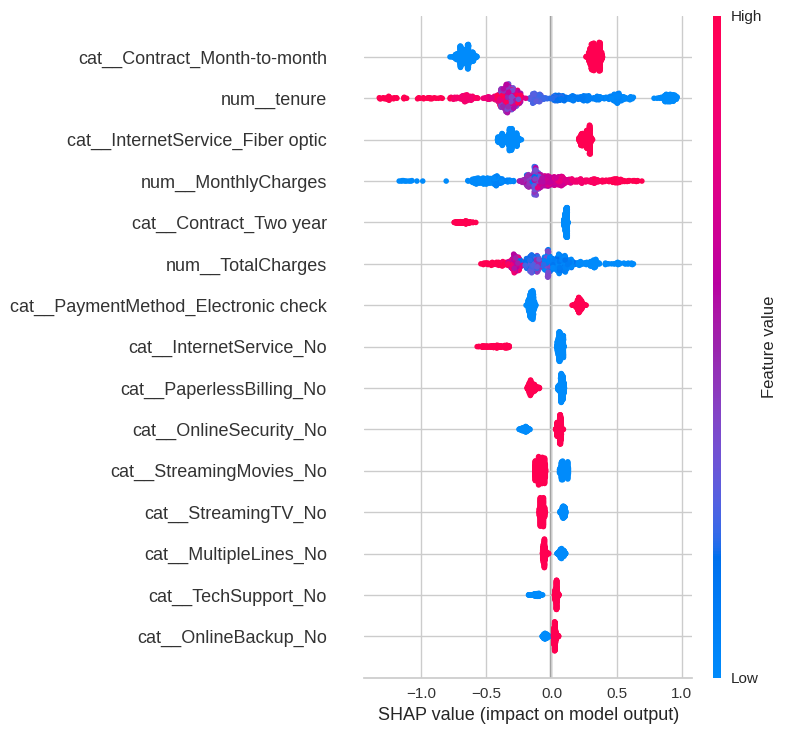

,mean_abs_shap,share_%
Contract,0.7076,22.9045
tenure,0.4403,14.2525
InternetService,0.4074,13.1881
MonthlyCharges,0.2562,8.2942
PaymentMethod,0.1920,6.2149
TotalCharges,0.1759,5.6934
PaperlessBilling,0.1395,4.5169
OnlineSecurity,0.1167,3.7768
StreamingMovies,0.1131,3.6596
StreamingTV,0.0982,3.1782



Korelasi peringkat (Spearman) antar-metode importance:


,native,permutation,shap
native,1.0000,0.5190,0.7580
permutation,0.5190,1.0000,0.7430
shap,0.7580,0.7430,1.0000


10 fitur teratas menurut rata-rata peringkat ketiga metode:


,native,permutation,shap,rata2
Contract,1.0000,2.0000,1.0000,1.3000
InternetService,2.0000,3.0000,3.0000,2.7000
tenure,9.0000,1.0000,2.0000,4.0000
PaperlessBilling,5.0000,6.0000,7.0000,6.0000
PaymentMethod,4.0000,10.0000,5.0000,6.3000
OnlineSecurity,3.0000,8.0000,8.0000,6.3000
MonthlyCharges,13.0000,5.0000,4.0000,7.3000
TotalCharges,16.0000,4.0000,6.0000,8.7000
StreamingMovies,6.0000,13.0000,9.0000,9.3000
TechSupport,10.0000,7.0000,12.0000,9.7000


In [ ]:
import shap
shap_imp = None
try:
    Xt_all = pre_fit.transform(X_test)
    Xt_all = Xt_all.toarray() if hasattr(Xt_all, "toarray") else np.asarray(Xt_all)
    Xt_all = Xt_all.astype(float)
    idx = np.random.RandomState(RS).choice(len(Xt_all), min(800, len(Xt_all)), replace=False)
    Xt = Xt_all[idx]

    if isinstance(clf, (RandomForestClassifier, GradientBoostingClassifier, XGBClassifier, DecisionTreeClassifier)):
        sv = shap.TreeExplainer(clf).shap_values(Xt)
    else:
        bg = pre_fit.transform(X_train.sample(200, random_state=RS))
        bg = (bg.toarray() if hasattr(bg, "toarray") else np.asarray(bg)).astype(float)
        sv = shap.LinearExplainer(clf, bg).shap_values(Xt)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[:, :, 1]

    plt.figure()
    shap.summary_plot(sv, Xt, feature_names=list(feat_names), max_display=15, show=False)
    plt.savefig(os.path.join(PATHS["interpret"], "09_shap_beeswarm.png"), dpi=150, bbox_inches="tight")
    plt.show()

    sv_g = pd.DataFrame(sv, columns=feat_names).T.groupby(groups).sum().T   # jumlahkan SHAP dummy ke fitur asal
    shap_imp = sv_g.abs().mean().sort_values(ascending=False).rename("mean_abs_shap").to_frame()
    shap_imp["share_%"] = shap_imp["mean_abs_shap"] / shap_imp["mean_abs_shap"].sum() * 100
    display(shap_imp.head(15).round(4))
    shap_imp.to_csv(os.path.join(PATHS["interpret"], "shap_importance.csv"))

    cmp = pd.DataFrame({"native": native_imp.rank(ascending=False), "permutation": perm_df.set_index("fitur")["perm_mean"].rank(ascending=False),
                        "shap": shap_imp["mean_abs_shap"].rank(ascending=False)})
    print("\nKorelasi peringkat (Spearman) antar-metode importance:")
    display(cmp.corr(method="spearman").round(3))
    print("10 fitur teratas menurut rata-rata peringkat ketiga metode:")
    display(cmp.assign(rata2=cmp.mean(axis=1)).sort_values("rata2").head(10).round(1))
except Exception as e:
    print(f"SHAP dilewati karena error: {type(e).__name__}: {e}")
    print("Interpretasi tetap bisa memakai native + permutation importance di Sel 47.")

---
# TAHAP 10: Customer Intelligence dan Business Recommendation

**Tujuan:** mengubah prediksi menjadi tindakan: siapa yang diprioritaskan dan intervensi apa.

**Langkah:**
1. **Skor out-of-fold** untuk semua pelanggan: setiap pelanggan diprediksi oleh model yang tidak pernah melihat dirinya, sehingga skor tidak bocor dan tier bisa divalidasi terhadap churn aktual.
2. **Model deployment** di-refit pada seluruh data.
3. **Kalibrasi isotonik** agar probabilitas lebih bisa dipakai sebagai angka (model berbobot kelas cenderung melebih-lebihkan probabilitas).
4. **Tier risiko** dari kuantil skor: top 20% = High, 20-50% = Medium, sisanya Low (asumsi analis, bisa diubah).
5. **Tier nilai**: kuartil teratas `annual_value_proxy` = High.
6. **Prioritas P1-P4** dari kombinasi tier risiko dan nilai:

| | Value High | Value Standard |
|---|---|---|
| **Risk High** | P1 Selamatkan segera | P2 Retensi terstruktur |
| **Risk Medium** | P2 Retensi terstruktur | P3 Pantau |
| **Risk Low** | P4 Pertahankan | P4 Pertahankan |

7. **Rekomendasi** dibangkitkan dari aturan berbasis profil segmen aktual, dengan angka bukti, dan diberi label **hipotesis yang perlu diuji A/B**.

### Sel 49: Skor risiko, kalibrasi, tier, prioritas
Parameter yang bisa Anda ubah: `RISK_Q_HIGH`, `RISK_Q_MED`, `VALUE_Q`. Tabel validasi harus menunjukkan churn aktual **naik** dari Low ke High; jika tidak, tier tidak bermakna. `revenue_at_risk` = probabilitas terkalibrasi x nilai tahunan proksi, dipakai sebagai **indeks relatif**, bukan prakiraan uang.

Kualitas skor OOF seluruh pelanggan: ROC-AUC = 0.849, PR-AUC = 0.664
Cutoff risiko: Medium >= 0.385, High >= 0.743 | cutoff nilai tahunan High >= 1,078.2

Validasi: churn rate aktual per tier risiko (harus naik dari Low ke High):


,n,churn_rate_aktual
risk_tier,,
Low,3521,6.1900
Medium,2113,33.5100
High,1409,66.9300


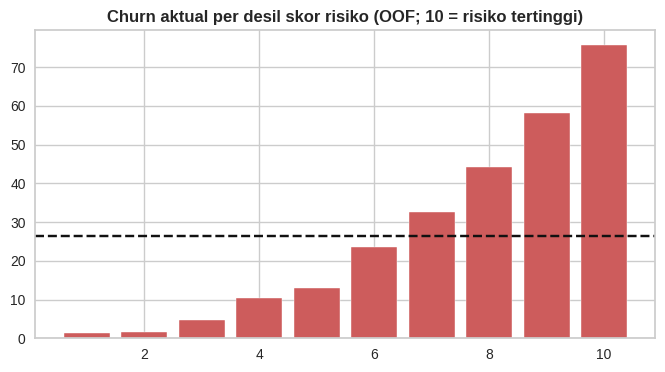

,n,churn_rate_aktual,mean_prob_cal,tenure_median,monthly_mean,annual_value_total,revenue_at_risk,share_%,share_revenue_at_risk_%
priority,,,,,,,,,
P1 - Selamatkan segera,434,67.0500,0.6700,13.0000,97.9000,"509,883.0000","340,451.7800",6.1600,20.4100
P2 - Retensi terstruktur,1673,53.0800,0.5400,10.0000,82.7200,"1,660,783.8000","842,909.3800",23.7500,50.5400
P3 - Pantau,1415,33.3600,0.3300,12.0000,56.5100,"959,520.0000","321,296.1800",20.0900,19.2600
P4 - Pertahankan,3521,6.1900,0.0600,49.0000,55.4600,"2,343,212.4000","163,140.7100",49.9900,9.7800


Catatan: revenue_at_risk = probabilitas terkalibrasi x nilai tahunan proksi; pakai sebagai indeks relatif prioritisasi, bukan prakiraan rupiah.


In [ ]:
from sklearn.base import clone
from sklearn.isotonic import IsotonicRegression

RISK_Q_HIGH, RISK_Q_MED, VALUE_Q = 0.80, 0.50, 0.75   # asumsi analis, dapat diubah

cv_full = StratifiedKFold(5, shuffle=True, random_state=RS + 1)
oof_full = cross_val_predict(clone(best_est), X, y, cv=cv_full, method="predict_proba", n_jobs=-1)[:, 1]
print(f"Kualitas skor OOF seluruh pelanggan: ROC-AUC = {roc_auc_score(y, oof_full):.3f}, PR-AUC = {average_precision_score(y, oof_full):.3f}")

calibrator = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof_full, y)
final_churn_pipe = clone(best_est).fit(X, y)       # model untuk deployment (seluruh data)

risk_cut_high = float(np.quantile(oof_full, RISK_Q_HIGH)); risk_cut_med = float(np.quantile(oof_full, RISK_Q_MED))
value_cut = float(df_feat["annual_value_proxy"].quantile(VALUE_Q))

df_feat["churn_prob_raw"] = oof_full
df_feat["churn_prob_cal"] = calibrator.predict(oof_full)
df_feat["risk_tier"] = cf.assign_risk_tier(oof_full, risk_cut_med, risk_cut_high)
df_feat["value_tier"] = cf.assign_value_tier(df_feat["annual_value_proxy"], value_cut)
df_feat["priority"] = cf.assign_priority(df_feat["risk_tier"], df_feat["value_tier"])
df_feat["revenue_at_risk"] = df_feat["churn_prob_cal"] * df_feat["annual_value_proxy"]
print(f"Cutoff risiko: Medium >= {risk_cut_med:.3f}, High >= {risk_cut_high:.3f} | cutoff nilai tahunan High >= {value_cut:,.1f}")

# Validasi tier terhadap churn aktual
val = df_feat.groupby("risk_tier")["Churn_flag"].agg(n="size", churn_rate_aktual="mean").reindex(["Low", "Medium", "High"])
val["churn_rate_aktual"] *= 100
print("\nValidasi: churn rate aktual per tier risiko (harus naik dari Low ke High):")
display(val.round(2))
dec = pd.qcut(oof_full, 10, labels=False, duplicates="drop") + 1
lift = df_feat.groupby(dec)["Churn_flag"].mean() * 100
plt.figure(figsize=(8, 4)); plt.bar(lift.index, lift.values, color="indianred"); plt.axhline(OVERALL_CHURN * 100, color="k", ls="--")
plt.title("Churn aktual per desil skor risiko (OOF; 10 = risiko tertinggi)")
plt.savefig(os.path.join(PATHS["business"], "10_lift_desil.png"), dpi=150, bbox_inches="tight")
plt.show()

prio_df = df_feat.groupby("priority").agg(n=("customerID", "size"), churn_rate_aktual=("Churn_flag", "mean"),
          mean_prob_cal=("churn_prob_cal", "mean"), tenure_median=("tenure", "median"), monthly_mean=("MonthlyCharges", "mean"),
          annual_value_total=("annual_value_proxy", "sum"), revenue_at_risk=("revenue_at_risk", "sum"))
prio_df["share_%"] = prio_df["n"] / len(df_feat) * 100
prio_df["share_revenue_at_risk_%"] = prio_df["revenue_at_risk"] / prio_df["revenue_at_risk"].sum() * 100
prio_df["churn_rate_aktual"] *= 100
display(prio_df.round(2))
print("Catatan: revenue_at_risk = probabilitas terkalibrasi x nilai tahunan proksi; pakai sebagai indeks relatif prioritisasi, bukan prakiraan rupiah.")

### Sel 50: Segmen x prioritas
Heatmap menunjukkan komposisi prioritas di tiap segmen, dan tabel `seg_sum` meringkas churn aktual, probabilitas rata-rata, persentase P1, dan kontribusi `revenue_at_risk` per segmen.

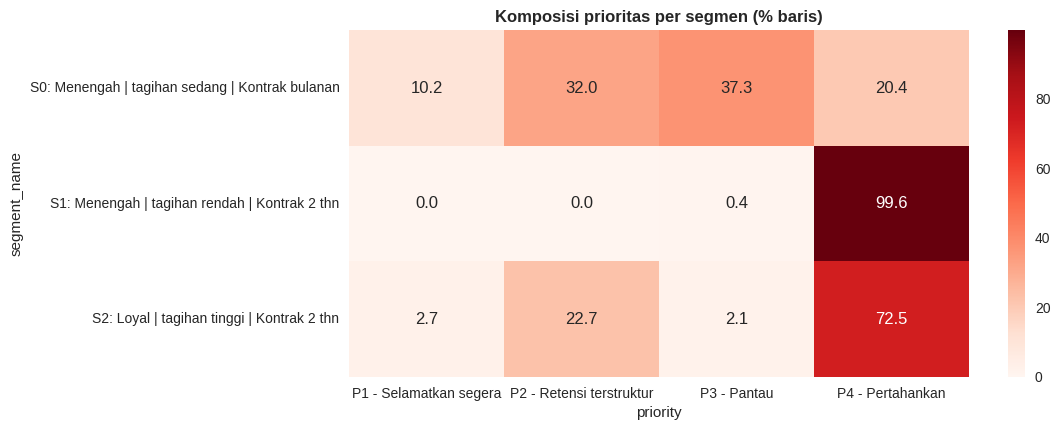

,segment_name,n,churn_aktual,prob_cal_mean,tenure_mean,monthly_mean,value_total,rev_at_risk,pct_P1,share_rev_at_risk_%
segment_id,,,,,,,,,,
0,S0: Menengah | tagihan sedang | Kontrak bulanan,3651,42.3700,42.0500,14.6500,63.0300,"2,761,627.2000","1,302,267.8500",10.2400,78.0800
1,S1: Menengah | tagihan rendah | Kontrak 2 thn,1165,1.9700,2.4100,42.0300,24.5000,"342,528.6000","9,514.2300",0.0000,0.5700
2,S2: Loyal | tagihan tinggi | Kontrak 2 thn,2227,13.4300,13.7200,56.3600,88.6600,"2,369,243.4000","356,015.9800",2.6900,21.3500


In [ ]:
seg_prio = pd.crosstab(df_feat["segment_name"], df_feat["priority"], normalize="index") * 100
plt.figure(figsize=(10, 4.5)); sns.heatmap(seg_prio, annot=True, fmt=".1f", cmap="Reds")
plt.title("Komposisi prioritas per segmen (% baris)")
plt.savefig(os.path.join(PATHS["business"], "10_segmen_prioritas.png"), dpi=150, bbox_inches="tight")
plt.show()

seg_sum = df_feat.groupby("segment_id").agg(segment_name=("segment_name", "first"), n=("customerID", "size"),
          churn_aktual=("Churn_flag", "mean"), prob_cal_mean=("churn_prob_cal", "mean"),
          tenure_mean=("tenure", "mean"), monthly_mean=("MonthlyCharges", "mean"),
          value_total=("annual_value_proxy", "sum"), rev_at_risk=("revenue_at_risk", "sum"))
seg_sum["pct_P1"] = df_feat.assign(p1=df_feat["priority"].str.startswith("P1")).groupby("segment_id")["p1"].mean() * 100
seg_sum["share_rev_at_risk_%"] = seg_sum["rev_at_risk"] / seg_sum["rev_at_risk"].sum() * 100
seg_sum["churn_aktual"] *= 100; seg_sum["prob_cal_mean"] *= 100
display(seg_sum.round(2))

### Sel 51: Rekomendasi retensi berbasis aturan dan bukti
Untuk tiap segmen, kode membandingkan profilnya dengan rata-rata keseluruhan, lalu menambahkan tindakan jika ada penyimpangan kuat. Contoh aturan: jika kontrak bulanan di segmen > rata-rata + 10 poin, rekomendasi insentif migrasi kontrak. Setiap rekomendasi disertai **angka bukti** dari data. Daftar pelanggan P1 (200 teratas menurut `revenue_at_risk`) diekspor ke CSV untuk tim retensi.

Aturan ini berdasarkan asosiasi, jadi hasilnya hipotesis yang perlu diuji A/B sebelum diterapkan penuh.

In [ ]:
ov = {"m2m": df_feat["contract_risk"].mean() * 100, "echeck": (df_feat["PaymentMethod"] == "Electronic check").mean() * 100,
      "addon": df_feat["n_addon_services"].mean(), "churn": OVERALL_CHURN * 100}
inet_m = df_feat["InternetService"] != "No"
r_no = df_feat.loc[inet_m & (df_feat["n_addon_services"] == 0), "Churn_flag"].mean() * 100
r_hi = df_feat.loc[inet_m & (df_feat["n_addon_services"] >= 3), "Churn_flag"].mean() * 100
addon_assoc = r_hi < r_no
print(f"Bukti global: churn pelanggan internet tanpa add-on {r_no:.1f}% vs >=3 add-on {r_hi:.1f}% -> add-on berasosiasi dengan churn lebih rendah? {addon_assoc}")

rec_rows = []
for i, s in prof.iterrows():
    acts, ev = [], []
    ratio = s["churn_rate_%"] / ov["churn"]
    level = "TINGGI" if ratio > 1.15 else ("RENDAH" if ratio < 0.85 else "SEDANG")
    ev.append(f"churn {s['churn_rate_%']:.1f}% vs {ov['churn']:.1f}% rata-rata")
    if s["pct_month_to_month"] > ov["m2m"] + 10:
        acts.append("Insentif migrasi ke kontrak 1-2 tahun (diskon/benefit di awal)")
        ev.append(f"{s['pct_month_to_month']:.0f}% kontrak bulanan vs {ov['m2m']:.0f}%")
    if s["pct_echeck"] > ov["echeck"] + 10:
        acts.append("Dorong pembayaran otomatis (transfer bank/kartu kredit) dengan insentif kecil")
        ev.append(f"{s['pct_echeck']:.0f}% electronic check vs {ov['echeck']:.0f}%")
    if addon_assoc and s["pct_no_internet"] < 50 and s["n_addon_mean"] < ov["addon"] - 0.5:
        acts.append("Uji coba bundling add-on (keamanan/dukungan teknis) gratis atau berdiskon")
        ev.append(f"rata-rata add-on {s['n_addon_mean']:.1f} vs {ov['addon']:.1f}")
    if s["tenure_mean"] < t33:
        acts.append("Program onboarding dan check-in aktif pada 0-12 bulan pertama")
        ev.append(f"tenure rata-rata {s['tenure_mean']:.0f} bln (tercile bawah < {t33:.0f})")
    if s["monthly_mean"] > m67 and ratio > 1.0:
        acts.append("Tinjau value-for-money paket (penyesuaian paket atau penawaran loyalitas harga)")
        ev.append(f"tagihan rata-rata {s['monthly_mean']:.0f} (tercile atas > {m67:.0f})")
    if level == "RENDAH" and s["tenure_mean"] > t67:
        acts.append("Pertahankan: program loyalitas, upsell layanan tambahan secara selektif")
        ev.append(f"tenure rata-rata {s['tenure_mean']:.0f} bln")
    if not acts:
        acts.append("Pantau; tidak ada penyimpangan profil yang kuat dari rata-rata")
    rec_rows.append({"segment_id": int(i), "segment_name": seg_names[int(i)], "n": int(s["n"]), "share_%": s["share_%"],
                     "churn_aktual_%": s["churn_rate_%"], "tingkat_risiko_segmen": level,
                     "pct_P1": seg_sum.loc[i, "pct_P1"], "share_revenue_at_risk_%": seg_sum.loc[i, "share_rev_at_risk_%"],
                     "rekomendasi": " | ".join(acts), "bukti_data": "; ".join(ev),
                     "catatan": "Hipotesis berbasis asosiasi; uji dengan A/B test sebelum skala penuh"})
reco_df = pd.DataFrame(rec_rows)
pd.set_option("display.max_colwidth", 200)
display(reco_df.round(2))

p1_list = df_feat[df_feat["priority"].str.startswith("P1")].sort_values("revenue_at_risk", ascending=False)
p1_list[["customerID", "segment_name", "tenure", "MonthlyCharges", "Contract", "PaymentMethod", "InternetService",
         "n_addon_services", "churn_prob_cal", "revenue_at_risk"]].head(200).to_csv(os.path.join(PATHS["business"], "p1_customer_list.csv"), index=False)
reco_df.to_csv(os.path.join(PATHS["business"], "business_recommendations.csv"), index=False)
prio_df.to_csv(os.path.join(PATHS["business"], "priority_summary.csv"))
seg_sum.to_csv(os.path.join(PATHS["business"], "segment_intelligence_summary.csv"))
print(f"\nDaftar P1 tersimpan: {len(p1_list)} pelanggan (200 teratas menurut revenue_at_risk diekspor).")

Bukti global: churn pelanggan internet tanpa add-on 52.2% vs >=3 add-on 20.6% -> add-on berasosiasi dengan churn lebih rendah? True


,segment_id,segment_name,n,share_%,churn_aktual_%,tingkat_risiko_segmen,pct_P1,share_revenue_at_risk_%,rekomendasi,bukti_data,catatan
0,0,S0: Menengah | tagihan sedang | Kontrak bulanan,3651,51.8400,42.3700,TINGGI,10.2400,78.0800,Insentif migrasi ke kontrak 1-2 tahun (diskon/benefit di awal) | Dorong pembayaran otomatis (transfer bank/kartu kredit) dengan insentif kecil | Uji coba bundling add-on (keamanan/dukungan teknis)...,churn 42.4% vs 26.5% rata-rata; 95% kontrak bulanan vs 55%; 46% electronic check vs 34%; rata-rata add-on 1.3 vs 2.0,Hipotesis berbasis asosiasi; uji dengan A/B test sebelum skala penuh
1,1,S1: Menengah | tagihan rendah | Kontrak 2 thn,1165,16.5400,1.9700,RENDAH,0.0000,0.5700,Pantau; tidak ada penyimpangan profil yang kuat dari rata-rata,churn 2.0% vs 26.5% rata-rata,Hipotesis berbasis asosiasi; uji dengan A/B test sebelum skala penuh
2,2,S2: Loyal | tagihan tinggi | Kontrak 2 thn,2227,31.6200,13.4300,RENDAH,2.6900,21.3500,"Pertahankan: program loyalitas, upsell layanan tambahan secara selektif",churn 13.4% vs 26.5% rata-rata; tenure rata-rata 56 bln,Hipotesis berbasis asosiasi; uji dengan A/B test sebelum skala penuh



Daftar P1 tersimpan: 434 pelanggan (200 teratas menurut revenue_at_risk diekspor).


---
# TAHAP 11: Final Findings dan Analytical Report

Sel berikut menyusun laporan Markdown otomatis **dari angka hasil eksekusi** (tidak ada angka yang diketik manual). Bagian keterbatasan dan pengembangan lanjutan bersifat umum untuk dataset ini. Anda dapat menambahkan narasi interpretasi sendiri setelah melihat hasilnya.

### Sel 52: Laporan akhir
Laporan dibangun dengan f-string yang mengambil nilai dari variabel sebelumnya (`chi_df`, `mw_df`, `prof`, `cv_df`, `final_test`, dst), ditampilkan di notebook, dan disimpan ke `final_findings.md`.

In [ ]:
from IPython.display import Markdown
top_chi = chi_df.head(5)
top_perm = perm_df.head(5)["fitur"].tolist()
shap_top = shap_imp.head(5).index.tolist() if shap_imp is not None else ["(SHAP tidak tersedia)"]
tm = final_test[f"@{THRESHOLD:.2f} (F{BETA:.0f})"]; t05 = final_test["@0.5"]
all_gap_top = auto_gap(all_cat).head(5)["variabel"].tolist()
seg_lines = "\n".join([f"- **{seg_names[i]}** (n={int(r['n']):,}, {r['share_%']:.1f}%): tenure rata-rata {r['tenure_mean']:.1f} bln, "
                       f"tagihan {r['monthly_mean']:.1f}, kontrak bulanan {r['pct_month_to_month']:.0f}%, churn {r['churn_rate_%']:.1f}% "
                       f"(CI95 {r['churn_ci_low_%']:.1f}-{r['churn_ci_high_%']:.1f})" for i, r in prof.iterrows()])
reco_lines = "\n".join([f"- **{r['segment_name']}** [risiko {r['tingkat_risiko_segmen']}]: {r['rekomendasi']} _(bukti: {r['bukti_data']})_" for _, r in reco_df.iterrows()])

report = f"""# Telco Customer Intelligence: Ringkasan Temuan (dibangkitkan otomatis dari hasil eksekusi)

## 1. Temuan utama EDA
- {len(df_feat):,} pelanggan; churn rate keseluruhan **{OVERALL_CHURN*100:.2f}%** (rasio kelas {(1-OVERALL_CHURN)/OVERALL_CHURN:.2f}:1).
- Kualitas data: 11 nilai TotalCharges kosong (semua tenure = 0, diisi 0); tidak ada duplikasi penuh, outlier IQR 0, tidak ada pelanggaran logika bisnis.
- Variabel dengan gap churn terbesar antar-kategori: {', '.join(all_gap_top) if all_gap_top else '-'}.

## 2. Temuan statistik
- {int(chi_df['signifikan_holm'].sum())} dari {len(chi_df)} variabel kategorikal berasosiasi signifikan dengan churn setelah koreksi Holm (alpha 0,05).
- Asosiasi terkuat (Cramér's V): {', '.join([f"{r['variabel']} ({r['cramers_v']:.3f})" for _, r in top_chi.iterrows()])}.
- Numerik (Mann-Whitney): rank-biserial r tenure = {mw_df.set_index('variabel').loc['tenure','rank_biserial_r']:.3f}, MonthlyCharges = {mw_df.set_index('variabel').loc['MonthlyCharges','rank_biserial_r']:.3f}, TotalCharges = {mw_df.set_index('variabel').loc['TotalCharges','rank_biserial_r']:.3f}.
- Semua temuan adalah **asosiasi, bukan kausalitas**.

## 3-4. Segmentasi pelanggan
- Metode final: **{FINAL_METHOD.upper()}**, k = **{K_FINAL}** (Silhouette K-Means = {km_df.loc[K_FINAL,'silhouette']:.3f}; stabilitas ARI K-Means = {stab_km[0]:.3f}).
- Hubungan segmen-churn (pasca-hoc): Cramér's V = {v_s:.3f} (p = {p_s:.2e}).
{seg_lines}

## 5. Churn analysis
- Risiko relatif tertinggi: {', '.join([f"{r['karakteristik']} (RR {r['risiko_relatif']:.2f})" for _, r in risk_df.head(3).iterrows()])}.

## 6. Model prediksi terbaik
- Model terpilih (CV PR-AUC tertinggi): **{best_name}** (CV PR-AUC {cv_df.loc[best_name,'cv_pr_auc']:.3f}, CV ROC-AUC {cv_df.loc[best_name,'cv_roc_auc']:.3f}).
- Test set @0,5: recall {t05['recall']:.3f}, precision {t05['precision']:.3f}, F1 {t05['f1']:.3f}, ROC-AUC {t05['roc_auc']:.3f}, PR-AUC {t05['pr_auc']:.3f}.
- Test set @threshold {THRESHOLD:.2f} (F{BETA:.0f}): recall {tm['recall']:.3f}, precision {tm['precision']:.3f}, F1 {tm['f1']:.3f}.
- Bootstrap CI95 ROC-AUC {boot_ci['roc_auc'][0]:.3f}-{boot_ci['roc_auc'][1]:.3f}; PR-AUC {boot_ci['pr_auc'][0]:.3f}-{boot_ci['pr_auc'][1]:.3f}.

## 7. Faktor penting dalam prediksi
- Permutation importance teratas: {', '.join(top_perm)}.
- SHAP teratas: {', '.join(shap_top)}.
- Importance menunjukkan kontribusi pada prediksi model, **bukan** hubungan sebab-akibat.

## 8. Strategi retensi (hipotesis untuk diuji A/B)
{reco_lines}

## 9. Keterbatasan dataset
- Data satu snapshot tanpa tanggal: tidak ada urutan waktu, musiman, atau definisi jelas kapan churn terjadi; analisis survival mengandalkan asumsi sensor.
- Tidak ada data biaya, margin, riwayat keluhan, kualitas jaringan, atau penawaran kompetitor; `annual_value_proxy` hanya proksi pendapatan, bukan CLV.
- Satu operator dan satu wilayah yang tidak dijelaskan; generalisasi terbatas.
- MonthlyCharges adalah tagihan saat ini, sedangkan TotalCharges adalah akumulasi historis (redundan dengan tenure x MonthlyCharges).
- Probabilitas model berbobot kelas perlu kalibrasi; kalibrasi isotonik dilakukan pada skor OOF dan tetap perlu dipantau.
- Efek intervensi retensi tidak dapat diukur dari data observasional.

## 10. Pengembangan selanjutnya
- Uji A/B atau uplift modeling untuk mengukur efek nyata tiap tawaran retensi.
- Data longitudinal (tagihan bulanan, tiket layanan, penggunaan) dan model survival/hazard.
- Model biaya eksplisit (biaya penawaran vs nilai pelanggan) untuk memilih threshold optimal.
- Pemantauan drift dan retraining berkala; evaluasi keadilan antar kelompok demografi.
"""
display(Markdown(report))
with open(os.path.join(PATHS["business"], "final_findings.md"), "w", encoding="utf-8") as fh:
    fh.write(report)

# Telco Customer Intelligence: Ringkasan Temuan (dibangkitkan otomatis dari hasil eksekusi)

## 1. Temuan utama EDA
- 7,043 pelanggan; churn rate keseluruhan **26.54%** (rasio kelas 2.77:1).
- Kualitas data: 11 nilai TotalCharges kosong (semua tenure = 0, diisi 0); tidak ada duplikasi penuh, outlier IQR 0, tidak ada pelanggaran logika bisnis.
- Variabel dengan gap churn terbesar antar-kategori: Contract, tenure_group, InternetService, OnlineSecurity, TechSupport.

## 2. Temuan statistik
- 15 dari 17 variabel kategorikal berasosiasi signifikan dengan churn setelah koreksi Holm (alpha 0,05).
- Asosiasi terkuat (Cramér's V): Contract (0.410), tenure_group (0.348), OnlineSecurity (0.347), TechSupport (0.343), InternetService (0.322).
- Numerik (Mann-Whitney): rank-biserial r tenure = -0.480, MonthlyCharges = 0.242, TotalCharges = -0.301.
- Semua temuan adalah **asosiasi, bukan kausalitas**.

## 3-4. Segmentasi pelanggan
- Metode final: **KMEANS**, k = **3** (Silhouette K-Means = 0.403; stabilitas ARI K-Means = 0.987).
- Hubungan segmen-churn (pasca-hoc): Cramér's V = 0.381 (p = 1.25e-223).
- **S0: Menengah | tagihan sedang | Kontrak bulanan** (n=3,651, 51.8%): tenure rata-rata 14.7 bln, tagihan 63.0, kontrak bulanan 95%, churn 42.4% (CI95 40.8-44.0)
- **S1: Menengah | tagihan rendah | Kontrak 2 thn** (n=1,165, 16.5%): tenure rata-rata 42.0 bln, tagihan 24.5, kontrak bulanan 1%, churn 2.0% (CI95 1.3-2.9)
- **S2: Loyal | tagihan tinggi | Kontrak 2 thn** (n=2,227, 31.6%): tenure rata-rata 56.4 bln, tagihan 88.7, kontrak bulanan 18%, churn 13.4% (CI95 12.1-14.9)

## 5. Churn analysis
- Risiko relatif tertinggi: Kontrak bulanan (RR 6.32), Tanpa OnlineSecurity (pelanggan internet) (RR 3.63), Tanpa TechSupport (pelanggan internet) (RR 3.51).

## 6. Model prediksi terbaik
- Model terpilih (CV PR-AUC tertinggi): **XGBoost** (CV PR-AUC 0.668, CV ROC-AUC 0.849).
- Test set @0,5: recall 0.807, precision 0.511, F1 0.626, ROC-AUC 0.847, PR-AUC 0.667.
- Test set @threshold 0.39 (F2): recall 0.866, precision 0.470, F1 0.610.
- Bootstrap CI95 ROC-AUC 0.828-0.870; PR-AUC 0.624-0.718.

## 7. Faktor penting dalam prediksi
- Permutation importance teratas: tenure, Contract, InternetService, TotalCharges, MonthlyCharges.
- SHAP teratas: Contract, tenure, InternetService, MonthlyCharges, PaymentMethod.
- Importance menunjukkan kontribusi pada prediksi model, **bukan** hubungan sebab-akibat.

## 8. Strategi retensi (hipotesis untuk diuji A/B)
- **S0: Menengah | tagihan sedang | Kontrak bulanan** [risiko TINGGI]: Insentif migrasi ke kontrak 1-2 tahun (diskon/benefit di awal) | Dorong pembayaran otomatis (transfer bank/kartu kredit) dengan insentif kecil | Uji coba bundling add-on (keamanan/dukungan teknis) gratis atau berdiskon _(bukti: churn 42.4% vs 26.5% rata-rata; 95% kontrak bulanan vs 55%; 46% electronic check vs 34%; rata-rata add-on 1.3 vs 2.0)_
- **S1: Menengah | tagihan rendah | Kontrak 2 thn** [risiko RENDAH]: Pantau; tidak ada penyimpangan profil yang kuat dari rata-rata _(bukti: churn 2.0% vs 26.5% rata-rata)_
- **S2: Loyal | tagihan tinggi | Kontrak 2 thn** [risiko RENDAH]: Pertahankan: program loyalitas, upsell layanan tambahan secara selektif _(bukti: churn 13.4% vs 26.5% rata-rata; tenure rata-rata 56 bln)_

## 9. Keterbatasan dataset
- Data satu snapshot tanpa tanggal: tidak ada urutan waktu, musiman, atau definisi jelas kapan churn terjadi; analisis survival mengandalkan asumsi sensor.
- Tidak ada data biaya, margin, riwayat keluhan, kualitas jaringan, atau penawaran kompetitor; `annual_value_proxy` hanya proksi pendapatan, bukan CLV.
- Satu operator dan satu wilayah yang tidak dijelaskan; generalisasi terbatas.
- MonthlyCharges adalah tagihan saat ini, sedangkan TotalCharges adalah akumulasi historis (redundan dengan tenure x MonthlyCharges).
- Probabilitas model berbobot kelas perlu kalibrasi; kalibrasi isotonik dilakukan pada skor OOF dan tetap perlu dipantau.
- Efek intervensi retensi tidak dapat diukur dari data observasional.

## 10. Pengembangan selanjutnya
- Uji A/B atau uplift modeling untuk mengukur efek nyata tiap tawaran retensi.
- Data longitudinal (tagihan bulanan, tiket layanan, penggunaan) dan model survival/hazard.
- Model biaya eksplisit (biaya penawaran vs nilai pelanggan) untuk memilih threshold optimal.
- Pemantauan drift dan retraining berkala; evaluasi keadilan antar kelompok demografi.


---
# TAHAP 12: Export Artefak dan Verifikasi

**Tujuan:** menyimpan semua artefak untuk aplikasi Streamlit, lalu membuktikan bahwa model tersimpan benar-benar bisa memprediksi pelanggan baru dari **data mentah** tanpa training ulang.

**Artefak penting:**
| File | Fungsi |
|---|---|
| `models/customer_intelligence_bundle.joblib` | Paket berisi model segmentasi, model churn, kalibrator, cutoff, threshold |
| `models/customer_features.py` | Modul fitur dan skoring yang dipakai Streamlit |
| `metadata/feature_schema.json` | Skema input (kolom, nilai yang diizinkan, rentang) untuk validasi form |
| `reports/...` | Metrik, gambar, profil segmen, rekomendasi bisnis |

### Sel 53: Simpan artefak
Menyimpan dataset (tiga versi), semua model (`joblib`), metrik (CSV dan JSON), dan skema fitur. Di akhir, daftar semua file beserta ukurannya dicetak.

In [ ]:
import joblib

# --- Dataset ---
df_feat.drop(columns=["Churn_flag", "segment_id", "segment_name", "churn_prob_raw", "churn_prob_cal", "risk_tier",
                      "value_tier", "priority", "revenue_at_risk"]).to_csv(os.path.join(PATHS["data_clean"], "telco_clean_features.csv"), index=False)
df_feat.drop(columns=["churn_prob_raw", "churn_prob_cal", "risk_tier", "value_tier", "priority", "revenue_at_risk"]).to_csv(
    os.path.join(PATHS["data_clean"], "telco_segmented.csv"), index=False)
df_feat.to_csv(os.path.join(PATHS["data_clean"], "telco_customer_intelligence.csv"), index=False)

# --- Model ---
joblib.dump(segment_pipe, os.path.join(PATHS["models"], "segment_pipeline.joblib"))
joblib.dump(final_churn_pipe, os.path.join(PATHS["models"], "churn_pipeline.joblib"))
joblib.dump(calibrator, os.path.join(PATHS["models"], "churn_calibrator.joblib"))
bundle = {"segment_pipe": segment_pipe, "segment_label_map": segment_label_map, "segment_names": seg_names,
          "churn_pipe": final_churn_pipe, "calibrator": calibrator, "risk_cut_med": risk_cut_med,
          "risk_cut_high": risk_cut_high, "value_cut": value_cut, "threshold": THRESHOLD,
          "model_name": best_name, "final_method": FINAL_METHOD, "k": K_FINAL}
joblib.dump(bundle, os.path.join(PATHS["models"], "customer_intelligence_bundle.joblib"))

# --- Metrik & importance ---
cv_df.to_csv(os.path.join(PATHS["metrics"], "cv_model_comparison.csv"))
test_df.to_csv(os.path.join(PATHS["metrics"], "test_metrics_all_models.csv"))
chi_df.to_csv(os.path.join(PATHS["metrics"], "stat_chi_square.csv"), index=False)
mw_df.to_csv(os.path.join(PATHS["metrics"], "stat_mann_whitney.csv"), index=False)
kw_df.to_csv(os.path.join(PATHS["metrics"], "stat_kruskal_wallis.csv"), index=False)
risk_df.to_csv(os.path.join(PATHS["metrics"], "churn_relative_risk.csv"), index=False)
or_df.to_csv(os.path.join(PATHS["metrics"], "logit_odds_ratios.csv"))
summary = {"best_model": best_name, "best_params": str(searches[best_name].best_params_), "threshold": THRESHOLD, "beta": BETA,
           "test_metrics": final_test, "bootstrap_ci_95": boot_ci, "oof_all_roc_auc": float(roc_auc_score(y, oof_full)),
           "oof_all_pr_auc": float(average_precision_score(y, oof_full)), "k_final": K_FINAL, "final_method": FINAL_METHOD,
           "risk_cutoffs": {"medium": risk_cut_med, "high": risk_cut_high, "quantiles": [RISK_Q_MED, RISK_Q_HIGH]},
           "value_cutoff": value_cut, "value_quantile": VALUE_Q, "random_state": RS}
dump = lambda o: o.item() if hasattr(o, "item") else str(o)
with open(os.path.join(PATHS["metrics"], "metrics_summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=dump)

# --- Skema fitur & metadata ---
raw_in = [c for c in df_raw.columns if c not in ["customerID", "Churn"]]
schema = {"raw_input_columns": raw_in,
          "raw_input_dtypes": {c: str(df_raw[c].dtype) for c in raw_in},
          "categorical_allowed_values": {c: sorted(df_raw[c].dropna().unique().tolist()) for c in raw_in if df_raw[c].dtype == "object" and c != "TotalCharges"},
          "numeric_ranges": {c: [float(df_feat[c].min()), float(df_feat[c].max())] for c in ["tenure", "MonthlyCharges", "TotalCharges"]},
          "model_features": cf.MODEL_FEATS, "numeric_features": cf.NUM_FEATS, "categorical_features": cf.CAT_FEATS,
          "cluster_features": cf.CLUSTER_FEATS, "segment_names": {str(k): v for k, v in seg_names.items()},
          "priority_levels": ["P1 - Selamatkan segera", "P2 - Retensi terstruktur", "P3 - Pantau", "P4 - Pertahankan"],
          "feature_module": "models/customer_features.py", "bundle": "models/customer_intelligence_bundle.joblib",
          "library_versions": versions}
with open(os.path.join(PATHS["metadata"], "feature_schema.json"), "w") as fh:
    json.dump(schema, fh, indent=2, default=dump)

print("Artefak tersimpan:")
for root, _, fs in os.walk(BASE_DIR):
    for f in sorted(fs):
        p = os.path.join(root, f)
        print(f"  {os.path.relpath(p, BASE_DIR):<60} {os.path.getsize(p)/1024:>9,.1f} KB")

Artefak tersimpan:
  metadata/data_dictionary.csv                                       2.8 KB
  metadata/feature_schema.json                                       4.3 KB
  metadata/session_info.json                                         0.7 KB
  data/raw/telco_raw.csv                                           948.5 KB
  data/processed/telco_clean_features.csv                        1,085.3 KB
  data/processed/telco_customer_intelligence.csv                 1,915.0 KB
  data/processed/telco_segmented.csv                             1,429.8 KB
  reports/metrics/churn_relative_risk.csv                            2.1 KB
  reports/metrics/cv_model_comparison.csv                            2.6 KB
  reports/metrics/logit_odds_ratios.csv                              2.4 KB
  reports/metrics/metrics_summary.json                               1.4 KB
  reports/metrics/stat_chi_square.csv                                2.6 KB
  reports/metrics/stat_kruskal_wallis.csv                            

### Sel 54: Verifikasi (model tersimpan dapat memprediksi data baru)
Bundle dimuat ulang dari disk, lalu dipakai menskor 200 pelanggan mentah. Dua pemeriksaan: selisih probabilitas dengan model di memori harus mendekati 0, dan kesesuaian segmen harus 100%. Terakhir, satu pelanggan fiktif diskor untuk mensimulasikan input dari Streamlit.

In [ ]:
bundle_loaded = joblib.load(os.path.join(PATHS["models"], "customer_intelligence_bundle.joblib"))

test_raw = df_raw.drop(columns=["Churn"]).sample(200, random_state=RS)
scored = cf.score_customers(test_raw, bundle_loaded)
ref_p = final_churn_pipe.predict_proba(df_feat.loc[test_raw.index, cf.MODEL_FEATS])[:, 1]
ref_seg = df_feat.loc[test_raw.index, "segment_id"].values
print(f"Selisih maks probabilitas churn (bundle vs model di memori) : {np.abs(scored['churn_prob_raw'].values - ref_p).max():.2e}")
print(f"Kesesuaian segmen (bundle vs notebook)                      : {(scored['segment_id'].values == ref_seg).mean()*100:.1f}%")

# Pelanggan baru fiktif: satu baris data mentah dengan format yang sama seperti CSV
new_customer = df_raw.drop(columns=["Churn"]).iloc[[0]].copy()
new_customer["customerID"] = "NEW-0001"; new_customer["tenure"] = 2; new_customer["Contract"] = "Month-to-month"
new_customer["MonthlyCharges"] = 85.0; new_customer["TotalCharges"] = "170.0"; new_customer["InternetService"] = "Fiber optic"
display(cf.score_customers(new_customer, bundle_loaded).T)

print("\nDistribusi prioritas pada 200 pelanggan uji:")
print(scored["priority"].value_counts().to_string())

Selisih maks probabilitas churn (bundle vs model di memori) : 0.00e+00
Kesesuaian segmen (bundle vs notebook)                      : 100.0%


,0
customerID,NEW-0001
segment_id,0
segment_name,S0: Menengah | tagihan sedang | Kontrak bulanan
churn_prob_raw,0.9048
churn_prob_calibrated,0.8853
risk_tier,High
value_tier,Standard
priority,P2 - Retensi terstruktur
flag_churn_threshold,1
annual_value_proxy,"1,020.0000"



Distribusi prioritas pada 200 pelanggan uji:
priority
P4 - Pertahankan            100
P2 - Retensi terstruktur     46
P3 - Pantau                  37
P1 - Selamatkan segera       17


### Sel 55: Kompres dan unduh
Seluruh folder output dikompres menjadi satu ZIP dan diunduh ke komputer Anda, siap dipakai untuk membangun aplikasi Streamlit.

In [ ]:
import shutil
zip_path = shutil.make_archive("/content/telco_customer_intelligence_artifacts", "zip", BASE_DIR)
print("ZIP dibuat:", zip_path)
files.download(zip_path)

ZIP dibuat: /content/telco_customer_intelligence_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Penutup

## Parameter yang boleh Anda ubah
| Parameter | Sel | Fungsi |
|---|---|---|
| `K_FINAL` | 32 | Jumlah segmen (timpa setelah melihat grafik) |
| `RUN_MIXED` | 35 | `False` untuk melewati K-Prototypes dan Gower |
| `SEGMENT_NAME_OVERRIDE` | 37 | Nama segmen yang lebih bermakna bisnis |
| `N_ITER` | 44 | Jumlah kombinasi tuning (turunkan agar lebih cepat) |
| `BETA` | 45 | Bobot recall vs precision untuk threshold |
| `RISK_Q_HIGH`, `RISK_Q_MED`, `VALUE_Q` | 49 | Batas tier risiko dan nilai |

## Hal yang perlu diingat
- Nama segmen, `K_FINAL`, tier risiko, dan threshold dipilih dengan **aturan otomatis**. Tinjau apakah hasilnya masuk akal secara bisnis sebelum dipakai.
- Semua temuan adalah **asosiasi**, bukan sebab-akibat. Rekomendasi retensi harus diuji A/B.
- `annual_value_proxy` bukan CLV sebenarnya karena data tidak memuat margin atau biaya.